In [1]:
import pandas as pd
import numpy as np
import sys
import xarray as xr
import seaborn as sns
from scipy import stats
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib
import matplotlib.patches as mpatches
from matplotlib.ticker import FuncFormatter
from matplotlib.colors import LogNorm
from IPython.display import Image, display
import glob
# set warning to ignore
import warnings
warnings.filterwarnings("ignore", category=UserWarning, append=True)

sys.path.append('./../../../ectools/')
from ectools import ecio
#from ectools import ecplot as ecplt

sns.set_context("talk", font_scale=0.7)

In [2]:
stratus_regions = {
    'SEA': {'lat': (-22.5, -2.5), 'lon': (-5, 15)}, # 'lat': (-20, -10), 'lon': (0, 10) original SEA from Klein and Hartmann
    'NEA': {'lat': (10, 30), 'lon': (-40, -20)},
    'SEP': {'lat': (-22.5, -2.5), 'lon': (-95, -75)},
    'NEP': {'lat': (15, 35), 'lon': (-135, -115)},
}
stratus_region_names = {
    0: 'SEA',
    1: 'NEA',
    2: 'SEP',
    3: 'NEP',
}

# Read in combined dataset

In [21]:
dataset_filename = '/home/jmayer/ACI_research/Code/resources_mesoscale_structure/ACMCAP_judge_StCu.h5'
df = pd.read_hdf(dataset_filename, key='StCu')

In [22]:
dataset_filename = '/home/jmayer/ACI_research/Code/resources_mesoscale_structure/ACMCAP_judge_StCu_1kmres.h5'
df_1km = pd.read_hdf(dataset_filename, key='StCu')

In [23]:
df.time_mid.min(), df.time_mid.max()

(Timestamp('2024-08-01 13:33:49.843358976'),
 Timestamp('2025-11-17 23:06:47.028103488'))

In [24]:
df['season'] = np.where(df.time_mid.dt.month.isin([12,1,2]), 'DJF', 
                np.where(df.time_mid.dt.month.isin([3,4,5]), 'MAM',
                np.where(df.time_mid.dt.month.isin([6,7,8]), 'JJA',
                np.where(df.time_mid.dt.month.isin([9,10,11]), 'SON', 'Unknown'))))

In [25]:
df.columns

Index(['scene_id', 'stratus_region_index', 'along_track_mid', 'time_mid',
       'lon_mid', 'lat_mid', 'lat_min', 'lat_max', 'ice_flag', 'cwp_skew',
       ...
       'rwc_cbh_std', 'rwc_cbh_median', 'rwc_cbh_perc25', 'rwc_cbh_perc75',
       'rwc_cbh_perc95', 'rwc_cbh_perc05', 'rain_gini', 'rain_lcf',
       'rain_n_clusters', 'season'],
      dtype='object', length=109)

## Filter dataset

In [26]:
# we only want scenes over ocean
df = df[(df.ocean_flag == 1)]

In [27]:
dffil = df.copy()

# filters:
# 1) ice-free; 
# 2) high confidence; 
# 3) at least 10% cloud cover in MCOP
dffil = dffil[
    (dffil.ice_flag < 0.05) &
    (dffil.cert > 0.75) & 
    (dffil.cloud_cover >= 0.1)
              ]


print('fraction of ice-free scenes: ', ((df.ice_flag < 0.05)).sum()/len(df))
print('fraction of high certainty scenes: ', ((df.cert > 0.75)).sum()/len(df))
print('fraction of scenes with at least 10% cloud cover: ', ((df.cloud_cover >= 0.1)).sum()/len(df))
print('fraction of scenes passing all filters: ', len(dffil)/len(df))
print()
print('fraction of high certainty closed cells: ', ((df.cert > 0.75) & (df.cats == 1)).sum()/len(df[df.cats == 1]))
print('fraction of high certainty open cells: ', ((df.cert > 0.75) & (df.cats == 2)).sum()/len(df[df.cats == 2]))
dffil[dffil.cats == 1].shape, dffil[dffil.cats == 2].shape

fraction of ice-free scenes:  0.8638350898684183
fraction of high certainty scenes:  0.6289099626164276
fraction of scenes with at least 10% cloud cover:  0.9100259784146831
fraction of scenes passing all filters:  0.4917312606923353

fraction of high certainty closed cells:  0.6730819931452676
fraction of high certainty open cells:  0.6601765316718587


((4988, 109), (2452, 109))

In [28]:
# we only want scenes over ocean
df_1km = df_1km[(df_1km.ocean_flag == 1)]

# only interested in closed and open cells
df_1km = df_1km[df_1km.cats.isin([1,2])]

In [29]:
dffil_1km = df_1km.copy()

# filters:
# 1) ice-free; 
# 2) high confidence; 
# 3) at least 10% cloud cover in MCOP
dffil_1km = dffil_1km[
    (dffil_1km.ice_flag < 0.05) &
    (dffil_1km.cert > 0.75) & 
    (dffil_1km.cloud_cover >= 0.1)
              ]

(((df_1km.ice_flag < 0.05)).sum()/len(df_1km), 
 ((df_1km.cert > 0.75)).sum()/len(df_1km), 
 ((df_1km.cloud_cover >= 0.1)).sum()/len(df_1km), 
 len(dffil_1km)/len(df_1km))

(np.float64(0.94517094873201),
 np.float64(0.6685954459564087),
 np.float64(1.0),
 0.6503600895060845)

In [30]:
df

,scene_id,stratus_region_index,along_track_mid,time_mid,lon_mid,lat_mid,lat_min,lat_max,ice_flag,cwp_skew,...,rwc_cbh_std,rwc_cbh_median,rwc_cbh_perc25,rwc_cbh_perc75,rwc_cbh_perc95,rwc_cbh_perc05,rain_gini,rain_lcf,rain_n_clusters,season
0,0,0,128.5,2024-08-01 13:33:49.843358976,6.947272,-3.057578,-3.531977,-2.492825,0.0,0.397090,...,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,0,JJA
1,1,0,256.5,2024-08-01 13:33:57.907422976,6.850008,-3.579188,-4.053551,-3.010381,0.0,0.125214,...,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,0,JJA
2,2,0,384.5,2024-08-01 13:34:05.971490944,6.752782,-4.100778,-4.575092,-3.531977,0.0,1.163266,...,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,0,JJA
3,3,0,512.5,2024-08-01 13:34:14.035559040,6.655464,-4.622335,-5.096593,-4.053551,0.0,4.196482,...,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,0,JJA
4,4,0,640.5,2024-08-01 13:34:22.099622976,6.557949,-5.143854,-5.618070,-4.575092,0.0,3.167468,...,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,0,JJA
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
51856,51856,3,2560.5,2025-11-17 23:06:06.455779968,-134.089809,24.561224,24.088340,25.130211,0.0,8.428910,...,0.000021,0.000001,0.000001,0.000002,0.000040,1.175981e-06,0.966977,0.833333,2,SON
51857,51857,3,2688.5,2025-11-17 23:06:14.519843968,-134.201069,24.040319,23.567282,24.609319,0.0,4.208299,...,NaN,0.000043,0.000043,0.000043,0.000043,4.324405e-05,0.991149,1.000000,1,SON
51858,51858,3,2816.5,2025-11-17 23:06:22.583907968,-134.311787,23.519336,23.046125,24.088340,0.0,4.104455,...,NaN,0.000043,0.000043,0.000043,0.000043,4.324405e-05,0.991149,1.000000,1,SON
51859,51859,3,2944.5,2025-11-17 23:06:30.647972032,-134.421768,22.998251,22.528973,23.567282,0.0,8.548552,...,0.000026,0.000006,0.000004,0.000024,0.000058,7.142762e-07,0.958463,0.714286,2,SON


In [31]:
dffil

,scene_id,stratus_region_index,along_track_mid,time_mid,lon_mid,lat_mid,lat_min,lat_max,ice_flag,cwp_skew,...,rwc_cbh_std,rwc_cbh_median,rwc_cbh_perc25,rwc_cbh_perc75,rwc_cbh_perc95,rwc_cbh_perc05,rain_gini,rain_lcf,rain_n_clusters,season
3,3,0,512.5,2024-08-01 13:34:14.035559040,6.655464,-4.622335,-5.096593,-4.053551,0.000000,4.196482,...,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,0,JJA
4,4,0,640.5,2024-08-01 13:34:22.099622976,6.557949,-5.143854,-5.618070,-4.575092,0.000000,3.167468,...,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,0,JJA
19,19,0,2560.5,2024-08-01 13:36:23.060595008,5.078870,-12.963262,-13.436505,-12.394601,0.002502,1.332002,...,0.000002,1.437179e-06,2.688931e-07,0.000002,0.000004,1.639928e-07,0.678949,0.238636,15,JJA
20,20,0,2688.5,2024-08-01 13:36:31.124659520,4.978599,-13.484226,-13.957365,-12.915578,0.000000,1.737344,...,0.000003,1.920699e-06,2.677988e-07,0.000002,0.000006,1.642041e-07,0.548251,0.230769,11,JJA
21,21,0,2816.5,2024-08-01 13:36:39.188723904,4.878013,-14.005127,-14.478184,-13.436505,0.000000,1.656852,...,0.000003,6.172087e-07,3.537061e-07,0.000001,0.000005,1.756575e-07,0.653170,0.540816,7,JJA
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
51852,51852,3,2048.5,2025-11-17 23:05:34.199524032,-133.637539,26.643971,26.171754,27.212893,0.000000,3.758497,...,0.000004,3.212783e-06,2.064547e-06,0.000005,0.000012,1.594243e-06,0.905745,0.884615,2,SON
51854,51854,3,2304.5,2025-11-17 23:05:50.327651456,-133.865143,25.602750,25.130211,26.171754,0.000000,4.793898,...,0.000247,4.144008e-06,9.993620e-07,0.000010,0.000359,0.000000e+00,0.947368,0.373134,4,SON
51855,51855,3,2432.5,2025-11-17 23:05:58.391715456,-133.977863,25.082038,24.609319,25.651004,0.000000,5.094648,...,0.000376,2.403950e-06,4.618446e-07,0.000007,0.001011,0.000000e+00,0.968626,0.518519,4,SON
51859,51859,3,2944.5,2025-11-17 23:06:30.647972032,-134.421768,22.998251,22.528973,23.567282,0.000000,8.548552,...,0.000026,5.732191e-06,3.588279e-06,0.000024,0.000058,7.142762e-07,0.958463,0.714286,2,SON


In [32]:
dffil_1km

,scene_id,stratus_region_index,time,along_track_mid,time_mid,lon_mid,lat_mid,lat_min,lat_max,ice_flag,...,rwp_subcloud,rain_median_volume_diameter,rain_normalized_number_concentration,doppler_velocity_mean,along_track,latitude,longitude,N_high_cc,CPR_path_integrated_attenuation,MSI_BT_108
2144,19,0,2024-08-01 13:36:14.204952192,2560.5,2024-08-01 13:36:23.060595008,5.078870,-12.963262,-13.436505,-12.394601,0.002502,...,NaN,NaN,NaN,NaN,3788.0,-12.401970,5.018566,5.0,0.257406,273.643707
2145,19,0,2024-08-01 13:36:14.373042816,2560.5,2024-08-01 13:36:23.060595008,5.078870,-12.963262,-13.436505,-12.394601,0.002502,...,0.000437,0.000164,112291248.0,1.292817,3789.0,-12.412830,5.016477,5.0,0.233389,273.951874
2146,19,0,2024-08-01 13:36:14.511696640,2560.5,2024-08-01 13:36:23.060595008,5.078870,-12.963262,-13.436505,-12.394601,0.002502,...,NaN,NaN,NaN,NaN,3790.0,-12.421789,5.014755,5.0,0.380103,275.062622
2147,19,0,2024-08-01 13:36:14.650349824,2560.5,2024-08-01 13:36:23.060595008,5.078870,-12.963262,-13.436505,-12.394601,0.002502,...,NaN,NaN,NaN,NaN,3791.0,-12.430748,5.013032,5.0,0.192381,273.619904
2148,19,0,2024-08-01 13:36:14.789004416,2560.5,2024-08-01 13:36:23.060595008,5.078870,-12.963262,-13.436505,-12.394601,0.002502,...,NaN,NaN,NaN,NaN,3792.0,-12.439706,5.011309,5.0,0.767223,274.403351
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5857051,51847,3,2025-11-17 23:05:56.859619584,2304.5,2025-11-17 23:05:50.327651456,-133.865143,25.602750,25.130211,26.171754,0.000000,...,NaN,NaN,NaN,NaN,1067.0,25.171463,-134.136385,7.0,0.000000,291.965424
5857052,51847,3,2025-11-17 23:05:56.994739584,2304.5,2025-11-17 23:05:50.327651456,-133.865143,25.602750,25.130211,26.171754,0.000000,...,NaN,NaN,NaN,NaN,1068.0,25.162737,-134.138256,7.0,0.000000,291.166443
5857053,51847,3,2025-11-17 23:05:57.129859456,2304.5,2025-11-17 23:05:50.327651456,-133.865143,25.602750,25.130211,26.171754,0.000000,...,NaN,NaN,NaN,NaN,1069.0,25.154010,-134.140128,7.0,0.000000,292.262207
5857054,51847,3,2025-11-17 23:05:57.264979328,2304.5,2025-11-17 23:05:50.327651456,-133.865143,25.602750,25.130211,26.171754,0.000000,...,NaN,NaN,NaN,NaN,1070.0,25.145282,-134.141999,7.0,0.000000,292.239471


## Filter dataset by ACM-CAP error estimates and transform units

In [33]:
dffil['rwp'] = dffil['rwp'] * 1e3 # transform to g/m2
dffil['rwp_subcloud'] = dffil['rwp_subcloud'] * 1e3 # transform to g/m2
dffil['rwp_std'] = dffil['rwp_std'] * 1e3 # transform to g/m2
#dffil['rwp_max'] = dffil['rwp_max'] * 1e3 # transform to g/m2
dffil['rwp_median'] = dffil['rwp_median'] * 1e3 # transform to g/m2
dffil['rwp_perc05'] = dffil['rwp_perc05'] * 1e3 # transform to g/m2
dffil['rwp_perc25'] = dffil['rwp_perc25'] * 1e3 # transform to g/m2
dffil['rwp_perc75'] = dffil['rwp_perc75'] * 1e3 # transform to g/m2
dffil['rwp_perc95'] = dffil['rwp_perc95'] * 1e3 # transform to g/m2
dffil['below_cld_to_total_rwp'] = dffil['rwp_subcloud'] / dffil['rwp']

dffil['rain_median_volume_diameter'] = dffil['rain_median_volume_diameter'] * 1e3 # transform to mm
dffil['rain_median_volume_diameter_std'] = dffil['rain_median_volume_diameter_std'] * 1e3 # transform to mm
dffil['rain_median_volume_diameter_median'] = dffil['rain_median_volume_diameter_median'] * 1e3 # transform to mm
dffil['rain_median_volume_diameter_perc05'] = dffil['rain_median_volume_diameter_perc05'] * 1e3 # transform to mm
dffil['rain_median_volume_diameter_perc25'] = dffil['rain_median_volume_diameter_perc25'] * 1e3 # transform to mm
dffil['rain_median_volume_diameter_perc75'] = dffil['rain_median_volume_diameter_perc75'] * 1e3 # transform to mm
dffil['rain_median_volume_diameter_perc95'] = dffil['rain_median_volume_diameter_perc95'] * 1e3 # transform to mm

dffil['lwp'] = dffil['lwp'] * 1e3 # transform to g/m2
dffil['lwp_std'] = dffil['lwp_std'] * 1e3 # transform to g/m2
dffil['lwp_median'] = dffil['lwp_median'] * 1e3 # transform to g/m2
dffil['lwp_perc05'] = dffil['lwp_perc05'] * 1e3 # transform to g/m2
dffil['lwp_perc25'] = dffil['lwp_perc25'] * 1e3 # transform to g/m2
dffil['lwp_perc75'] = dffil['lwp_perc75'] * 1e3 # transform to g/m2 
dffil['lwp_perc95'] = dffil['lwp_perc95'] * 1e3 # transform to g/m2

dffil['Nd'] = dffil['Nd'] * 1e-6 # transform to cm-3
dffil['Nd_std'] = dffil['Nd_std'] * 1e-6 # transform to cm-3
dffil['Nd_median'] = dffil['Nd_median'] * 1e-6 # transform to cm-3
dffil['Nd_perc05'] = dffil['Nd_perc05'] * 1e-6 # transform to cm-3
dffil['Nd_perc25'] = dffil['Nd_perc25'] * 1e-6 # transform to cm-3
dffil['Nd_perc75'] = dffil['Nd_perc75'] * 1e-6 # transform to cm-3
dffil['Nd_perc95'] = dffil['Nd_perc95'] * 1e-6 # transform to cm-3

dffil['ER'] = dffil['ER'] * 1e6 # transform to um
dffil['ER_std'] = dffil['ER_std'] * 1e6 # transform to um
dffil['ER_median'] = dffil['ER_median'] * 1e6 # transform to um
dffil['ER_perc05'] = dffil['ER_perc05'] * 1e6 # transform to um
dffil['ER_perc25'] = dffil['ER_perc25'] * 1e6 # transform to um
dffil['ER_perc75'] = dffil['ER_perc75'] * 1e6 # transform to um
dffil['ER_perc95'] = dffil['ER_perc95'] * 1e6 # transform to um

In [34]:
dffil_1km['rwp'] = dffil_1km['rwp'] * 1e3 # transform to g/m2
dffil_1km['rain_median_volume_diameter'] = dffil_1km['rain_median_volume_diameter'] * 1e3 # transform to mm

dffil_1km['lwp'] = dffil_1km['lwp'] * 1e3 # transform to g/m2
dffil_1km['Nd'] = dffil_1km['Nd'] * 1e-6 # transform to cm-3
dffil_1km['ER'] = dffil_1km['ER'] * 1e6 # transform to um

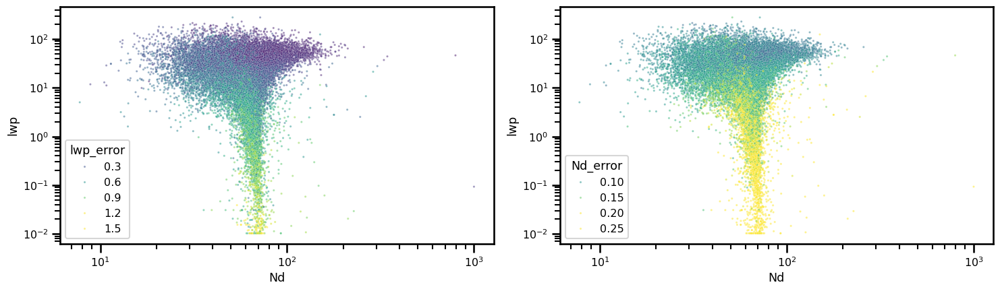

In [14]:
fig, ax = plt.subplots(1,2, figsize=(15,4.5))
sns.scatterplot(ax=ax[0], data=dffil, x='Nd', y='lwp', hue='lwp_error', palette='viridis', alpha=0.5, s=5, hue_norm=(0,1.2))
sns.scatterplot(ax=ax[1], data=dffil, x='Nd', y='lwp', hue='Nd_error', palette='viridis', alpha=0.5, s=5, hue_norm=(0,0.2))
for a in ax:
    a.set_xscale('log')
    a.set_yscale('log')
fig.tight_layout()

Text(0.5, 0, 'Nd error')

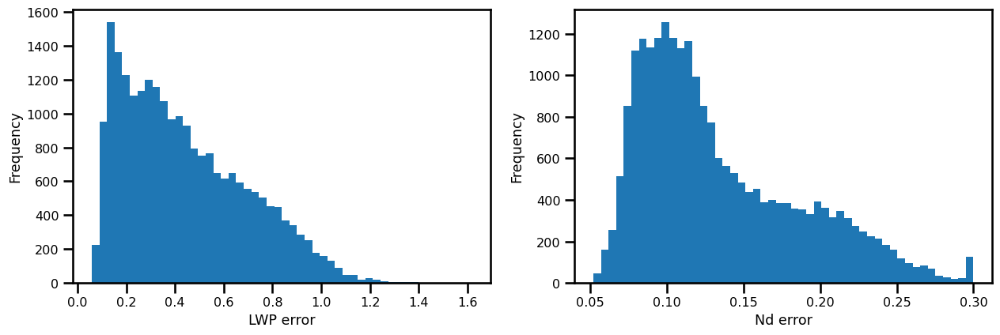

In [15]:
fig, ax = plt.subplots(1,2, figsize=(15,4.5))
dffil.lwp_error.plot.hist(ax=ax[0], bins=50)
dffil.Nd_error.plot.hist(ax=ax[1], bins=50)
ax[0].set_xlabel('LWP error')
ax[1].set_xlabel('Nd error')

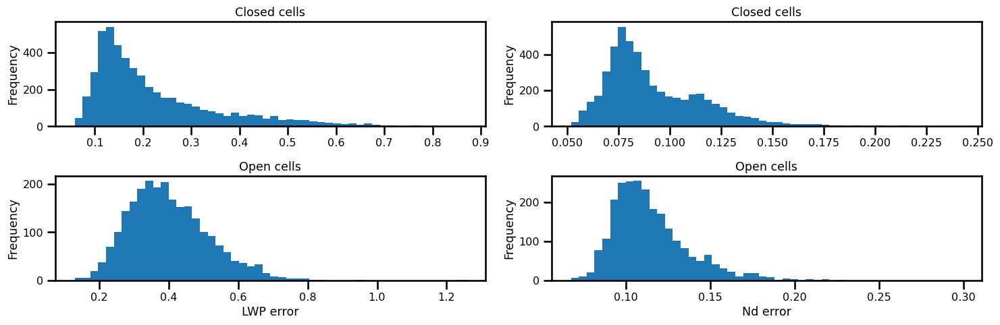

In [16]:
fig, ax = plt.subplots(2,2, figsize=(15,5))
dffil[dffil.cats == 1].lwp_error.plot.hist(ax=ax[0,0], bins=50)
dffil[dffil.cats == 1].Nd_error.plot.hist(ax=ax[0,1], bins=50)
dffil[dffil.cats == 2].lwp_error.plot.hist(ax=ax[1,0], bins=50)
dffil[dffil.cats == 2].Nd_error.plot.hist(ax=ax[1,1], bins=50)
ax[0,0].set_title('Closed cells')
ax[0,1].set_title('Closed cells')
ax[1,0].set_title('Open cells')
ax[1,1].set_title('Open cells')
ax[1,0].set_xlabel('LWP error')
ax[1,1].set_xlabel('Nd error')
fig.tight_layout()

LWP and Nd errors are small for closed and open cells. <br>
The largest error estimates are seen for suppressed cumulus cases (i.e. very small and thin clouds)

In [35]:
dffil['lwp_fil'] = dffil['lwp'].where((dffil.lwp_error <= 0.6) & (dffil.Nd_error <= 0.15))
dffil['Nd_fil'] = dffil['Nd'].where((dffil.lwp_error <= 0.6) & (dffil.Nd_error <= 0.15))
dffil['ER_fil'] = dffil['ER'].where((dffil.lwp_error <= 0.6) & (dffil.Nd_error <= 0.15))

In [36]:
dffil_1km['lwp_fil'] = dffil_1km['lwp'].where((dffil_1km.lwp_error <= 0.6) & (dffil_1km.Nd_error <= 0.15))
dffil_1km['Nd_fil'] = dffil_1km['Nd'].where((dffil_1km.lwp_error <= 0.6) & (dffil_1km.Nd_error <= 0.15))
dffil_1km['ER_fil'] = dffil_1km['ER'].where((dffil_1km.lwp_error <= 0.6) & (dffil_1km.Nd_error <= 0.15))

# Analysis

In [37]:
sns.set_context("talk", font_scale=1)
sns.set_style('white')
plt.rcParams['xtick.bottom'] = True
plt.rcParams['xtick.top'] = False
plt.rcParams['ytick.left'] = True
plt.rcParams['ytick.right'] = False

In [38]:
# get 6 distinct colors from the viridis colormap
cmap = matplotlib.cm.get_cmap('viridis', 6)
catcolors = [cmap(i) for i in range(cmap.N)]

#colors = ['#1f77b4', '#2ca02c', '#ff7f0e',  '#d62728', '#e377c2', '#8c564b', 'black']

line_styles = [(0, (3, 1, 1, 1)), '-', '--', '-.', (0,(3,1,1,1,1,1)), ':']

In [39]:
cats_names = {
    0: 'Solid Stratus',
    1: 'Closed MCC',
    2: 'Open MCC',
    3: 'Disorg. MCC',
    4: 'Clustered Cu',
    5: 'Suppr. Cu'
    }

palette_catscolors = {i: catcolors[i] for i in range(6)}
palette_catscolors[6] = 'lightgray'  # for unclassified

# when only closed and open cells are shown, we define the open cell colors to be a bit more different from the closed cell colors for better visibility
palette_catscolors[1] = 'steelblue'  # for closed MCC
catcolors[1] = 'steelblue'
palette_catscolors[2] = 'coral'  # for open MCC
catcolors[2] = 'coral'

In [40]:
from matplotlib.lines import Line2D

# Custom legend with line styles
legend_elements = [
    Line2D([0], [0], color=catcolors[i], lw=3, linestyle=line_styles[i], label=cats_names[i])
    for i in range(6)
]

In [41]:
def histplot_with_style(cluster_id, ax, data, x, bins, alpha=0.2, **kwargs):
    sns.histplot(
        ax=ax, data=data[data['cats'] == cluster_id], x=x, bins=bins,
        element='step', stat='probability', fill=True, alpha=alpha, lw=3, ls=line_styles[cluster_id], #lw=0, kde=True, line_kws={'ls':line_styles[cluster_id], 'lw':3},
        color=catcolors[cluster_id], 
        **kwargs
    )

## Number of samples

In [44]:
dffil.scene_id.unique()

array([    3,     4,    19, ..., 51855, 51859, 51860], shape=(23282,))

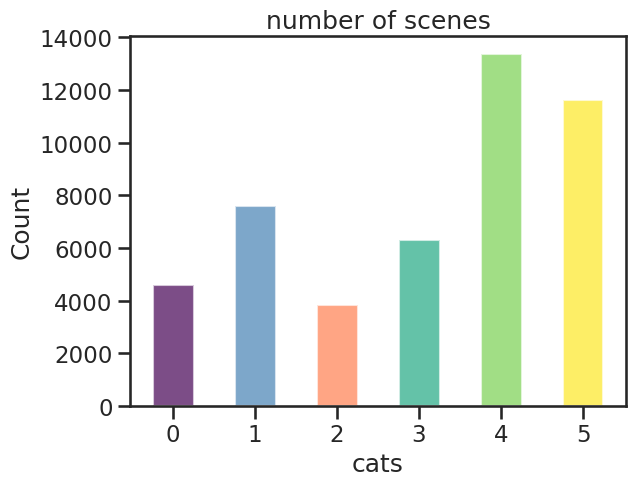

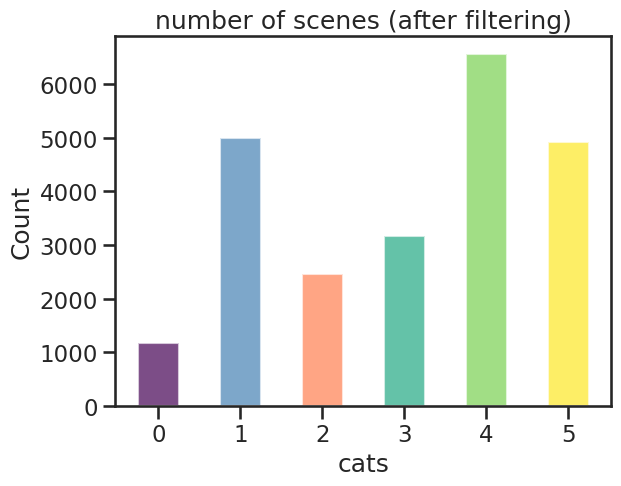

In [45]:
import matplotlib.pyplot as plt

cats = df.groupby('scene_id')['cats'].mean()
bins = np.arange(-0.25, 5.75, 0.5)
counts, edges = np.histogram(cats, bins=bins)
plt.figure()
for i in range(len(counts)):
    plt.bar(edges[i]+0.25, counts[i], width=0.5, color=catcolors[i//2], alpha=0.7)
plt.xlabel('cats')
plt.ylabel('Count')
plt.title('number of scenes')
plt.show()

cats = dffil.groupby('scene_id')['cats'].mean()
bins = np.arange(-0.25, 5.75, 0.5)
counts, edges = np.histogram(cats, bins=bins)
plt.figure()
for i in range(len(counts)):
    plt.bar(edges[i]+0.25, counts[i], width=0.5, color=catcolors[i//2], alpha=0.7)
plt.xlabel('cats')
plt.ylabel('Count')
plt.title('number of scenes (after filtering)')
plt.show()

## geographic distribution

In [14]:
from matplotlib import colors
from mpl_toolkits.basemap import Basemap

In [19]:
def bmap(ax=None, drawlines=True, llr=None, par_labs=[1, 0, 0, 0], mer_labs=[0, 0, 0, 1], 
         merspace=5, parspace=5, **kwargs):

    if ax is None:
        fig, ax = plt.subplots()

    lat_range = llr['lat']
    lon_range = llr['lon']
    
    if 'projection' not in kwargs.keys():
        kwargs['projection'] = 'cyl'
        kwargs['rsphere'] =(6378137.00, 6356752.3142)
    m = Basemap(llcrnrlon=lon_range[0], llcrnrlat=lat_range[0],
                urcrnrlon=lon_range[1],  urcrnrlat=lat_range[1],
                ax=ax, resolution='l', **kwargs)
    if drawlines:
        m.drawparallels(np.arange(-90., 90., parspace), labels=par_labs, fontsize=16)
        m.drawmeridians(np.arange(-180., 180., merspace), labels=mer_labs, fontsize=16)
    m.drawcoastlines()
    m.fillcontinents(color="white", lake_color="white")

    return m

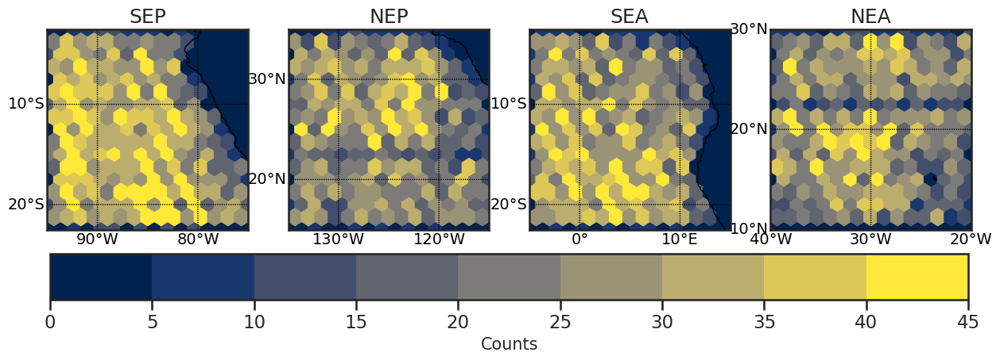

In [45]:
ticks = np.linspace(0, 50, 11)[:-1]
bnorm = colors.BoundaryNorm(boundaries=ticks, ncolors=256)
lnorm = colors.LogNorm(vmin=0.01, vmax=0.7)

fig, axs = plt.subplots(ncols=4, nrows=1, figsize=(15, 5))
axn = axs.flatten()
for i, ax in enumerate(axn):
    stratus_region_order = [2, 3, 0, 1]
    sr = stratus_region_order[i]
    plot_df = dffil[(dffil.stratus_region_index == sr)]
    stratus_region_names = {0:'SEA', 1:'NEA', 2:'SEP', 3:'NEP'}
    llr = stratus_regions[stratus_region_names[sr]]

    b = bmap(ax=ax, llr=llr, merspace=10, parspace=10)
    image = b.hexbin(plot_df['lon_mid'], plot_df['lat_mid'], gridsize=15, extent=(*llr['lon'], *llr['lat']), norm=bnorm, cmap='cividis')
    image.cmap.set_under('lightgrey')
    ax.set_title(stratus_region_names[sr])

plt.subplots_adjust(hspace=0.2, wspace=0.2)
cb = plt.colorbar(image, ax=axn, orientation='horizontal', pad=0.08)
cb.set_label("Counts", fontsize=15)

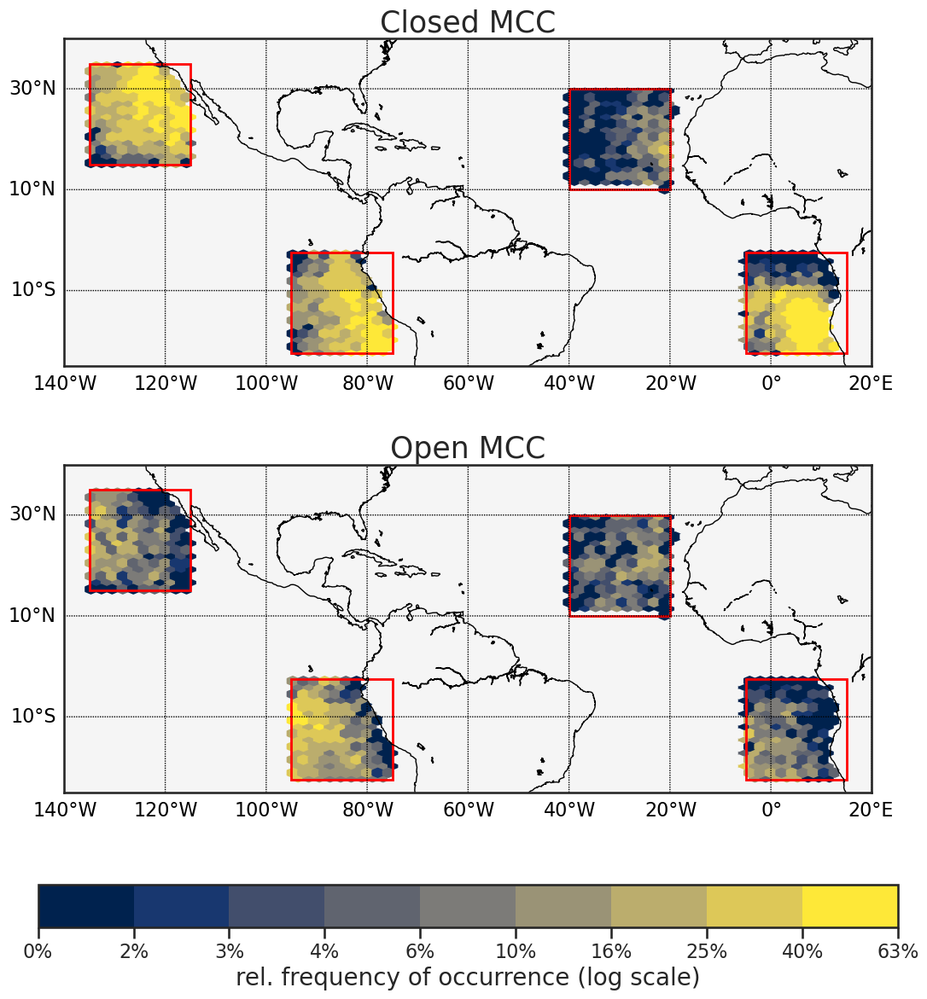

In [20]:
sns.set_context("talk", font_scale=1)

ticks = np.logspace(-2, 0, 11)[:-1]
ticks[0]=0
bnorm = colors.BoundaryNorm(boundaries=ticks, ncolors=256)

llr = {'lat': (-25, 40), 'lon': (-140, 20)}
# Calculate aspect ratio correction
lat_range = llr['lat'][1] - llr['lat'][0]
lon_range = llr['lon'][1] - llr['lon'][0]
aspect_ratio = lon_range / lat_range

# Adjust gridsize to account for the aspect ratio
gridsize=25
gridsize_x = int(gridsize * aspect_ratio) + 15
gridsize_y = gridsize
fig, ax = plt.subplots()
b = bmap(ax=ax, llr=llr)
plot_df = dffil
image = b.hexbin(plot_df['lon_mid'], plot_df['lat_mid'], gridsize=(gridsize_x, gridsize_y), extent=(*llr['lon'], *llr['lat']), norm=bnorm, cmap='cividis')
all_counts = image.get_array()+1
plt.close()

fig, axs = plt.subplots(ncols=1, nrows=2, figsize=(13, 14), sharex=True, sharey=True)
plt.suptitle(f'', fontsize=16)
axn = axs.flatten()
for i, ax in enumerate(axn):
    plot_df = dffil[(dffil['cats'] == i+1)]

    b = bmap(ax=ax, llr=llr, merspace=20, parspace=20)
    image = b.hexbin(plot_df['lon_mid'], plot_df['lat_mid'], gridsize=(gridsize_x, gridsize_y), extent=(*llr['lon'], *llr['lat']), norm=bnorm, cmap='cividis')
    normed_counts = image.get_array()/all_counts
    normed_counts[all_counts<5] = -1
    
    image.set_array(normed_counts)
    image.cmap.set_under('whitesmoke')
    ax.set_title(cats_names[i+1], fontsize=25)

    # draw rectangles around regions of interest
    # SEA
    rect1 = mpatches.Rectangle((stratus_regions['SEA']['lon'][0], stratus_regions['SEA']['lat'][0]), 20, 20, linewidth=2, edgecolor='red', facecolor='none')
    ax.add_patch(rect1)
    # NEA
    rect2 = mpatches.Rectangle((stratus_regions['NEA']['lon'][0], stratus_regions['NEA']['lat'][0]), 20, 20, linewidth=2, edgecolor='red', facecolor='none')
    ax.add_patch(rect2) 
    # SEP
    rect3 = mpatches.Rectangle((stratus_regions['SEP']['lon'][0], stratus_regions['SEP']['lat'][0]), 20, 20, linewidth=2, edgecolor='red', facecolor='none')
    ax.add_patch(rect3)
    # NEP
    rect4 = mpatches.Rectangle((stratus_regions['NEP']['lon'][0], stratus_regions['NEP']['lat'][0]), 20, 20, linewidth=2, edgecolor='red', facecolor='none')
    ax.add_patch(rect4)

plt.subplots_adjust(hspace=0.3, wspace=0.25)
cb = plt.colorbar(image, ax=axn, ticks=ticks, orientation='horizontal', pad=0.1, fraction=0.08)
cb.set_ticklabels([f"{i:0.0%}" for i in ticks], fontsize=16)
cb.set_label("rel. frequency of occurrence (log scale)", fontsize=20)
plt.savefig('./figures/geographical_distribution_closed_open_cells.png', dpi=300)
plt.show()

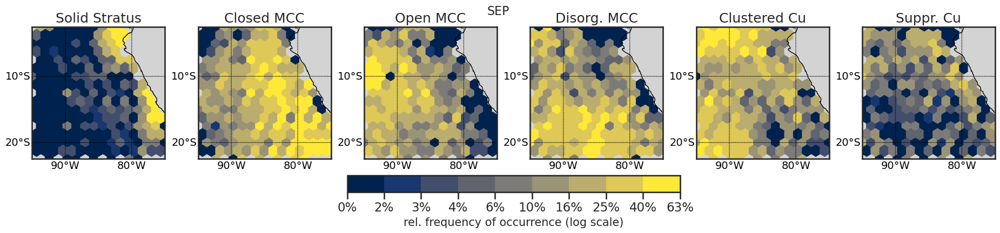

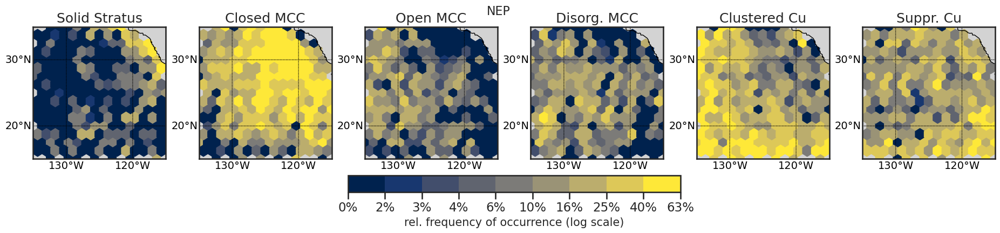

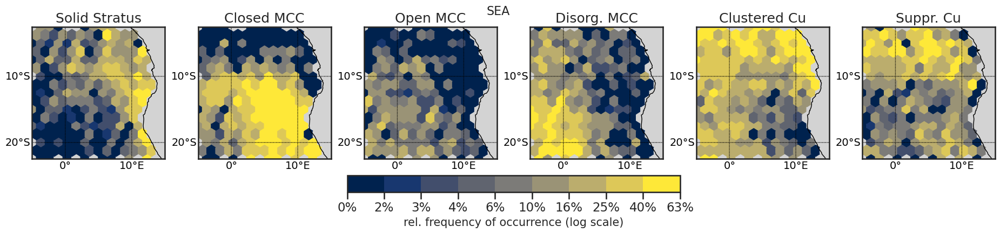

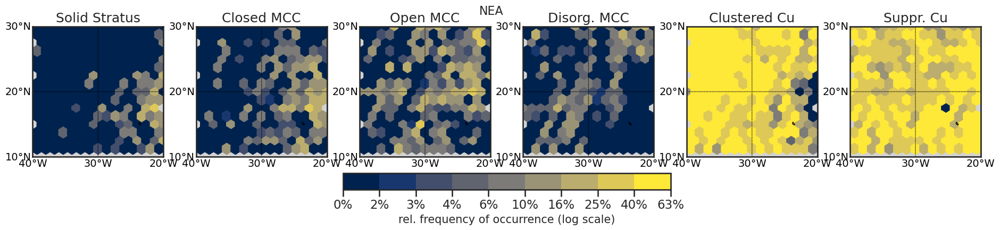

In [46]:
#ticks = np.linspace(0, 1, 11)[:-1]
#bnorm = colors.BoundaryNorm(boundaries=ticks, ncolors=256)
#lnorm = colors.LogNorm(vmin=0.01, vmax=0.7)
ticks = np.logspace(-2, 0, 11)[:-1]
ticks[0]=0
bnorm = colors.BoundaryNorm(boundaries=ticks, ncolors=256)

for j in range(4):
    stratus_region_order = [2, 3, 0, 1]
    sr = stratus_region_order[j]
    stratus_region_names = {0:'SEA', 1:'NEA', 2:'SEP', 3:'NEP'}
    llr = stratus_regions[stratus_region_names[sr]]

    gridsize = 15
    fig, ax = plt.subplots()
    b = bmap(ax=ax, llr=llr)
    plot_df = dffil[(dffil.stratus_region_index == sr)]
    image = b.hexbin(plot_df['lon_mid'], plot_df['lat_mid'], gridsize=gridsize, extent=(*llr['lon'], *llr['lat']), norm=bnorm, cmap='cividis')
    all_counts = image.get_array()+1
    plt.close()

    fig, axs = plt.subplots(ncols=6, nrows=1, figsize=(23, 4), sharex=True, sharey=True)
    plt.suptitle(f'{stratus_region_names[sr]}', fontsize=16)
    axn = axs.flatten()
    for i, ax in enumerate(axn):
        plot_df = dffil[(dffil.stratus_region_index == sr) & (dffil['cats'] == i)]

        b = bmap(ax=ax, llr=llr, merspace=10, parspace=10)
        image = b.hexbin(plot_df['lon_mid'], plot_df['lat_mid'], gridsize=gridsize, extent=(*llr['lon'], *llr['lat']), norm=bnorm, cmap='cividis')
        normed_counts = image.get_array()/all_counts
        normed_counts[all_counts<5] = -1
        
        image.set_array(normed_counts)
        image.cmap.set_under('lightgrey')
        ax.set_title(cats_names[i])

    plt.subplots_adjust(hspace=0.5, wspace=0.25)
    cb = plt.colorbar(image, ax=axn, ticks=ticks, orientation='horizontal', pad=0.1, fraction=0.1)
    cb.set_ticklabels([f"{i:0.0%}" for i in ticks])
    cb.set_label("rel. frequency of occurrence (log scale)", fontsize=15)
    plt.show()

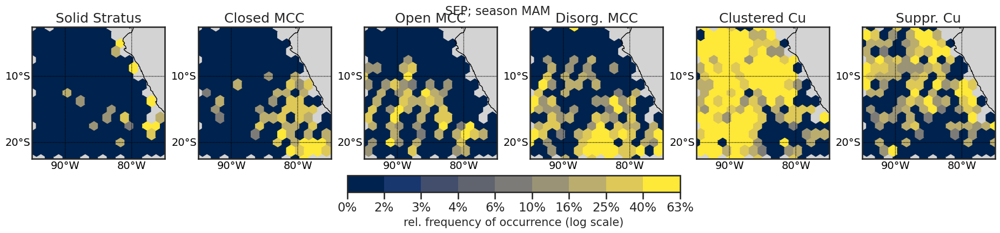

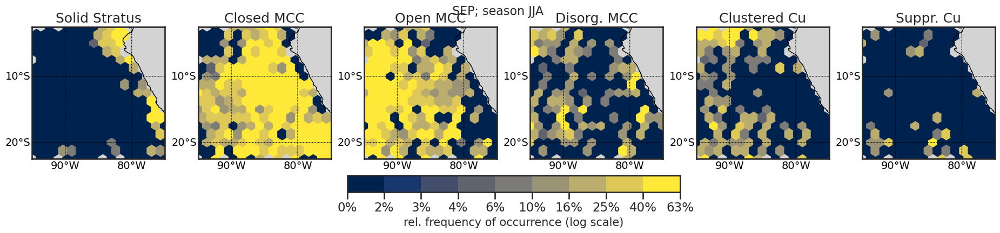

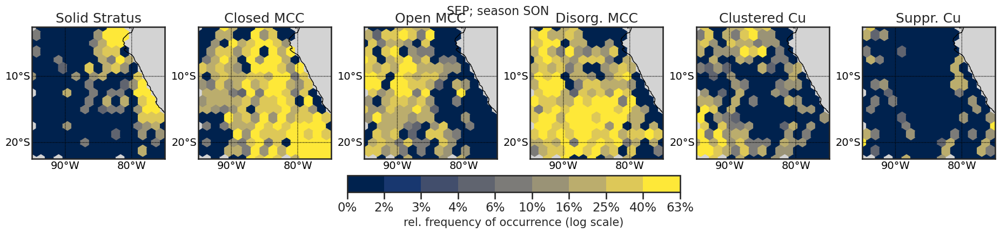

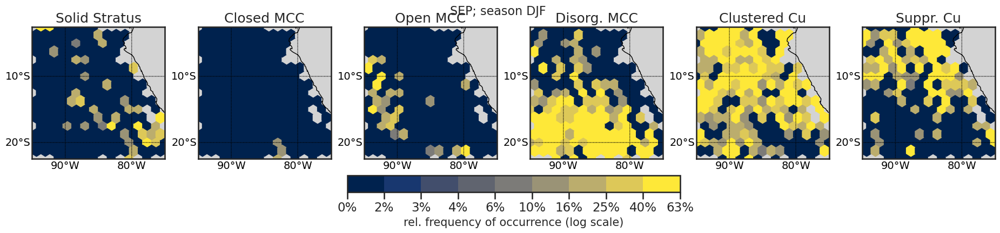

In [47]:
#ticks = np.linspace(0, 1, 11)[:-1]
#bnorm = colors.BoundaryNorm(boundaries=ticks, ncolors=256)
#lnorm = colors.LogNorm(vmin=0.01, vmax=0.7)
ticks = np.logspace(-2, 0, 11)[:-1]
ticks[0]=0
bnorm = colors.BoundaryNorm(boundaries=ticks, ncolors=256)

for j in range(4):
    for season in ['MAM', 'JJA', 'SON', 'DJF']:
        stratus_region_order = [2, 3, 0, 1]
        sr = stratus_region_order[j]
        stratus_region_names = {0:'SEA', 1:'NEA', 2:'SEP', 3:'NEP'}
        llr = stratus_regions[stratus_region_names[sr]]

        if season == 'JJA':
            dffil_season = dffil[(dffil.time_mid.dt.month.isin([6,7,8]))]
        elif season == 'MAM':
            dffil_season = dffil[(dffil.time_mid.dt.month.isin([3,4,5]))]
        elif season == 'SON':
            dffil_season = dffil[(dffil.time_mid.dt.month.isin([9,10,11]))]
        elif season == 'DJF':
            dffil_season = dffil[(dffil.time_mid.dt.month.isin([12,1,2]))]

        gridsize = 15
        fig, ax = plt.subplots()
        b = bmap(ax=ax, llr=llr)
        plot_df = dffil_season[(dffil_season.stratus_region_index == sr)]
        image = b.hexbin(plot_df['lon_mid'], plot_df['lat_mid'], gridsize=gridsize, extent=(*llr['lon'], *llr['lat']), norm=bnorm, cmap='cividis')
        all_counts = image.get_array()+1
        plt.close()

        fig, axs = plt.subplots(ncols=6, nrows=1, figsize=(23, 4), sharex=True, sharey=True)
        plt.suptitle(f'{stratus_region_names[sr]}; season {season}', fontsize=16)
        axn = axs.flatten()
        for i, ax in enumerate(axn):
            plot_df = dffil_season[(dffil_season.stratus_region_index == sr) & (dffil_season['cats'] == i)]

            b = bmap(ax=ax, llr=llr, merspace=10, parspace=10)
            image = b.hexbin(plot_df['lon_mid'], plot_df['lat_mid'], gridsize=gridsize, extent=(*llr['lon'], *llr['lat']), norm=bnorm, cmap='cividis')
            normed_counts = image.get_array()/all_counts
            normed_counts[all_counts<2] = -1
            
            image.set_array(normed_counts)
            image.cmap.set_under('lightgrey')
            ax.set_title(cats_names[i])

        plt.subplots_adjust(hspace=0.5, wspace=0.25)
        cb = plt.colorbar(image, ax=axn, ticks=ticks, orientation='horizontal', pad=0.1, fraction=0.1)
        cb.set_ticklabels([f"{i:0.0%}" for i in ticks])
        cb.set_label("rel. frequency of occurrence (log scale)", fontsize=15)
        plt.show()
    break

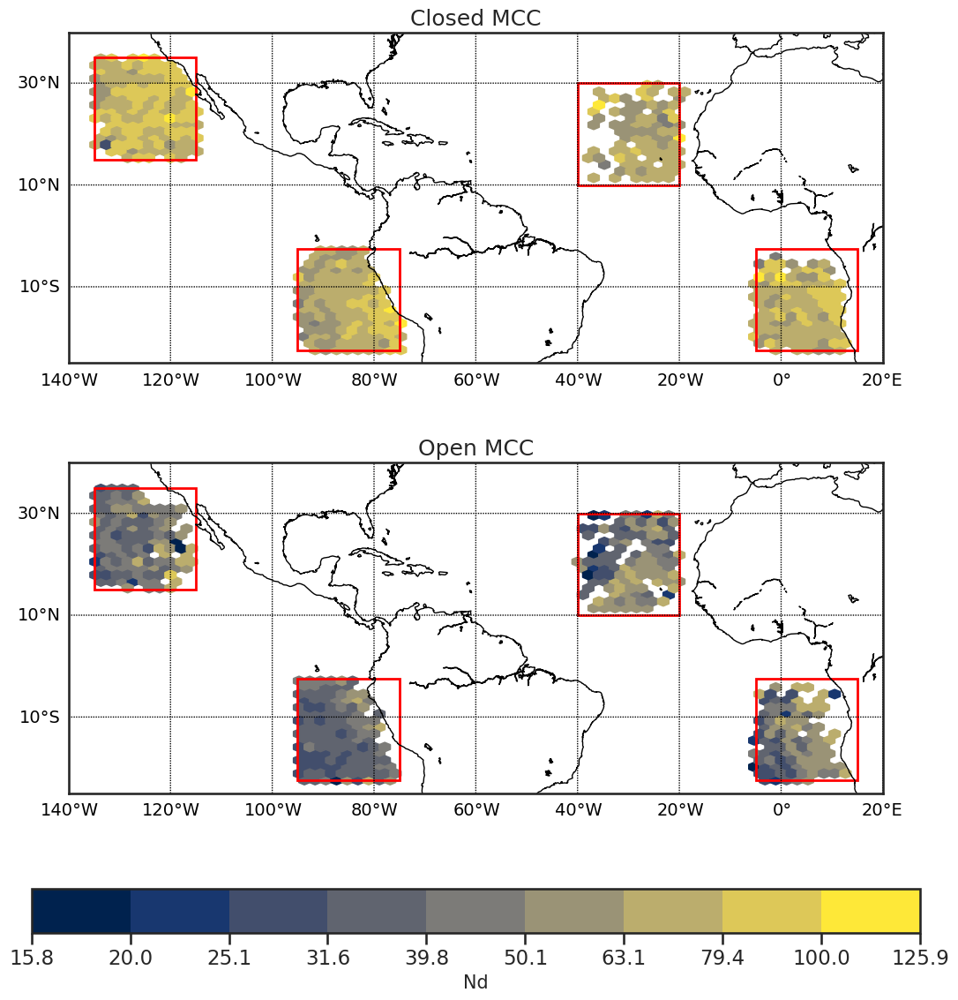

In [127]:
ticks = np.logspace(1.2, 2.2, 11)[:-1]
bnorm = colors.BoundaryNorm(boundaries=ticks, ncolors=256)

llr = {'lat': (-25, 40), 'lon': (-140, 20)}
# Calculate aspect ratio correction
lat_range = llr['lat'][1] - llr['lat'][0]
lon_range = llr['lon'][1] - llr['lon'][0]
aspect_ratio = lon_range / lat_range

# Adjust gridsize to account for the aspect ratio
gridsize=25
gridsize_x = int(gridsize * aspect_ratio) + 15
gridsize_y = gridsize

fig, axs = plt.subplots(ncols=1, nrows=2, figsize=(13, 14), sharex=True, sharey=True)
plt.suptitle(f'', fontsize=16)
axn = axs.flatten()
for i, ax in enumerate(axn):
    plot_df = dffil_1km[(dffil_1km['cats'] == i+1)]

    b = bmap(ax=ax, llr=llr, merspace=20, parspace=20)
    image = b.hexbin(plot_df['lon_mid'], plot_df['lat_mid'], C=plot_df['Nd_fil'], 
                     gridsize=(gridsize_x, gridsize_y), extent=(*llr['lon'], *llr['lat']), 
                     norm=bnorm, cmap='cividis')
    ax.set_title(cats_names[i+1])

    # draw rectangles around regions of interest
    # SEA
    rect1 = mpatches.Rectangle((stratus_regions['SEA']['lon'][0], stratus_regions['SEA']['lat'][0]), 20, 20, linewidth=2, edgecolor='red', facecolor='none')
    ax.add_patch(rect1)
    # NEA
    rect2 = mpatches.Rectangle((stratus_regions['NEA']['lon'][0], stratus_regions['NEA']['lat'][0]), 20, 20, linewidth=2, edgecolor='red', facecolor='none')
    ax.add_patch(rect2) 
    # SEP
    rect3 = mpatches.Rectangle((stratus_regions['SEP']['lon'][0], stratus_regions['SEP']['lat'][0]), 20, 20, linewidth=2, edgecolor='red', facecolor='none')
    ax.add_patch(rect3)
    # NEP
    rect4 = mpatches.Rectangle((stratus_regions['NEP']['lon'][0], stratus_regions['NEP']['lat'][0]), 20, 20, linewidth=2, edgecolor='red', facecolor='none')
    ax.add_patch(rect4)

plt.subplots_adjust(hspace=0.3, wspace=0.25)
cb = plt.colorbar(image, ax=axn, ticks=ticks, orientation='horizontal', pad=0.1, fraction=0.1)
#cb.set_ticklabels([f"{i:0.0%}" for i in ticks])
cb.set_label("Nd", fontsize=15)
plt.show()

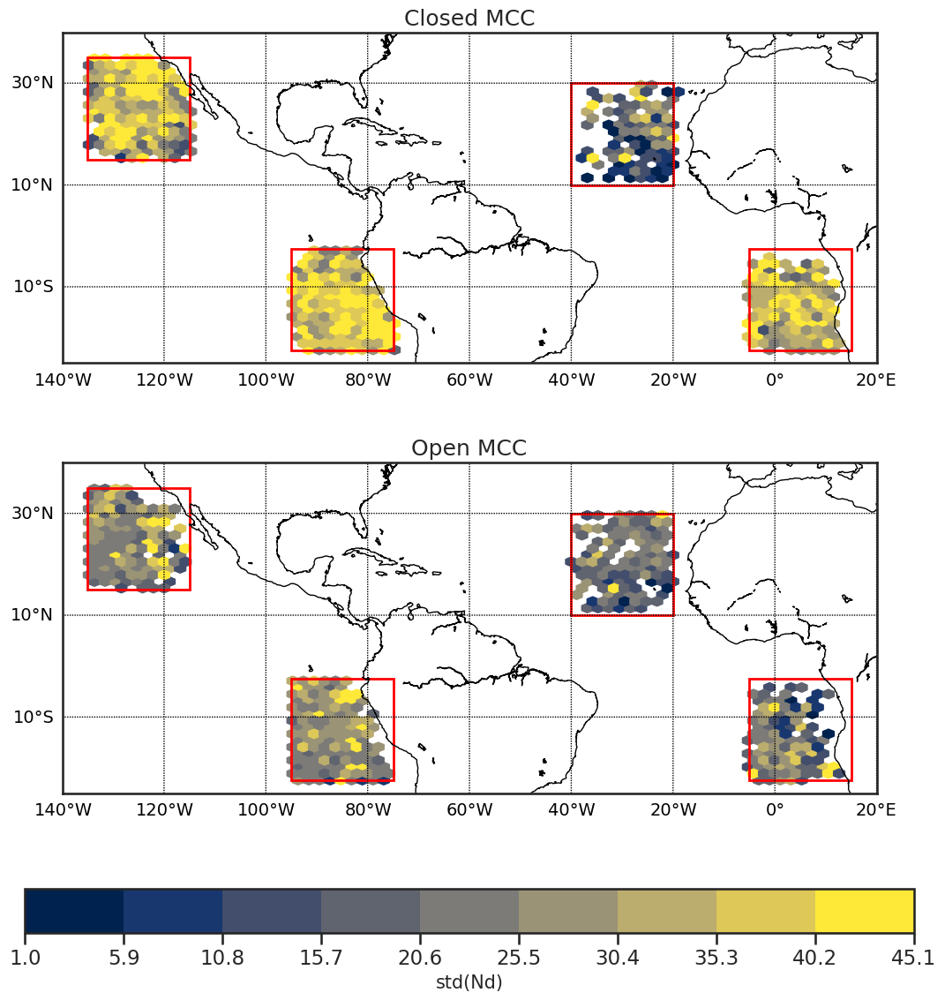

In [126]:
ticks = np.linspace(1, 50, 11)[:-1]
bnorm = colors.BoundaryNorm(boundaries=ticks, ncolors=256)

llr = {'lat': (-25, 40), 'lon': (-140, 20)}
# Calculate aspect ratio correction
lat_range = llr['lat'][1] - llr['lat'][0]
lon_range = llr['lon'][1] - llr['lon'][0]
aspect_ratio = lon_range / lat_range

# Adjust gridsize to account for the aspect ratio
gridsize=25
gridsize_x = int(gridsize * aspect_ratio) + 15
gridsize_y = gridsize

fig, axs = plt.subplots(ncols=1, nrows=2, figsize=(13, 14), sharex=True, sharey=True)
plt.suptitle(f'', fontsize=16)
axn = axs.flatten()
for i, ax in enumerate(axn):
    plot_df = dffil_1km[(dffil_1km['cats'] == i+1)]

    b = bmap(ax=ax, llr=llr, merspace=20, parspace=20)
    image = b.hexbin(plot_df['lon_mid'], plot_df['lat_mid'], C=plot_df['Nd_fil'], 
                     reduce_C_function=np.std,
                     gridsize=(gridsize_x, gridsize_y), extent=(*llr['lon'], *llr['lat']), 
                     norm=bnorm, cmap='cividis')
    ax.set_title(cats_names[i+1])

    # draw rectangles around regions of interest
    # SEA
    rect1 = mpatches.Rectangle((stratus_regions['SEA']['lon'][0], stratus_regions['SEA']['lat'][0]), 20, 20, linewidth=2, edgecolor='red', facecolor='none')
    ax.add_patch(rect1)
    # NEA
    rect2 = mpatches.Rectangle((stratus_regions['NEA']['lon'][0], stratus_regions['NEA']['lat'][0]), 20, 20, linewidth=2, edgecolor='red', facecolor='none')
    ax.add_patch(rect2) 
    # SEP
    rect3 = mpatches.Rectangle((stratus_regions['SEP']['lon'][0], stratus_regions['SEP']['lat'][0]), 20, 20, linewidth=2, edgecolor='red', facecolor='none')
    ax.add_patch(rect3)
    # NEP
    rect4 = mpatches.Rectangle((stratus_regions['NEP']['lon'][0], stratus_regions['NEP']['lat'][0]), 20, 20, linewidth=2, edgecolor='red', facecolor='none')
    ax.add_patch(rect4)

plt.subplots_adjust(hspace=0.3, wspace=0.25)
cb = plt.colorbar(image, ax=axn, ticks=ticks, orientation='horizontal', pad=0.1, fraction=0.1)
#cb.set_ticklabels([f"{i:0.0%}" for i in ticks])
cb.set_label("std(Nd)", fontsize=15)
plt.show()

## mesoscale structure

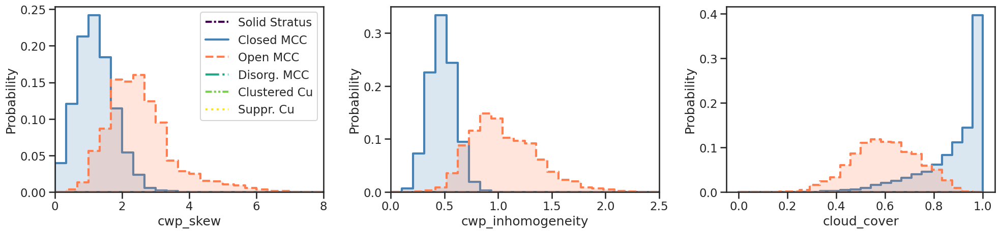

In [46]:
cloud_regime = 'cats'
# check how the clusters relate to the M-COP variables
fig, ax = plt.subplots(1,3, figsize=(20, 5))
for i in [1,2]:

    histplot_with_style(i, ax[0], dffil, 'cwp_skew', np.linspace(0,8,25))
    histplot_with_style(i, ax[1], dffil, 'cwp_inhomogeneity', np.linspace(0,2.5,25))
    histplot_with_style(i, ax[2], dffil, 'cloud_cover', np.linspace(0,1,25))

ax[0].legend(handles=legend_elements)
ax[0].set_xlim(0,8)
ax[1].set_xlim(0,2.5)
fig.tight_layout()

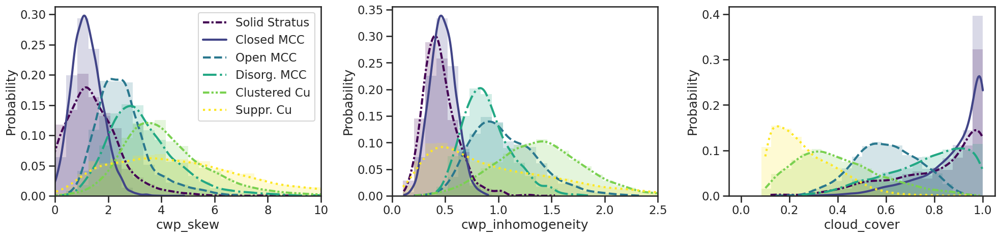

In [ ]:
cloud_regime = 'cats'
# check how the clusters relate to the M-COP variables
fig, ax = plt.subplots(1,3, figsize=(20, 5))
for i in [0,1,2,3,4,5]: #6

    histplot_with_style(i, ax[0], dffil, 'cwp_skew', np.linspace(0,10,25))
    histplot_with_style(i, ax[1], dffil, 'cwp_inhomogeneity', np.linspace(0,2.5,25))
    histplot_with_style(i, ax[2], dffil, 'cloud_cover', np.linspace(0,1,25))

ax[0].legend(handles=legend_elements)
ax[0].set_xlim(0,10)
ax[1].set_xlim(0,2.5)
fig.tight_layout()

## vertical structure

### histograms

In [79]:
dffil['H'] = (np.abs(dffil['cth'] - dffil['cbh']) + 1) * 100 # transform to meters
#dffil['daytime'] = dffil['daytime'].astype(int)

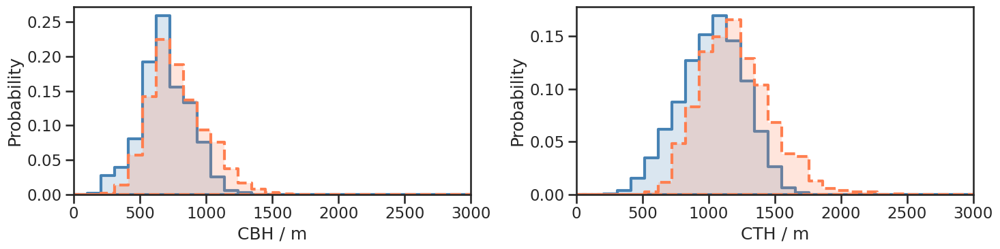

In [ ]:
fig, ax = plt.subplots(1,2, figsize=(15, 4))
for i in [1,2]: #[0,1,2,3,4,5]: 
    histplot_with_style(i, ax[0], dffil, 'cbh_m', np.linspace(0,3000,30), kde_kws={'bw_adjust':2})
    histplot_with_style(i, ax[1], dffil, 'cth_m', np.linspace(0,3000,30), kde_kws={'bw_adjust':2})
ax[0].set_xlim(0,3000)
ax[1].set_xlim(0,3000)
ax[0].set_xlabel('CBH / m')
ax[1].set_xlabel('CTH / m')
#ax[0].legend(handles=legend_elements)
fig.tight_layout()

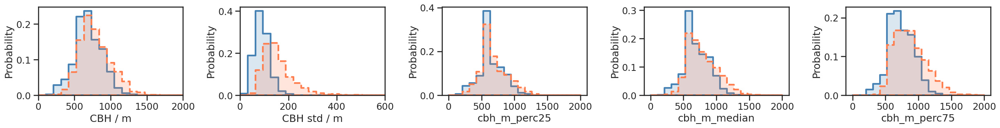

In [86]:
fig, ax = plt.subplots(1,5, figsize=(25, 3.5))
for i in [1,2]: #[0,1,2,3,4,5]: 
    histplot_with_style(i, ax[0], dffil, 'cbh_m', np.linspace(0,2000,20), kde_kws={'bw_adjust':2})
    histplot_with_style(i, ax[1], dffil, 'cbh_m_std', np.linspace(0,600,20), kde_kws={'bw_adjust':2})
    histplot_with_style(i, ax[2], dffil, 'cbh_m_perc25', np.linspace(0,2000,20), kde_kws={'bw_adjust':2})
    histplot_with_style(i, ax[3], dffil, 'cbh_m_median', np.linspace(0,2000,20), kde_kws={'bw_adjust':2})
    histplot_with_style(i, ax[4], dffil, 'cbh_m_perc75', np.linspace(0,2000,20), kde_kws={'bw_adjust':2})
ax[0].set_xlim(0,2000)
ax[1].set_xlim(0,600)
ax[0].set_xlabel('CBH / m')
ax[1].set_xlabel('CBH std / m')
#ax[0].legend(handles=legend_elements)
fig.tight_layout()

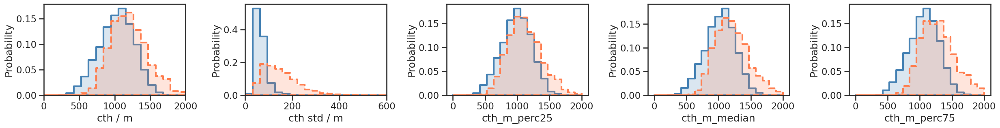

In [85]:
fig, ax = plt.subplots(1,5, figsize=(25, 3.5))
for i in [1,2]: #[0,1,2,3,4,5]: 
    histplot_with_style(i, ax[0], dffil, 'cth_m', np.linspace(0,2000,20), kde_kws={'bw_adjust':2})
    histplot_with_style(i, ax[1], dffil, 'cth_m_std', np.linspace(0,600,20), kde_kws={'bw_adjust':2})
    histplot_with_style(i, ax[2], dffil, 'cth_m_perc25', np.linspace(0,2000,20), kde_kws={'bw_adjust':2})
    histplot_with_style(i, ax[3], dffil, 'cth_m_median', np.linspace(0,2000,20), kde_kws={'bw_adjust':2})
    histplot_with_style(i, ax[4], dffil, 'cth_m_perc75', np.linspace(0,2000,20), kde_kws={'bw_adjust':2})
ax[0].set_xlim(0,2000)
ax[1].set_xlim(0,600)
ax[0].set_xlabel('cth / m')
ax[1].set_xlabel('cth std / m')
#ax[0].legend(handles=legend_elements)
fig.tight_layout()

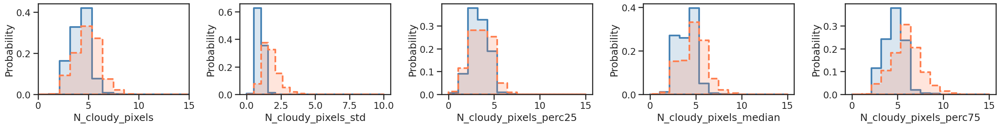

In [83]:
fig, ax = plt.subplots(1,5, figsize=(25, 3.5))
for i in [1,2]: #[0,1,2,3,4,5]: 
    histplot_with_style(i, ax[0], dffil, 'N_cloudy_pixels', np.linspace(0,15,15), kde_kws={'bw_adjust':2})
    histplot_with_style(i, ax[1], dffil, 'N_cloudy_pixels_std', np.linspace(0,10,20), kde_kws={'bw_adjust':2})
    histplot_with_style(i, ax[2], dffil, 'N_cloudy_pixels_perc25', np.linspace(0,15,15), kde_kws={'bw_adjust':2})
    histplot_with_style(i, ax[3], dffil, 'N_cloudy_pixels_median', np.linspace(0,15,15), kde_kws={'bw_adjust':2})
    histplot_with_style(i, ax[4], dffil, 'N_cloudy_pixels_perc75', np.linspace(0,15,15), kde_kws={'bw_adjust':2})
ax[0].set_xlim(0,15)
ax[0].set_xlabel('N_cloudy_pixels')
ax[1].set_xlabel('N_cloudy_pixels_std')
#ax[0].legend(handles=legend_elements)
fig.tight_layout()

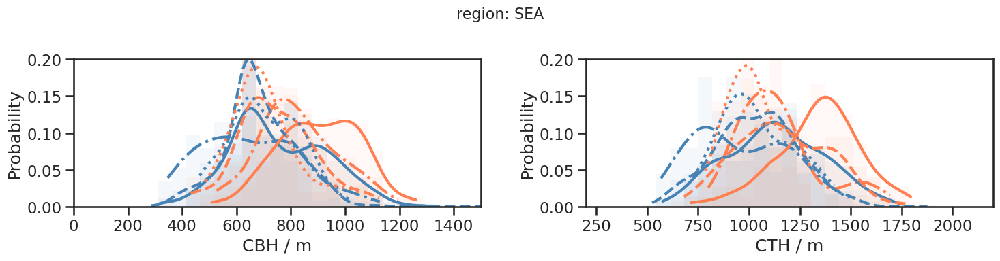

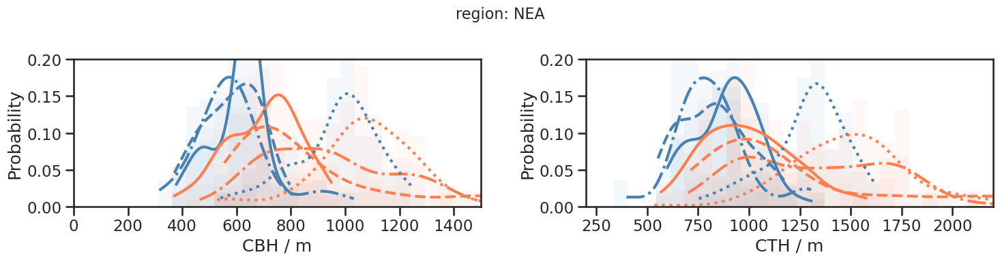

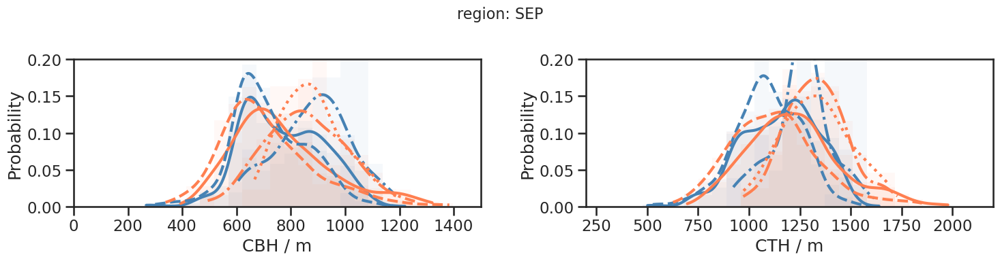

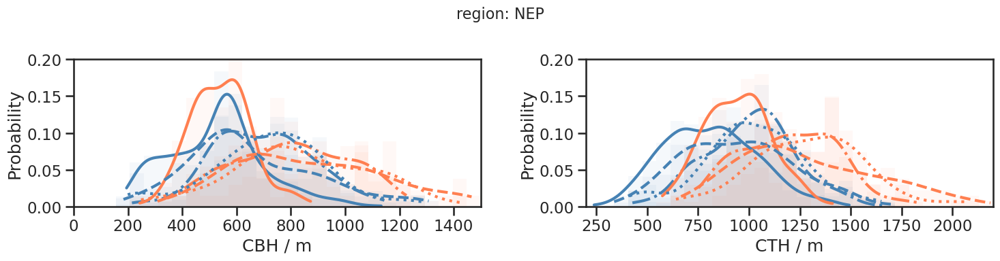

In [146]:
for region in [0,1,2,3]:

    fig, ax = plt.subplots(1,2, figsize=(15, 4))
    fig.suptitle(f'region: {stratus_region_names[region]}', fontsize=16)
    for season in ['MAM', 'JJA', 'SON', 'DJF']:
        if season == 'JJA':
            dffil_season = dffil[(dffil.stratus_region_index==region) &(dffil.time_mid.dt.month.isin([6,7,8]))]
            ls = '-'
        elif season == 'MAM':
            dffil_season = dffil[(dffil.stratus_region_index==region) &(dffil.time_mid.dt.month.isin([3,4,5]))]
            ls = '-.'
        elif season == 'SON':
            dffil_season = dffil[(dffil.stratus_region_index==region) &(dffil.time_mid.dt.month.isin([9,10,11]))]
            ls = '--'
        elif season == 'DJF':
            dffil_season = dffil[(dffil.stratus_region_index==region) &(dffil.time_mid.dt.month.isin([12,1,2]))]
            ls = ':'
        colors_ex = ['steelblue', 'coral']
        for i in [1,2]: #[0,1,2,3,4,5]: 
            sns.histplot(
                ax=ax[0], data=dffil_season[dffil_season['cats'] == i], x='cbh_m', bins=np.linspace(0,1500,30),
                element='step', stat='probability', fill=True, alpha=0.05, lw=0, kde=True, color=colors_ex[i-1], line_kws={'ls':ls, 'lw':3}
            )
            sns.histplot(
                ax=ax[1], data=dffil_season[dffil_season['cats'] == i], x='cth_m', bins=np.linspace(200,2200,30),
                element='step', stat='probability', fill=True, alpha=0.05, lw=0, kde=True, color=colors_ex[i-1], line_kws={'ls':ls, 'lw':3}
            )
    ax[0].set_xlim(0,1500)
    ax[1].set_xlim(200,2200)
    ax[0].set_ylim(0,0.2)
    ax[1].set_ylim(0,0.2)
    ax[0].set_xlabel('CBH / m')
    ax[1].set_xlabel('CTH / m')
    #ax[0].legend(handles=legend_elements)
    fig.tight_layout()
    plt.show()  

### CTH stratified by lon

Text(0.5, 1.0, 'Mean cbh_m given lon_normed for different cloud categories')

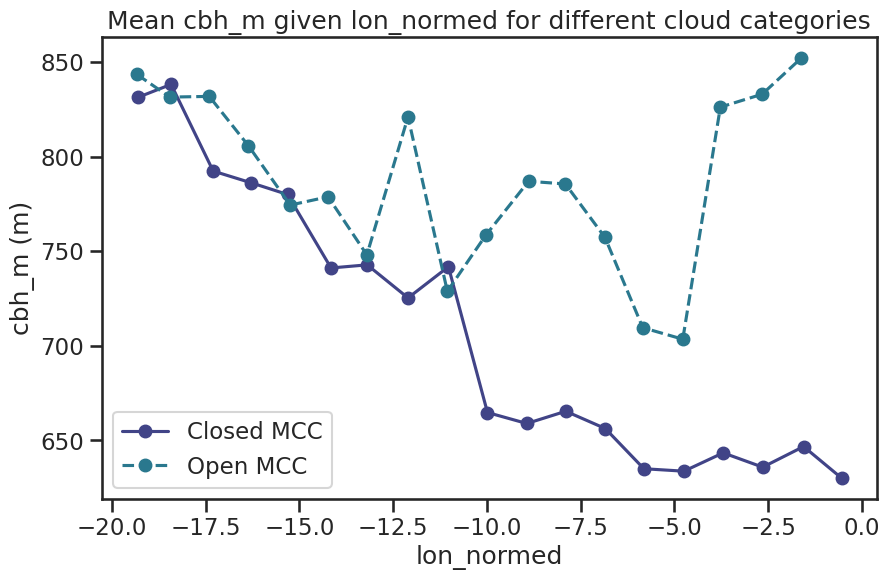

In [ ]:
fig, axs = plt.subplots(1,1,figsize=(10,6))
for i in [1,2]:
    tmp = dffil[(dffil.cats==i)]
    tmp['lon_normed'] = np.where(tmp.stratus_region_index == 0, tmp.lon_mid - stratus_regions[stratus_region_names[0]]['lon'][1], 
         np.where(tmp.stratus_region_index == 1, tmp.lon_mid - stratus_regions[stratus_region_names[1]]['lon'][1], 
                  np.where(tmp.stratus_region_index == 2, tmp.lon_mid - stratus_regions[stratus_region_names[2]]['lon'][1], 
                           np.where(tmp.stratus_region_index == 3, tmp.lon_mid - stratus_regions[stratus_region_names[3]]['lon'][1], np.nan))))
    cbh_m_given_lon_mid = tmp[['lon_normed','cbh_m']].groupby(pd.cut(tmp['lon_normed'], np.linspace(-20,0,20))).mean()
    cbh_m_given_lon_mid['size'] = tmp.groupby(pd.cut(tmp['lon_normed'], np.linspace(-20,0,20))).size()
    cbh_m_given_lon_mid['cbh_m'] = cbh_m_given_lon_mid['cbh_m'].where(cbh_m_given_lon_mid['size'] >= 10, np.nan)
    cbh_m_given_lon_mid.plot(y='cbh_m', x='lon_normed', logy=False, logx=False,marker='o', ax=axs, label=cats_names[i], color=catcolors[i], linestyle=line_styles[i])
    # rotate xlabels and round to 1 decimal place
    #plt.xticks(rotation=45)
#plt.ylim(-10,160)
plt.xlabel('lon_normed')
plt.ylabel('cbh_m (m)')
plt.title('Mean cbh_m given lon_normed for different cloud categories')

Text(0.5, 1.0, 'Mean cth_m given lon_normed for different cloud categories')

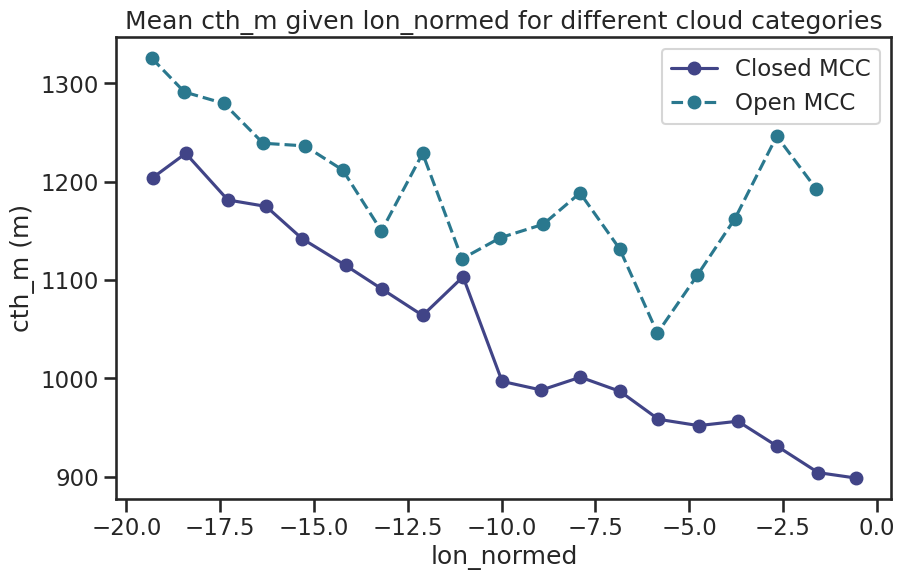

In [ ]:
fig, axs = plt.subplots(1,1,figsize=(10,6))
for i in [1,2]:
    tmp = dffil[(dffil.cats==i)]
    tmp['lon_normed'] = np.where(tmp.stratus_region_index == 0, tmp.lon_mid - stratus_regions[stratus_region_names[0]]['lon'][1], 
         np.where(tmp.stratus_region_index == 1, tmp.lon_mid - stratus_regions[stratus_region_names[1]]['lon'][1], 
                  np.where(tmp.stratus_region_index == 2, tmp.lon_mid - stratus_regions[stratus_region_names[2]]['lon'][1], 
                           np.where(tmp.stratus_region_index == 3, tmp.lon_mid - stratus_regions[stratus_region_names[3]]['lon'][1], np.nan))))
    cth_m_given_lon_mid = tmp[['lon_normed','cth_m']].groupby(pd.cut(tmp['lon_normed'], np.linspace(-20,0,20))).mean()
    cth_m_given_lon_mid['size'] = tmp.groupby(pd.cut(tmp['lon_normed'], np.linspace(-20,0,20))).size()
    cth_m_given_lon_mid['cth_m'] = cth_m_given_lon_mid['cth_m'].where(cth_m_given_lon_mid['size'] >= 10, np.nan)
    cth_m_given_lon_mid.plot(y='cth_m', x='lon_normed', logy=False, logx=False,marker='o', ax=axs, label=cats_names[i], color=catcolors[i], linestyle=line_styles[i])
    # rotate xlabels and round to 1 decimal place
    #plt.xticks(rotation=45)
#plt.ylim(-10,160)
plt.xlabel('lon_normed')
plt.ylabel('cth_m (m)')
plt.title('Mean cth_m given lon_normed for different cloud categories')

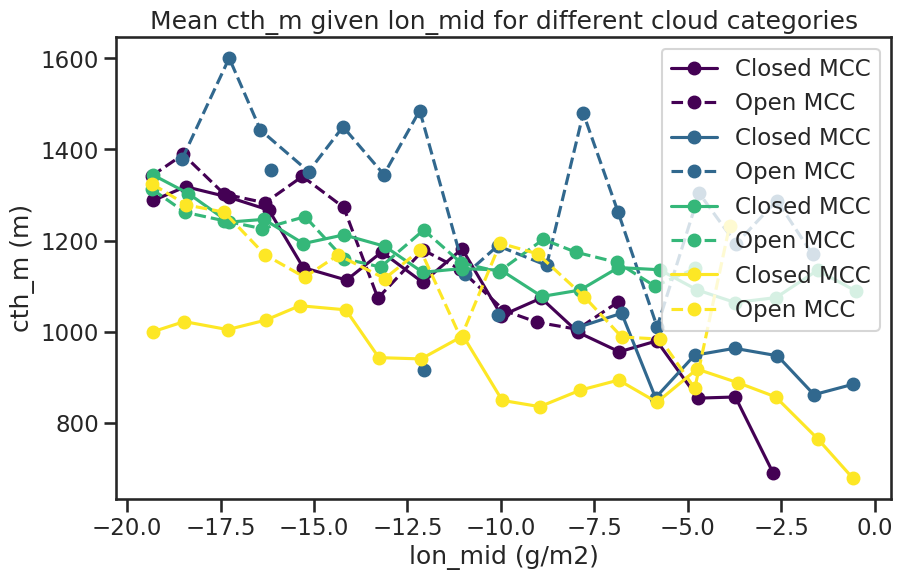

In [ ]:
fig, axs = plt.subplots(1,1,figsize=(10,6))
for sr in [0,1,2,3]:
    color = plt.cm.viridis(sr / 3)
    for i in [1,2]:
        tmp = dffil[(dffil.cats==i) & (dffil.stratus_region_index == sr)]
        tmp['lon_diff'] = tmp['lon_mid'] - stratus_regions[stratus_region_names[sr]]['lon'][1]
        cth_m_given_lon_mid = tmp[['lon_diff','cth_m']].groupby(pd.cut(tmp['lon_diff'], np.linspace(-20,0,20))).mean()
        cth_m_given_lon_mid['size'] = tmp.groupby(pd.cut(tmp['lon_diff'], np.linspace(-20,0,20))).size()
        cth_m_given_lon_mid['cth_m'] = cth_m_given_lon_mid['cth_m'].where(cth_m_given_lon_mid['size'] >= 10, np.nan)
        cth_m_given_lon_mid.plot(y='cth_m', x='lon_diff', logy=False, logx=False,marker='o', ax=axs, label=cats_names[i], color=color, linestyle=line_styles[i])
        # rotate xlabels and round to 1 decimal place
        #plt.xticks(rotation=45)
    #plt.ylim(-10,160)
    plt.xlabel('lon_mid (g/m2)')
    plt.ylabel('cth_m (m)')
    plt.title('Mean cth_m given lon_mid for different cloud categories')

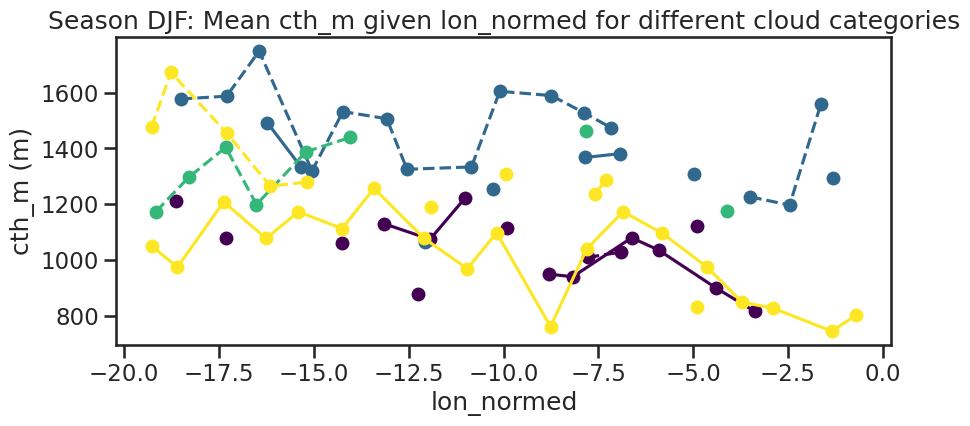

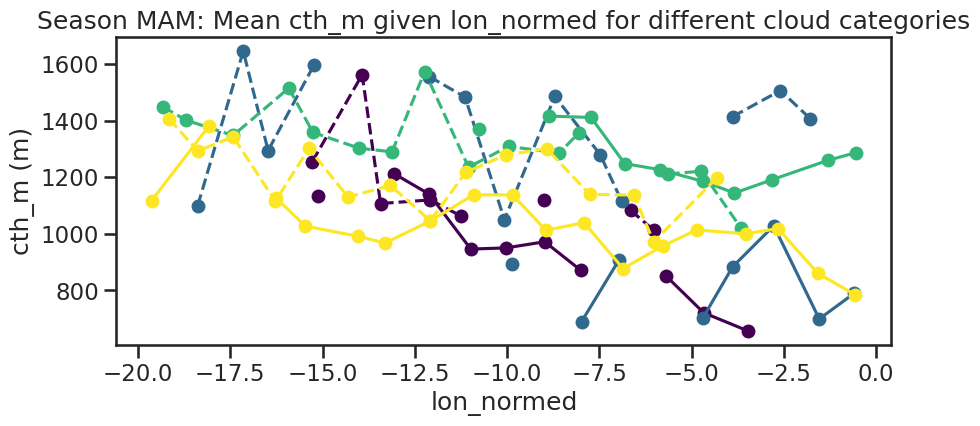

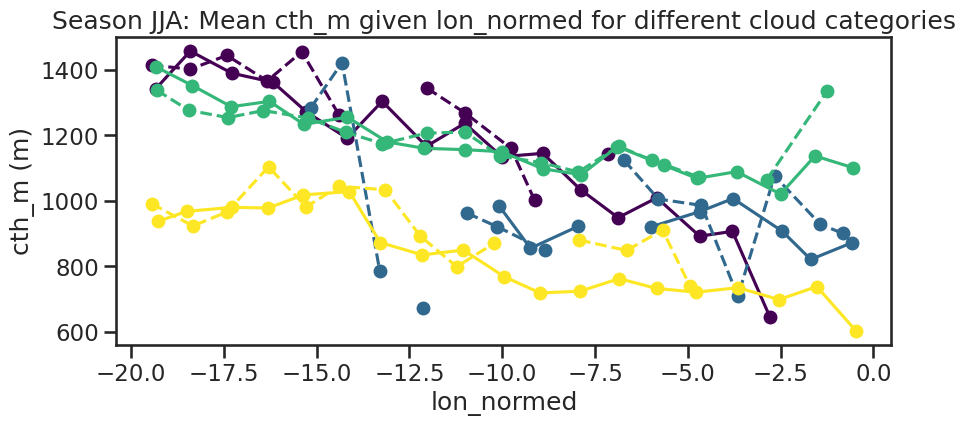

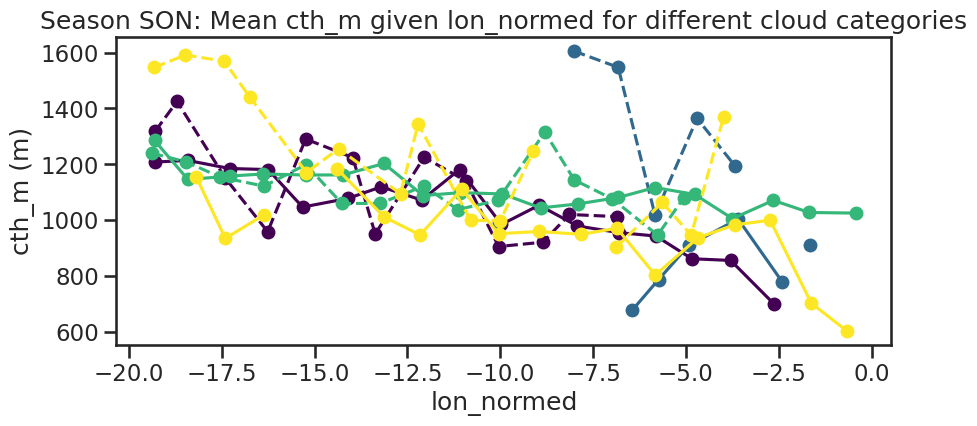

In [ ]:
for season in ['DJF','MAM','JJA','SON']:
    fig, axs = plt.subplots(1,1,figsize=(10,4))
    for sr in [0,1,2,3]:
        color = plt.cm.viridis(sr / 3)
        for i in [1,2]:
            tmp = dffil[(dffil.cats==i) & (dffil.stratus_region_index == sr) & (dffil.season == season)]
            tmp['lon_diff'] = tmp['lon_mid'] - stratus_regions[stratus_region_names[sr]]['lon'][1]
            cth_m_given_lon_mid = tmp[['lon_diff','cth_m']].groupby(pd.cut(tmp['lon_diff'], np.linspace(-20,0,20))).mean()
            cth_m_given_lon_mid['size'] = tmp.groupby(pd.cut(tmp['lon_diff'], np.linspace(-20,0,20))).size()
            cth_m_given_lon_mid['cth_m'] = cth_m_given_lon_mid['cth_m'].where(cth_m_given_lon_mid['size'] >= 3, np.nan)
            cth_m_given_lon_mid.plot(y='cth_m', x='lon_diff', logy=False, logx=False,marker='o', ax=axs, label=cats_names[i], color=color, linestyle=line_styles[i], legend=False)
            # rotate xlabels and round to 1 decimal place
            #plt.xticks(rotation=45)
        #plt.ylim(-10,160)
        plt.xlabel('lon_normed')
        plt.ylabel('cth_m (m)')
        plt.title(f'Season {season}: Mean cth_m given lon_normed for different cloud categories')

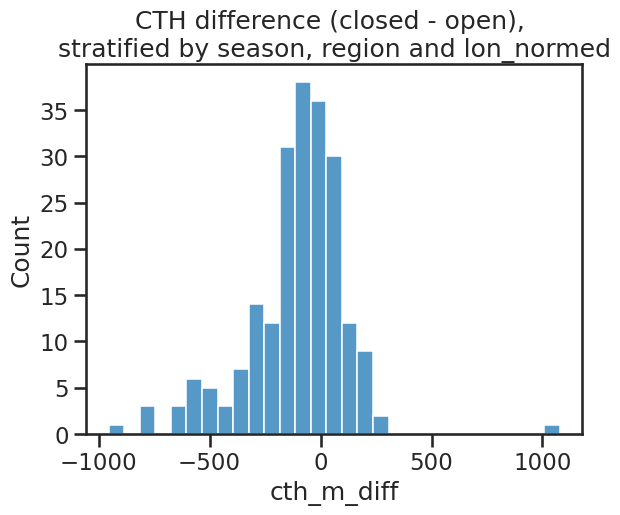

-60.18951308222628


Text(0.05, 0.8, 'weighted mean:\n-60.19 m')

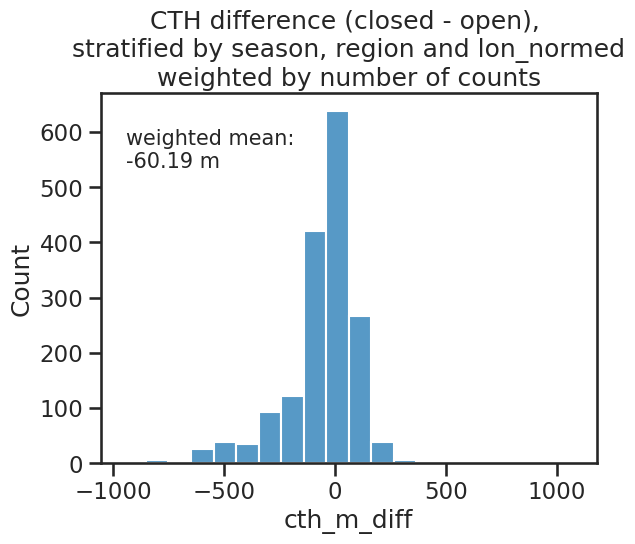

In [138]:
tmp = dffil.copy()
tmp['lon_normed'] = np.where(tmp.stratus_region_index == 0, tmp.lon_mid - stratus_regions[stratus_region_names[0]]['lon'][1], 
        np.where(tmp.stratus_region_index == 1, tmp.lon_mid - stratus_regions[stratus_region_names[1]]['lon'][1], 
                np.where(tmp.stratus_region_index == 2, tmp.lon_mid - stratus_regions[stratus_region_names[2]]['lon'][1], 
                        np.where(tmp.stratus_region_index == 3, tmp.lon_mid - stratus_regions[stratus_region_names[3]]['lon'][1], np.nan))))
tmp['lon_normed'] = tmp['lon_normed'].round()
cth_m_stratified =tmp[tmp.cats.isin([1,2])].groupby(['cats','season','stratus_region_index','lon_normed'])[['cth_m','cbh_m']].mean()
cth_m_stratified['counts'] =tmp[tmp.cats.isin([1,2])].groupby(['cats','season','stratus_region_index','lon_normed'])['cth_m'].count()
cth_m_stratified_closed = cth_m_stratified.loc[1,:,:,:]
cth_m_stratified_open = cth_m_stratified.loc[2,:,:,:]
tmp1 = pd.merge(cth_m_stratified_closed.reset_index(), cth_m_stratified_open.reset_index(), on=['season','stratus_region_index','lon_normed'], suffixes=('_closed','_open'))
tmp1['cth_m_diff'] = tmp1['cth_m_closed'] - tmp1['cth_m_open']
tmp1['counts_min'] = tmp1['counts_closed'].combine(tmp1['counts_open'], min)

sns.histplot(tmp1.cth_m_diff).set(title='CTH difference (closed - open), \nstratified by season, region and lon_normed')
plt.show()
sns.histplot(data=tmp1, x='cth_m_diff', weights='counts_min', bins=20).set(title='CTH difference (closed - open), \nstratified by season, region and lon_normed\nweighted by number of counts')
weighted_mean = (tmp1.cth_m_diff * tmp1.counts_min).sum() / tmp1.counts_min.sum()
print(weighted_mean)
plt.annotate(f'weighted mean:\n{weighted_mean:.2f} m', xy=(0.05, 0.8), xycoords='axes fraction', fontsize=15)

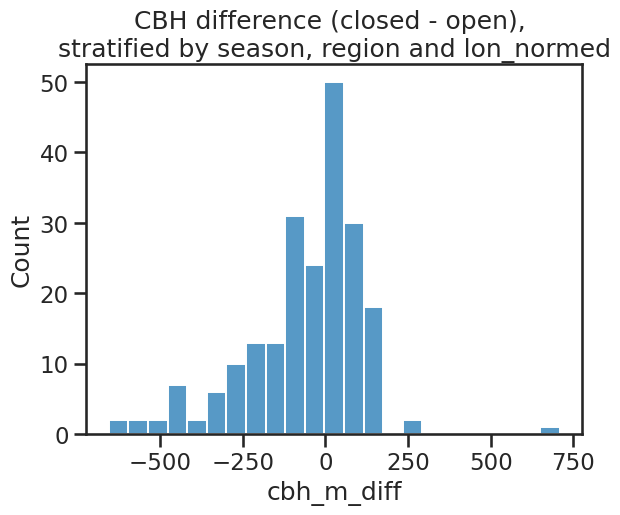

-10.839856084682022


Text(0.05, 0.8, 'weighted mean:\n-10.84 m')

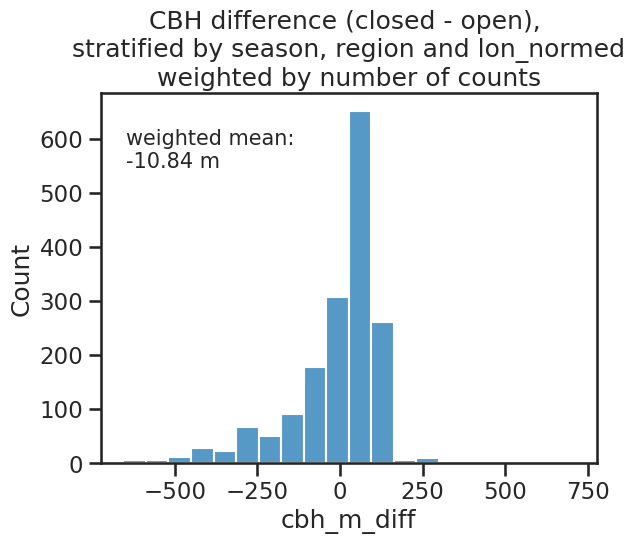

In [29]:
tmp = dffil.copy()
tmp['lon_normed'] = np.where(tmp.stratus_region_index == 0, tmp.lon_mid - stratus_regions[stratus_region_names[0]]['lon'][1], 
        np.where(tmp.stratus_region_index == 1, tmp.lon_mid - stratus_regions[stratus_region_names[1]]['lon'][1], 
                np.where(tmp.stratus_region_index == 2, tmp.lon_mid - stratus_regions[stratus_region_names[2]]['lon'][1], 
                        np.where(tmp.stratus_region_index == 3, tmp.lon_mid - stratus_regions[stratus_region_names[3]]['lon'][1], np.nan))))
tmp['lon_normed'] = tmp['lon_normed'].round()
cbh_m_stratified =tmp[tmp.cats.isin([1,2])].groupby(['cats','season','stratus_region_index','lon_normed'])[['cbh_m']].mean()
cbh_m_stratified['counts'] =tmp[tmp.cats.isin([1,2])].groupby(['cats','season','stratus_region_index','lon_normed'])['cbh_m'].count()
cbh_m_stratified_closed = cbh_m_stratified.loc[1,:,:,:]
cbh_m_stratified_open = cbh_m_stratified.loc[2,:,:,:]
tmp1 = pd.merge(cbh_m_stratified_closed.reset_index(), cbh_m_stratified_open.reset_index(), on=['season','stratus_region_index','lon_normed'], suffixes=('_closed','_open'))
tmp1['cbh_m_diff'] = tmp1['cbh_m_closed'] - tmp1['cbh_m_open']
tmp1['counts_min'] = tmp1['counts_closed'].combine(tmp1['counts_open'], min)

sns.histplot(tmp1.cbh_m_diff).set(title='CBH difference (closed - open), \nstratified by season, region and lon_normed')
plt.show()
sns.histplot(data=tmp1, x='cbh_m_diff', weights='counts_min', bins=20).set(title='CBH difference (closed - open), \nstratified by season, region and lon_normed\nweighted by number of counts')
weighted_mean = (tmp1.cbh_m_diff * tmp1.counts_min).sum() / tmp1.counts_min.sum()
print(weighted_mean)
plt.annotate(f'weighted mean:\n{weighted_mean:.2f} m', xy=(0.05, 0.8), xycoords='axes fraction', fontsize=15)

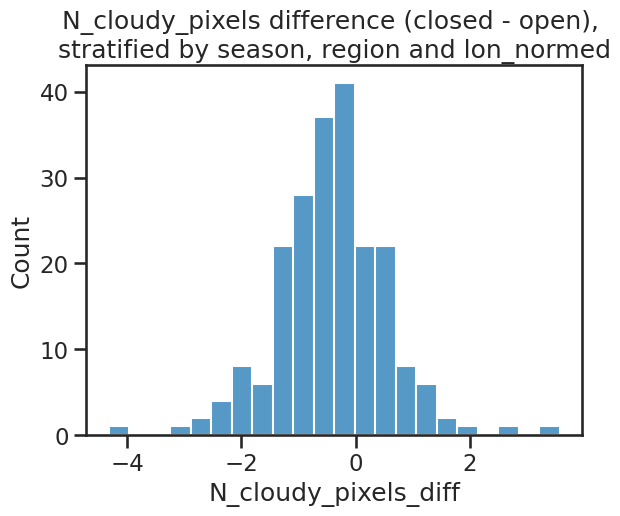

-0.4190858313904883


Text(0.05, 0.8, 'weighted mean:\n-0.42')

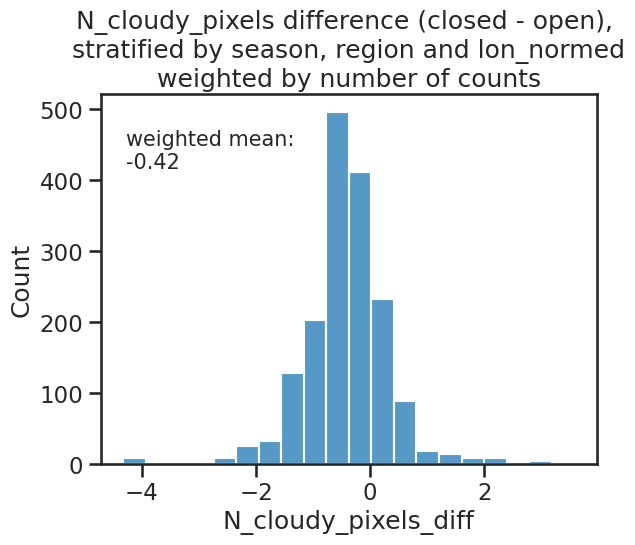

In [30]:
tmp = dffil.copy()
tmp['lon_normed'] = np.where(tmp.stratus_region_index == 0, tmp.lon_mid - stratus_regions[stratus_region_names[0]]['lon'][1], 
        np.where(tmp.stratus_region_index == 1, tmp.lon_mid - stratus_regions[stratus_region_names[1]]['lon'][1], 
                np.where(tmp.stratus_region_index == 2, tmp.lon_mid - stratus_regions[stratus_region_names[2]]['lon'][1], 
                        np.where(tmp.stratus_region_index == 3, tmp.lon_mid - stratus_regions[stratus_region_names[3]]['lon'][1], np.nan))))
tmp['lon_normed'] = tmp['lon_normed'].round()
N_cloudy_pixels_stratified =tmp[tmp.cats.isin([1,2])].groupby(['cats','season','stratus_region_index','lon_normed'])[['N_cloudy_pixels']].mean()
N_cloudy_pixels_stratified['counts'] =tmp[tmp.cats.isin([1,2])].groupby(['cats','season','stratus_region_index','lon_normed'])['N_cloudy_pixels'].count()
N_cloudy_pixels_stratified_closed = N_cloudy_pixels_stratified.loc[1,:,:,:]
N_cloudy_pixels_stratified_open = N_cloudy_pixels_stratified.loc[2,:,:,:]
tmp1 = pd.merge(N_cloudy_pixels_stratified_closed.reset_index(), N_cloudy_pixels_stratified_open.reset_index(), on=['season','stratus_region_index','lon_normed'], suffixes=('_closed','_open'))
tmp1['N_cloudy_pixels_diff'] = tmp1['N_cloudy_pixels_closed'] - tmp1['N_cloudy_pixels_open']
tmp1['counts_min'] = tmp1['counts_closed'].combine(tmp1['counts_open'], min)

sns.histplot(tmp1.N_cloudy_pixels_diff).set(title='N_cloudy_pixels difference (closed - open), \nstratified by season, region and lon_normed')
plt.show()
sns.histplot(data=tmp1, x='N_cloudy_pixels_diff', weights='counts_min', bins=20).set(title='N_cloudy_pixels difference (closed - open), \nstratified by season, region and lon_normed\nweighted by number of counts')
weighted_mean = (tmp1.N_cloudy_pixels_diff * tmp1.counts_min).sum() / tmp1.counts_min.sum()
print(weighted_mean)
plt.annotate(f'weighted mean:\n{weighted_mean:.2f}', xy=(0.05, 0.8), xycoords='axes fraction', fontsize=15)

## microphysics

### rain

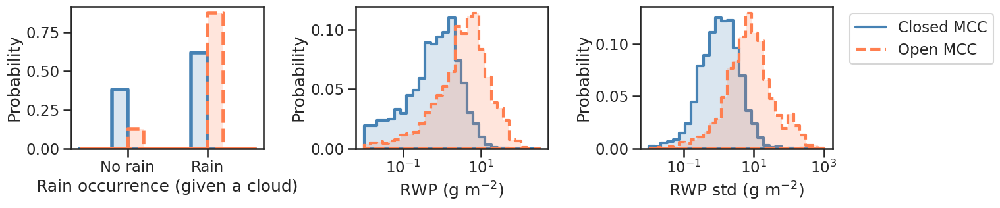

In [25]:
cats = [1,2]

fig, ax = plt.subplots(1,3, figsize=(13, 3.5))
for j,i in enumerate(cats):
    sns.histplot(ax=ax[0], x=(dffil[dffil['cats'] == i]['rwp'] > 0) + j*0.2, bins=np.arange(-0.5,1.8,0.2), 
                 element='step', alpha=0.2, stat='probability', color=catcolors[i], lw=4, ls=line_styles[i])
    sns.histplot(
        ax=ax[1], x=dffil[(dffil['cats'] == i) & (dffil['rwp']>0)]['rwp'], bins=np.logspace(-2,2.5,30),
        element='step', stat='probability', fill=True, alpha=0.2, lw=3, ls=line_styles[i],
        color=catcolors[i])
    sns.histplot(
        ax=ax[2], x=dffil[(dffil['cats'] == i)]['rwp_std'], bins=np.logspace(-2,3,30),
        element='step', stat='probability', fill=True, alpha=0.2, lw=3, ls=line_styles[i],
        color=catcolors[i])


ax[1].set_xscale('log')
ax[1].set_xlabel('RWP (g m$^{-2}$)')
ax[2].set_xscale('log')
ax[2].set_xlabel('RWP std (g m$^{-2}$)')

ax[0].set_xticks([0.1,1.1])
ax[0].set_xticklabels(['No rain', 'Rain'])
ax[0].set_xlabel('Rain occurrence (given a cloud)')
fig.tight_layout()

legend_elements = [
    Line2D([0], [0], color=catcolors[i], lw=3, linestyle=line_styles[i], label=cats_names[i])
    for i in cats
]
ax[2].legend(handles=legend_elements, bbox_to_anchor=(1.05, 1), loc='upper left')

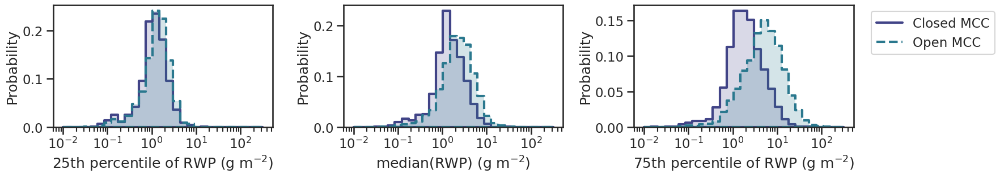

In [29]:
cats = [1,2]

fig, ax = plt.subplots(1,3, figsize=(18, 3.5))
for j,i in enumerate(cats):
    sns.histplot(
        ax=ax[0], x=dffil[(dffil['cats'] == i)]['rwp_perc25'], bins=np.logspace(-2,2.5,30),
        element='step', stat='probability', fill=True, alpha=0.2, lw=3, ls=line_styles[i],
        color=catcolors[i])
    sns.histplot(
        ax=ax[1], x=dffil[(dffil['cats'] == i)]['rwp_median'], bins=np.logspace(-2,2.5,30),
        element='step', stat='probability', fill=True, alpha=0.2, lw=3, ls=line_styles[i],
        color=catcolors[i])
    sns.histplot(
        ax=ax[2], x=dffil[(dffil['cats'] == i)]['rwp_perc75'], bins=np.logspace(-2,2.5,30),
        element='step', stat='probability', fill=True, alpha=0.2, lw=3, ls=line_styles[i],
        color=catcolors[i])


ax[0].set_xscale('log')
ax[0].set_xlabel('25th percentile of RWP (g m$^{-2}$)')
ax[1].set_xscale('log')
ax[1].set_xlabel('median(RWP) (g m$^{-2}$)')
ax[2].set_xscale('log')
ax[2].set_xlabel('75th percentile of RWP (g m$^{-2}$)')

legend_elements = [
    Line2D([0], [0], color=catcolors[i], lw=3, linestyle=line_styles[i], label=cats_names[i])
    for i in cats
]
ax[2].legend(handles=legend_elements, bbox_to_anchor=(1.05, 1), loc='upper left')
fig.tight_layout()

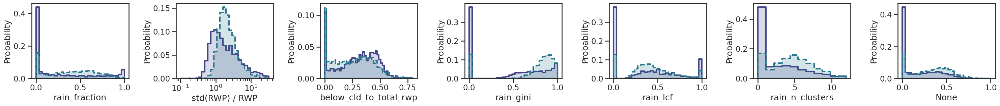

In [45]:
cats = [1,2]

fig, ax = plt.subplots(1,7, figsize=(30, 3.5))
for j,i in enumerate(cats):
    sns.histplot(
        ax=ax[0], x=dffil[(dffil['cats'] == i)]['rain_fraction'], bins=np.linspace(0,1,30),
        element='step', stat='probability', fill=True, alpha=0.2, lw=3, ls=line_styles[i],
        color=catcolors[i])
    sns.histplot(
        ax=ax[1], x=dffil[(dffil['cats'] == i)]['rwp_std'] / dffil[(dffil['cats'] == i)]['rwp'], bins=np.logspace(-1,1.5,30),
        element='step', stat='probability', fill=True, alpha=0.2, lw=3, ls=line_styles[i],
        color=catcolors[i])
    sns.histplot(
        ax=ax[2], x=dffil[(dffil['cats'] == i)]['below_cld_to_total_rwp'], bins=np.linspace(0,0.8),
        element='step', stat='probability', fill=True, alpha=0.2, lw=3, ls=line_styles[i],
        color=catcolors[i])
    sns.histplot(
        ax=ax[3], x=dffil[(dffil['cats'] == i)]['rain_gini'], bins=np.linspace(0,1.,30),
        element='step', stat='probability', fill=True, alpha=0.2, lw=3, ls=line_styles[i],
        color=catcolors[i])
    sns.histplot(
        ax=ax[4], x=dffil[(dffil['cats'] == i)]['rain_lcf'], bins=np.linspace(0,1,30),
        element='step', stat='probability', fill=True, alpha=0.2, lw=3, ls=line_styles[i],
        color=catcolors[i])
    sns.histplot(
        ax=ax[5], x=dffil[(dffil['cats'] == i)]['rain_n_clusters'], bins=np.linspace(0,12,12),
        element='step', stat='probability', fill=True, alpha=0.2, lw=3, ls=line_styles[i],
        color=catcolors[i])
    sns.histplot(
        ax=ax[6], x=dffil[(dffil['cats'] == i)]['rain_gini'] * dffil[(dffil['cats'] == i)]['rain_fraction'], bins=np.linspace(0,1.,30),
        element='step', stat='probability', fill=True, alpha=0.2, lw=3, ls=line_styles[i],
        color=catcolors[i])

ax[1].set_xscale('log')
ax[1].set_xlabel('std(RWP) / RWP')

fig.tight_layout()

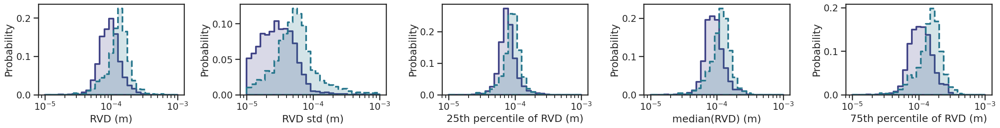

In [ ]:
cats = [1,2]

fig, ax = plt.subplots(1,5, figsize=(25, 3.5))
for j,i in enumerate(cats):
    sns.histplot(
        ax=ax[0], x=dffil[(dffil['cats'] == i)]['rain_median_volume_diameter'], bins=np.logspace(-5,-3,30),
        element='step', stat='probability', fill=True, alpha=0.2, lw=3, ls=line_styles[i],
        color=catcolors[i])
    sns.histplot(
        ax=ax[1], x=dffil[(dffil['cats'] == i)]['rain_median_volume_diameter_std'], bins=np.logspace(-5,-3,30),
        element='step', stat='probability', fill=True, alpha=0.2, lw=3, ls=line_styles[i],
        color=catcolors[i])
    sns.histplot(
        ax=ax[2], x=dffil[(dffil['cats'] == i)]['rain_median_volume_diameter_perc25'], bins=np.logspace(-5,-3,30),
        element='step', stat='probability', fill=True, alpha=0.2, lw=3, ls=line_styles[i],
        color=catcolors[i])
    sns.histplot(
        ax=ax[3], x=dffil[(dffil['cats'] == i)]['rain_median_volume_diameter_median'], bins=np.logspace(-5,-3,30),
        element='step', stat='probability', fill=True, alpha=0.2, lw=3, ls=line_styles[i],
        color=catcolors[i])
    sns.histplot(
        ax=ax[4], x=dffil[(dffil['cats'] == i)]['rain_median_volume_diameter_perc75'], bins=np.logspace(-5,-3,30),
        element='step', stat='probability', fill=True, alpha=0.2, lw=3, ls=line_styles[i],
        color=catcolors[i])

for a in ax:
    a.set_xscale('log')
ax[0].set_xlabel('$D_0$ (m)')
ax[1].set_xlabel('$D_0$ std (m)')
ax[2].set_xlabel('25th percentile of $D_0$ (m)')
ax[3].set_xlabel('median($D_0$) (m)')
ax[4].set_xlabel('75th percentile of $D_0$ (m)')

fig.tight_layout()

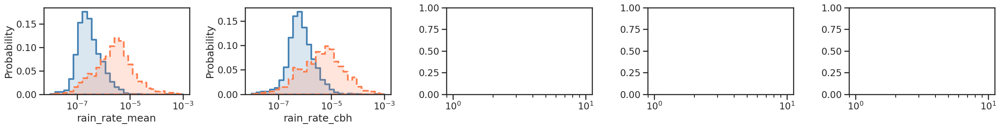

In [27]:
cats = [1,2]

fig, ax = plt.subplots(1,5, figsize=(25, 3.5))
for j,i in enumerate(cats):
    sns.histplot(
        ax=ax[0], x=dffil[(dffil['cats'] == i)]['rain_rate_mean'], bins=np.logspace(-8,-3,30),
        element='step', stat='probability', fill=True, alpha=0.2, lw=3, ls=line_styles[i],
        color=catcolors[i])
    sns.histplot(
        ax=ax[1], x=dffil[(dffil['cats'] == i)]['rain_rate_cbh'], bins=np.logspace(-8,-3,30),
        element='step', stat='probability', fill=True, alpha=0.2, lw=3, ls=line_styles[i],
        color=catcolors[i])

for a in ax:
    a.set_xscale('log')

fig.tight_layout()

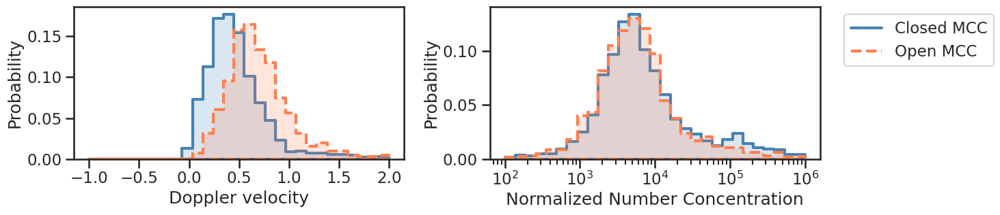

In [26]:
cats = [1,2]

fig, ax = plt.subplots(1,2, figsize=(15, 3.5))
for j,i in enumerate(cats):
    sns.histplot(
        ax=ax[0], x=dffil[(dffil['cats'] == i)]['doppler_velocity_mean'], bins=np.linspace(-1,2,30),
        element='step', stat='probability', fill=True, alpha=0.2, lw=3, ls=line_styles[i],
        color=catcolors[i])
    sns.histplot(
        ax=ax[1], x=dffil[(dffil['cats'] == i)]['rain_normalized_number_concentration']*1e-6, bins=np.logspace(2,6,30),
        element='step', stat='probability', fill=True, alpha=0.2, lw=3, ls=line_styles[i],
        color=catcolors[i])


ax[0].set_xscale('linear')
ax[0].set_xlabel('Doppler velocity')
ax[1].set_xscale('log')
ax[1].set_xlabel('Normalized Number Concentration')

legend_elements = [
    Line2D([0], [0], color=catcolors[i], lw=3, linestyle=line_styles[i], label=cats_names[i])
    for i in cats
]
ax[1].legend(handles=legend_elements, bbox_to_anchor=(1.05, 1), loc='upper left')
fig.tight_layout()

### LWP, Nd, ER

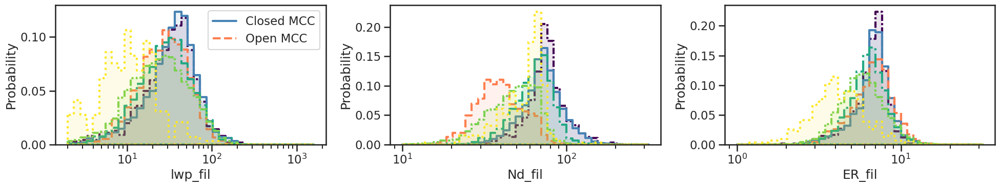

In [26]:
fig, ax = plt.subplots(1,3, figsize=(20, 4))
for i in [0,1,2,3,4,5]: 
    sns.histplot(
        ax=ax[0], data=dffil[dffil.lwp_fil > 0][dffil['cats'] == i], x='lwp_fil', bins=np.logspace(0.3,3.2,40),
        element='step', stat='probability', fill=True, alpha=0.1, lw=3, ls=line_styles[i],
        color=catcolors[i])
    sns.histplot(
        ax=ax[1], data=dffil[dffil.lwp_fil > 0][dffil['cats'] == i], x='Nd_fil', bins=np.logspace(1,2.5,40),
        element='step', stat='probability', fill=True, alpha=0.1, lw=3, ls=line_styles[i],
        color=catcolors[i])
    sns.histplot(
        ax=ax[2], data=dffil[dffil.lwp_fil > 0][dffil['cats'] == i], x='ER_fil', bins=np.logspace(0,1.5,40),
        element='step', stat='probability', fill=True, alpha=0.1, lw=3, ls=line_styles[i],
        color=catcolors[i])
for a in ax.flatten():
    a.set_xscale('log')
ax[0].legend(handles=legend_elements)
fig.tight_layout()

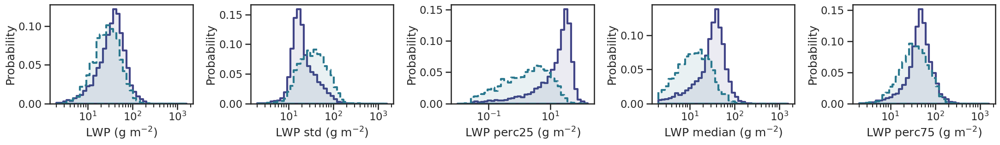

In [36]:
cats = [1,2]

fig, ax = plt.subplots(1,5, figsize=(22, 3.5))
for i in cats: 
    #sns.histplot(
    #    ax=ax[0,0], x=dffil[dffil.lwp_fil > 0][dffil['cats'] == i]['lwp_fil'] * dffil[dffil.lwp_fil > 0][dffil['cats'] == i]['acmcap_cloud_flag'], bins=np.logspace(0.3,3.2,40),
    #    element='step', stat='probability', fill=True, alpha=0.1, lw=3, ls=line_styles[i],
    #    color=catcolors[i])
    sns.histplot(
        ax=ax[0], data=dffil[dffil.lwp_fil > 0][dffil['cats'] == i], x='lwp_fil', bins=np.logspace(0.3,3.2,40),
        element='step', stat='probability', fill=True, alpha=0.1, lw=3, ls=line_styles[i],
        color=catcolors[i])
    sns.histplot(
        ax=ax[1], data=dffil[dffil.lwp_fil > 0][dffil['cats'] == i], x='lwp_std', bins=np.logspace(0.3,3.2,40),
        element='step', stat='probability', fill=True, alpha=0.1, lw=3, ls=line_styles[i],
        color=catcolors[i])
    sns.histplot(
        ax=ax[2], data=dffil[dffil.lwp_fil > 0][dffil['cats'] == i], x='lwp_perc25', bins=np.logspace(-2,2.2,40),
        element='step', stat='probability', fill=True, alpha=0.1, lw=3, ls=line_styles[i],
        color=catcolors[i])
    sns.histplot(
        ax=ax[3], data=dffil[dffil.lwp_fil > 0][dffil['cats'] == i], x='lwp_median', bins=np.logspace(0.3,3.2,40),
        element='step', stat='probability', fill=True, alpha=0.1, lw=3, ls=line_styles[i],
        color=catcolors[i])
    sns.histplot(
        ax=ax[4], data=dffil[dffil.lwp_fil > 0][dffil['cats'] == i], x='lwp_perc75', bins=np.logspace(0.3,3.2,40),
        element='step', stat='probability', fill=True, alpha=0.1, lw=3, ls=line_styles[i],
        color=catcolors[i])
for a in ax.flatten():
    a.set_xscale('log')
legend_elements = [
    Line2D([0], [0], color=catcolors[i], lw=3, linestyle=line_styles[i], label=cats_names[i])
    for i in cats
]
#ax[0].legend(handles=legend_elements)
#ax[0,0].set_xlabel('LWP * CC (g m$^{-2}$)')
ax[0].set_xlabel('LWP (g m$^{-2}$)')
ax[1].set_xlabel('LWP std (g m$^{-2}$)')
ax[2].set_xlabel('LWP perc25 (g m$^{-2}$)')
ax[3].set_xlabel('LWP median (g m$^{-2}$)')
ax[4].set_xlabel('LWP perc75 (g m$^{-2}$)')
fig.tight_layout()

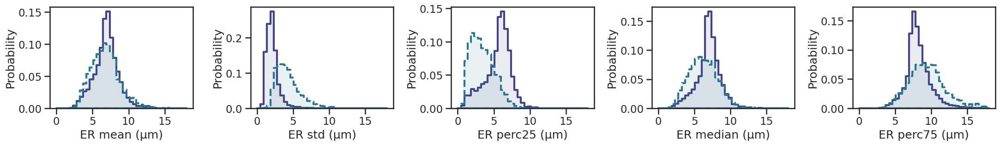

In [37]:
cats = [1,2]

fig, ax = plt.subplots(1,5, figsize=(22, 3.5))
for i in cats: 
    sns.histplot(
        ax=ax[0], data=dffil[dffil.lwp_fil > 0][dffil['cats'] == i], x='ER', bins=np.linspace(0,18,40),
        element='step', stat='probability', fill=True, alpha=0.1, lw=3, ls=line_styles[i],
        color=catcolors[i])
    sns.histplot(
        ax=ax[1], data=dffil[dffil.lwp_fil > 0][dffil['cats'] == i], x='ER_std', bins=np.linspace(0,18,40),
        element='step', stat='probability', fill=True, alpha=0.1, lw=3, ls=line_styles[i],
        color=catcolors[i])
    sns.histplot(
        ax=ax[2], data=dffil[dffil.lwp_fil > 0][dffil['cats'] == i], x='ER_perc25', bins=np.linspace(0,18,40),
        element='step', stat='probability', fill=True, alpha=0.1, lw=3, ls=line_styles[i],
        color=catcolors[i])
    sns.histplot(
        ax=ax[3], data=dffil[dffil.lwp_fil > 0][dffil['cats'] == i], x='ER_median', bins=np.linspace(0,18,40),
        element='step', stat='probability', fill=True, alpha=0.1, lw=3, ls=line_styles[i],
        color=catcolors[i])
    sns.histplot(
        ax=ax[4], data=dffil[dffil.lwp_fil > 0][dffil['cats'] == i], x='ER_perc75', bins=np.linspace(0,18,40),
        element='step', stat='probability', fill=True, alpha=0.1, lw=3, ls=line_styles[i],
        color=catcolors[i])
#for a in ax.flatten():
#    a.set_xscale('log')
legend_elements = [
    Line2D([0], [0], color=catcolors[i], lw=3, linestyle=line_styles[i], label=cats_names[i])
    for i in cats
]
#ax[0].legend(handles=legend_elements)
ax[0].set_xlabel('ER mean (µm)')
ax[1].set_xlabel('ER std (µm)')
ax[2].set_xlabel('ER perc25 (µm)')
ax[3].set_xlabel('ER median (µm)')
ax[4].set_xlabel('ER perc75 (µm)')
fig.tight_layout()

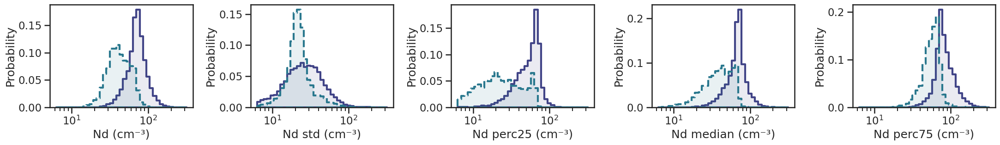

In [38]:
cats = [1,2]

fig, ax = plt.subplots(1,5, figsize=(22, 3.5))
for i in cats: 
    sns.histplot(
        ax=ax[0], data=dffil[dffil.lwp_fil > 0][dffil['cats'] == i], x='Nd', bins=np.logspace(0.8,2.5,40),
        element='step', stat='probability', fill=True, alpha=0.1, lw=3, ls=line_styles[i],
        color=catcolors[i])
    sns.histplot(
        ax=ax[1], data=dffil[dffil.lwp_fil > 0][dffil['cats'] == i], x='Nd_std', bins=np.logspace(0.8,2.5,40),
        element='step', stat='probability', fill=True, alpha=0.1, lw=3, ls=line_styles[i],
        color=catcolors[i])
    sns.histplot(
        ax=ax[2], data=dffil[dffil.lwp_fil > 0][dffil['cats'] == i], x='Nd_perc25', bins=np.logspace(0.8,2.5,40),
        element='step', stat='probability', fill=True, alpha=0.1, lw=3, ls=line_styles[i],
        color=catcolors[i])
    sns.histplot(
        ax=ax[3], data=dffil[dffil.lwp_fil > 0][dffil['cats'] == i], x='Nd_median', bins=np.logspace(0.8,2.5,40),
        element='step', stat='probability', fill=True, alpha=0.1, lw=3, ls=line_styles[i],
        color=catcolors[i])
    sns.histplot(
        ax=ax[4], data=dffil[dffil.lwp_fil > 0][dffil['cats'] == i], x='Nd_perc75', bins=np.logspace(0.8,2.5,40),
        element='step', stat='probability', fill=True, alpha=0.1, lw=3, ls=line_styles[i],
        color=catcolors[i])
for a in ax.flatten():
    a.set_xscale('log')
legend_elements = [
    Line2D([0], [0], color=catcolors[i], lw=3, linestyle=line_styles[i], label=cats_names[i])
    for i in cats
]
#ax[0].legend(handles=legend_elements)
ax[0].set_xlabel('Nd (cm⁻³)')
ax[1].set_xlabel('Nd std (cm⁻³)')
ax[2].set_xlabel('Nd perc25 (cm⁻³)')
ax[3].set_xlabel('Nd median (cm⁻³)')
ax[4].set_xlabel('Nd perc75 (cm⁻³)')
fig.tight_layout()

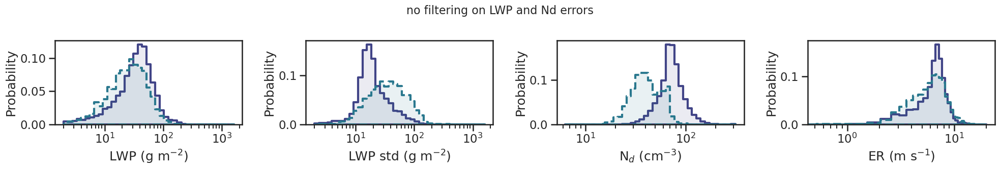

In [27]:
cats = [1,2]

fig, ax = plt.subplots(1,4, figsize=(20, 3.5))
for i in cats: 
    sns.histplot(
        ax=ax[0], data=dffil[dffil.lwp > 0][dffil['cats'] == i], x='lwp', bins=np.logspace(0.3,3.2,40),
        element='step', stat='probability', fill=True, alpha=0.1, lw=3, ls=line_styles[i],
        color=catcolors[i])
    sns.histplot(
        ax=ax[1], data=dffil[dffil.lwp > 0][dffil['cats'] == i], x='lwp_std', bins=np.logspace(0.3,3.2,40),
        element='step', stat='probability', fill=True, alpha=0.1, lw=3, ls=line_styles[i],
        color=catcolors[i])
    sns.histplot(
        ax=ax[2], data=dffil[dffil.lwp > 0][dffil['cats'] == i], x='Nd', bins=np.logspace(0.8,2.5,40),
        element='step', stat='probability', fill=True, alpha=0.1, lw=3, ls=line_styles[i],
        color=catcolors[i])
    sns.histplot(
        ax=ax[3], data=dffil[dffil.lwp > 0][dffil['cats'] == i], x='ER', bins=np.linspace(0,20,40),
        element='step', stat='probability', fill=True, alpha=0.1, lw=3, ls=line_styles[i],
        color=catcolors[i])
for a in ax.flatten():
    a.set_xscale('log')
legend_elements = [
    Line2D([0], [0], color=catcolors[i], lw=3, linestyle=line_styles[i], label=cats_names[i])
    for i in cats
]
#ax[0].legend(handles=legend_elements)
plt.suptitle('no filtering on LWP and Nd errors', fontsize=16)
ax[0].set_xlabel('LWP (g m$^{-2}$)')
ax[1].set_xlabel('LWP std (g m$^{-2}$)')
ax[2].set_xlabel('N$_d$ (cm$^{-3}$)')
ax[3].set_xlabel('ER (m s$^{-1}$)')
fig.tight_layout()

In [39]:
for reg in [0,1,2,3]:
    fig, ax = plt.subplots(1,3, figsize=(20, 4))
    fig.suptitle(f'Region {stratus_region_names[reg]}')
    for i in [1,2]: 
        d = dffil[(dffil['cats'] == i) & (dffil.stratus_region_index == reg)].dropna()
        if len(d.groupby('scene_id')['cats'].mean()) < 10: # at least 10 scenes per category
            print(reg, i, len(d))
            continue
        sns.histplot(
            ax=ax[0], data=d, x='lwp', bins=np.logspace(0.5,2.7,40),
            element='step', stat='probability', fill=True, alpha=0.1, lw=3, ls=line_styles[i],
            color=catcolors[i])
        sns.histplot(
            ax=ax[1], data=d, x='Nd', bins=np.logspace(0.8,2.5,40),
            element='step', stat='probability', fill=True, alpha=0.1, lw=3, ls=line_styles[i],
            color=catcolors[i])
        sns.histplot(
            ax=ax[2], data=d, x='ER', bins=np.logspace(-5.7,-4.7,40),
            element='step', stat='probability', fill=True, alpha=0.1, lw=3, ls=line_styles[i],
            color=catcolors[i])
    for a in ax.flatten():
        a.set_xscale('log')
    ax[0].legend(handles=legend_elements)
    fig.tight_layout()

ValueError: Data has no positive values, and therefore cannot be log-scaled.

Error in callback <function _draw_all_if_interactive at 0x7f1d857e44a0> (for post_execute), with arguments args (),kwargs {}:


ValueError: Data has no positive values, and therefore cannot be log-scaled.

ValueError: Data has no positive values, and therefore cannot be log-scaled.

<Figure size 2000x400 with 3 Axes>

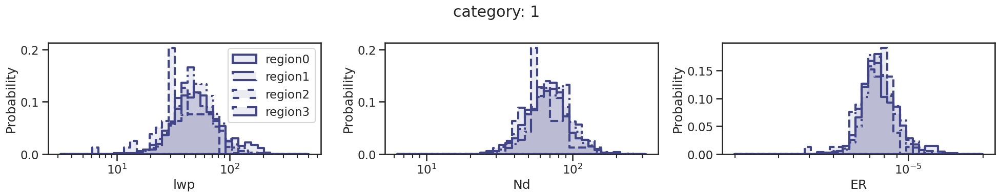

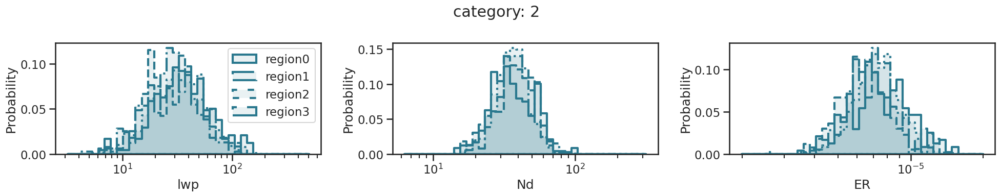

In [72]:
line_styles_region = ['solid', 'dashed', 'dotted', 'dashdot']

for i in [1,2]: 
    fig, ax = plt.subplots(1,3, figsize=(20, 4))
    fig.suptitle(f'category: {i}')
    for reg in [0,1,2,3]:
        d = dffil[(dffil['cats'] == i) & (dffil.stratus_region_index == reg)].dropna()
        if len(d.groupby('scene_id')['cats'].mean()) < 10: # at least 10 scenes per category
            print(reg, i, len(d))
            continue
        sns.histplot(
            ax=ax[0], data=d, x='lwp', bins=np.logspace(0.5,2.7,40),
            element='step', stat='probability', fill=True, alpha=0.1, lw=3, ls=line_styles_region[reg],
            color=catcolors[i], label='region'+str(reg))
        sns.histplot(
            ax=ax[1], data=d, x='Nd', bins=np.logspace(0.8,2.5,40),
            element='step', stat='probability', fill=True, alpha=0.1, lw=3, ls=line_styles_region[reg],
            color=catcolors[i])
        sns.histplot(
            ax=ax[2], data=d, x='ER', bins=np.logspace(-5.7,-4.7,40),
            element='step', stat='probability', fill=True, alpha=0.1, lw=3, ls=line_styles_region[reg],
            color=catcolors[i])
    for a in ax.flatten():
        a.set_xscale('log')
    ax[0].legend()
    fig.tight_layout()

## Overview plot for publication

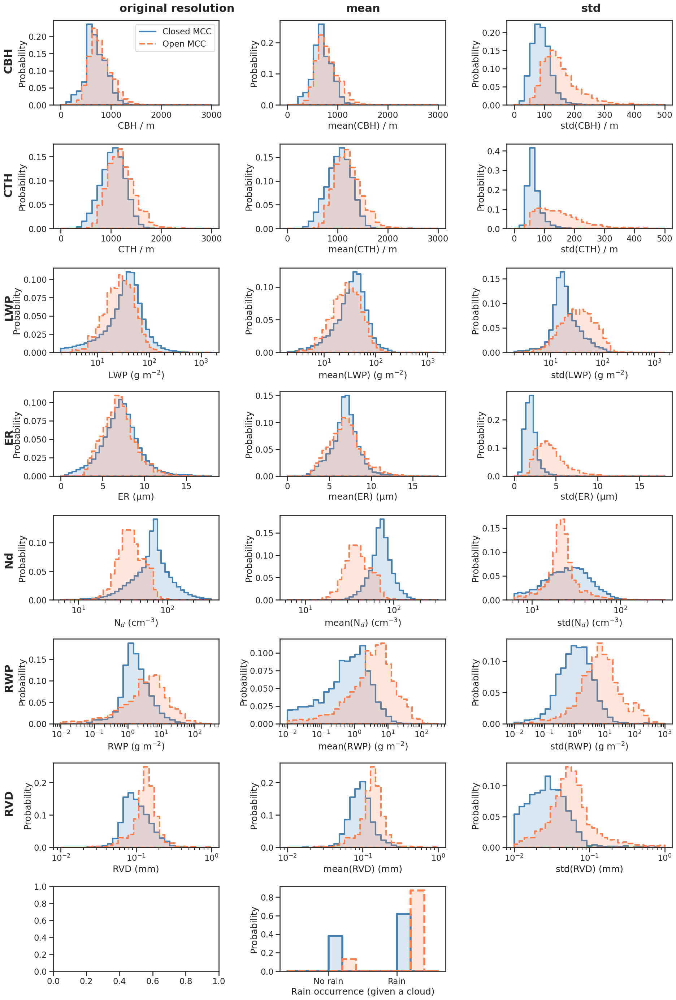

In [ ]:
nrows = 8

vars_to_plot = {
    'cbh_m_1km': [np.linspace(0,3000,30), 'linear', 'CBH / m'],
    'cbh_m': [np.linspace(0,3000,30), 'linear', 'mean(CBH) / m'],
    'cbh_m_std': [np.linspace(0,500,30), 'linear', 'std(CBH) / m'],
    'cth_m_1km': [np.linspace(0,3000,30), 'linear', 'CTH / m'],
    'cth_m': [np.linspace(0,3000,30), 'linear', 'mean(CTH) / m'],
    'cth_m_std': [np.linspace(0,500,30), 'linear', 'std(CTH) / m' ],
    'lwp_fil_1km': [np.logspace(0.3,3.2,40), 'log', 'LWP (g m$^{-2}$)'],
    'lwp_fil': [np.logspace(0.3,3.2,40), 'log', 'mean(LWP) (g m$^{-2}$)'],
    'lwp_std': [np.logspace(0.3,3.2,40), 'log', 'std(LWP) (g m$^{-2}$)'],
    'ER_fil_1km': [np.linspace(0,18,40), 'linear', 'ER (µm)'],
    'ER_fil': [np.linspace(0,18,40), 'linear', 'mean(ER) (µm)'],
    'ER_std': [np.linspace(0,18,40), 'linear', 'std(ER) (µm)'],
    'Nd_fil_1km': [np.logspace(0.8,2.5,40), 'log', 'N$_d$ (cm$^{-3}$)'],
    'Nd_fil': [np.logspace(0.8,2.5,40), 'log', 'mean(N$_d$) (cm$^{-3}$)'],
    'Nd_std': [np.logspace(0.8,2.5,40), 'log', 'std(N$_d$) (cm$^{-3}$)'],
    'rwp_1km': [np.logspace(-2,2.5,30), 'log', 'RWP (g m$^{-2}$)'],
    'rwp': [np.logspace(-2,2.5,30), 'log', 'mean(RWP) (g m$^{-2}$)'],
    'rwp_std': [np.logspace(-2,3,30), 'log', 'std(RWP) (g m$^{-2}$)'],
    'rain_median_volume_diameter_1km': [np.logspace(-2,0,30), 'log', '$D_0$ (mm)'],
    'rain_median_volume_diameter': [np.logspace(-2,0,30), 'log', 'mean($D_0$) (mm)'],
    'rain_median_volume_diameter_std': [np.logspace(-2,0,30), 'log', 'std($D_0$) (mm)']
}


fig, ax = plt.subplots(nrows,3, figsize=(19, 3.5*nrows))
axs = ax.flatten()
for i, (var, plot_params) in enumerate(vars_to_plot.items()):
    for j in [1,2]: 
        if '1km' in var:
            data = dffil_1km
            var = var.replace('_1km','')
        else:
            data = dffil
        histplot_with_style(j, axs[i], data, var, plot_params[0])

        #for sr in [0,1,2,3]:
        #    sns.histplot(
        #        ax=axs[i], data=dffil[(dffil['cats'] == j) & (dffil['stratus_region_index'] == sr)], x=var, bins=plot_params[0],
        #        element='step', stat='probability', fill=False, alpha=0.5, lw=1, ls=line_styles[j], 
        #        color=catcolors[j],
        #    )
    #axs[i].set_xlim(plot_params[0][0], plot_params[0][-1])
    axs[i].set_xscale(plot_params[1])
    axs[i].set_xlabel(plot_params[2])

for j in [1,2]:
    sns.histplot(ax=axs[-2], x=(dffil[dffil['cats'] == j]['rwp'] > 0) + j*0.2, bins=np.arange(-0.5,1.8,0.2), 
                element='step', alpha=0.2, stat='probability', color=catcolors[j], lw=4, ls=line_styles[j])
axs[-2].set_xticks([0.1,1.1])
axs[-2].set_xticklabels(['No rain', 'Rain'])
axs[-2].set_xlabel('Rain occurrence (given a cloud)')
axs[-1].axis('off')


legend_elements = [
    Line2D([0], [0], color=catcolors[i], lw=3, linestyle=line_styles[i], label=cats_names[i])
    for i in [1,2]
]
axs[0].legend(handles=legend_elements, loc='upper right')
axs[0].annotate('original resolution', xy=(0.2, 1.1), xycoords='axes fraction', fontsize=22, fontweight='bold')
axs[1].annotate('mean', xy=(0.4, 1.1), xycoords='axes fraction', fontsize=22, fontweight='bold')
axs[2].annotate('std', xy=(0.45, 1.1), xycoords='axes fraction', fontsize=22, fontweight='bold')
for idx, text in enumerate(['CBH','CTH','LWP','ER','Nd','RWP','$D_0$']):
    ax[idx,0].annotate(text, xy=(-0.3, 0.4), xycoords='axes fraction', rotation=90, fontsize=22, fontweight='bold')

fig.tight_layout()

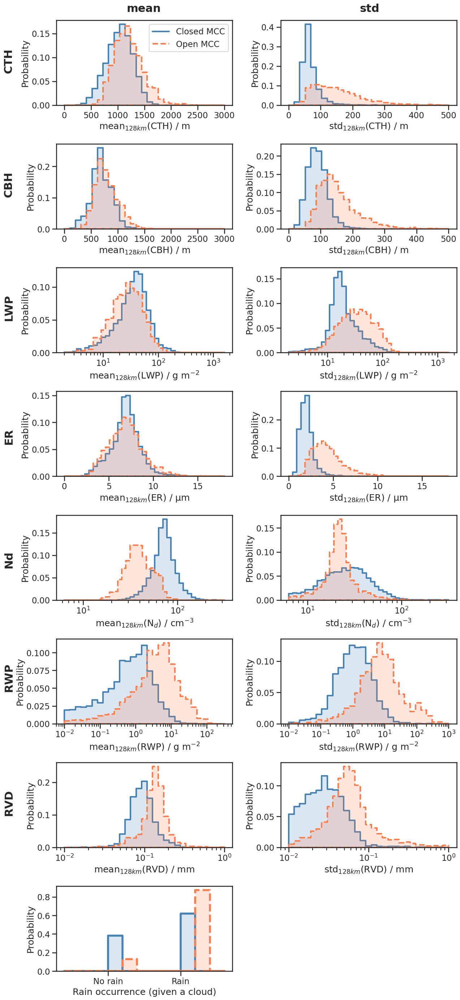

In [ ]:
nrows = 8

vars_to_plot = {
    'cth_m': [np.linspace(0,3000,30), 'linear', 'mean$_{128km}$(CTH) / m'],
    'cth_m_std': [np.linspace(0,500,30), 'linear', 'std$_{128km}$(CTH) / m'],
    'cbh_m': [np.linspace(0,3000,30), 'linear', 'mean$_{128km}$(CBH) / m'],
    'cbh_m_std': [np.linspace(0,500,30), 'linear', 'std$_{128km}$(CBH) / m'],
    'lwp_fil': [np.logspace(0.3,3.2,40), 'log', 'mean$_{128km}$(LWP) / g m$^{-2}$'],
    'lwp_std': [np.logspace(0.3,3.2,40), 'log', 'std$_{128km}$(LWP) / g m$^{-2}$'],
    'ER_fil': [np.linspace(0,18,40), 'linear', 'mean$_{128km}$(ER) / µm'],
    'ER_std': [np.linspace(0,18,40), 'linear', 'std$_{128km}$(ER) / µm'],
    'Nd_fil': [np.logspace(0.8,2.5,40), 'log', 'mean$_{128km}$(N$_d$) / cm$^{-3}$'],
    'Nd_std': [np.logspace(0.8,2.5,40), 'log', 'std$_{128km}$(N$_d$) / cm$^{-3}$'],
    'rwp': [np.logspace(-2,2.5,30), 'log', 'mean$_{128km}$(RWP) / g m$^{-2}$'],
    'rwp_std': [np.logspace(-2,3,30), 'log', 'std$_{128km}$(RWP) / g m$^{-2}$'],
    'rain_median_volume_diameter': [np.logspace(-2,0,30), 'log', 'mean$_{128km}$($D_0$) / mm'],
    'rain_median_volume_diameter_std': [np.logspace(-2,0,30), 'log', 'std$_{128km}$($D_0$) / mm']
}


fig, ax = plt.subplots(nrows,2, figsize=(13, 3.5*nrows))
axs = ax.flatten()
for i, (var, plot_params) in enumerate(vars_to_plot.items()):
    for j in [1,2]: #[0,1,2,3,4,5]: 
        histplot_with_style(j, axs[i], dffil, var, plot_params[0])

        #for sr in [0,1,2,3]:
        #    sns.histplot(
        #        ax=axs[i], data=dffil[(dffil['cats'] == j) & (dffil['stratus_region_index'] == sr)], x=var, bins=plot_params[0],
        #        element='step', stat='probability', fill=False, alpha=0.5, lw=1, ls=line_styles[j], 
        #        color=catcolors[j],
        #    )
    #axs[i].set_xlim(plot_params[0][0], plot_params[0][-1])
    axs[i].set_xscale(plot_params[1])
    axs[i].set_xlabel(plot_params[2])

for j in [1,2]:
    sns.histplot(ax=axs[-2], x=(dffil[dffil['cats'] == j]['rwp'] > 0) + j*0.2, bins=np.arange(-0.5,1.8,0.2), 
                element='step', alpha=0.2, stat='probability', color=catcolors[j], lw=4, ls=line_styles[j])
axs[-2].set_xticks([0.1,1.1])
axs[-2].set_xticklabels(['No rain', 'Rain'])
axs[-2].set_xlabel('Rain occurrence (given a cloud)')
axs[-1].axis('off')


legend_elements = [
    Line2D([0], [0], color=catcolors[i], lw=3, linestyle=line_styles[i], label=cats_names[i])
    for i in [1,2]
]
axs[0].legend(handles=legend_elements, loc='upper right')
axs[0].annotate('mean', xy=(0.4, 1.1), xycoords='axes fraction', fontsize=22, fontweight='bold')
axs[1].annotate('std', xy=(0.45, 1.1), xycoords='axes fraction', fontsize=22, fontweight='bold')
for idx, text in enumerate(['CTH','CBH','LWP','ER','Nd','RWP','$D_0$']):
    ax[idx,0].annotate(text, xy=(-0.3, 0.4), xycoords='axes fraction', rotation=90, fontsize=22, fontweight='bold')

fig.tight_layout()
plt.savefig('./figures/cloud_rain_histograms.png', dpi=300)

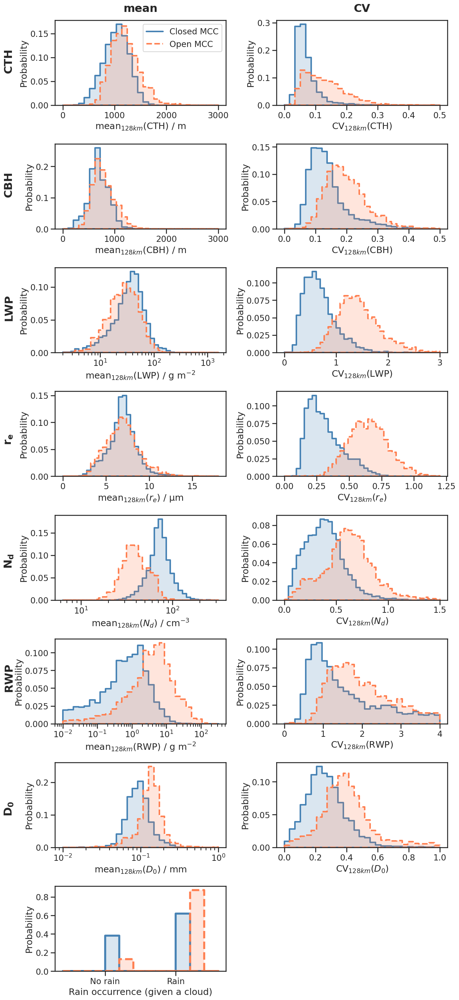

In [46]:
nrows = 8

vars_to_plot = {
    'cth_m': [np.linspace(0,3000,30), 'linear', 'mean$_{128km}$(CTH) / m'],
    'cth_m_cv': [np.linspace(0,0.5,30), 'linear', 'CV$_{128km}$(CTH)'],
    'cbh_m': [np.linspace(0,3000,30), 'linear', 'mean$_{128km}$(CBH) / m'],
    'cbh_m_cv': [np.linspace(0,0.5,30), 'linear', 'CV$_{128km}$(CBH)'],
    'lwp_fil': [np.logspace(0.3,3.2,40), 'log', 'mean$_{128km}$(LWP) / g m$^{-2}$'],
    'lwp_cv': [np.linspace(0,3,40), 'linear', 'CV$_{128km}$(LWP)'],
    'ER_fil': [np.linspace(0,18,40), 'linear', 'mean$_{128km}$($r_e$) / µm'],
    'ER_cv': [np.linspace(0,1.2,40), 'linear', 'CV$_{128km}$($r_e$)'],
    'Nd_fil': [np.logspace(0.8,2.5,40), 'log', 'mean$_{128km}$($N_d$) / cm$^{-3}$'],
    'Nd_cv': [np.linspace(0,1.5,40), 'linear', 'CV$_{128km}$($N_d$)'],
    'rwp': [np.logspace(-2,2.5,30), 'log', 'mean$_{128km}$(RWP) / g m$^{-2}$'],
    'rwp_cv': [np.linspace(0,4,30), 'linear', 'CV$_{128km}$(RWP)'],
    'rain_median_volume_diameter': [np.logspace(-2,0,30), 'log', 'mean$_{128km}$($D_0$) / mm'],
    'rain_median_volume_diameter_cv': [np.linspace(0,1,30), 'linear', 'CV$_{128km}$($D_0$)']
}


fig, ax = plt.subplots(nrows,2, figsize=(13, 3.5*nrows))
axs = ax.flatten()
for i, (var, plot_params) in enumerate(vars_to_plot.items()):
    for j in [1,2]: #[0,1,2,3,4,5]: 
        if 'cv' in var:
            if 'lwp' in var or 'Nd' in var or 'ER' in var:
                dffil[var] = dffil[var.replace('_cv','_std')] / dffil[var.replace('_cv','_fil')]
            else:
                dffil[var] = dffil[var.replace('_cv','_std')] / dffil[var.replace('_cv','')]
        histplot_with_style(j, axs[i], dffil, var, plot_params[0])

        #for sr in [0,1,2,3]:
        #    sns.histplot(
        #        ax=axs[i], data=dffil[(dffil['cats'] == j) & (dffil['stratus_region_index'] == sr)], x=var, bins=plot_params[0],
        #        element='step', stat='probability', fill=False, alpha=0.5, lw=1, ls=line_styles[j], 
        #        color=catcolors[j],
        #    )
    #axs[i].set_xlim(plot_params[0][0], plot_params[0][-1])
    axs[i].set_xscale(plot_params[1])
    axs[i].set_xlabel(plot_params[2])

for j in [1,2]:
    sns.histplot(ax=axs[-2], x=(dffil[dffil['cats'] == j]['rwp'] > 0) + j*0.2, bins=np.arange(-0.5,1.8,0.2), 
                element='step', alpha=0.2, stat='probability', color=catcolors[j], lw=4, ls=line_styles[j])
axs[-2].set_xticks([0.1,1.1])
axs[-2].set_xticklabels(['No rain', 'Rain'])
axs[-2].set_xlabel('Rain occurrence (given a cloud)')
axs[-1].axis('off')


legend_elements = [
    Line2D([0], [0], color=catcolors[i], lw=3, linestyle=line_styles[i], label=cats_names[i])
    for i in [1,2]
]
axs[0].legend(handles=legend_elements, loc='upper right')
axs[0].annotate('mean', xy=(0.4, 1.1), xycoords='axes fraction', fontsize=22, fontweight='bold')
axs[1].annotate('CV', xy=(0.45, 1.1), xycoords='axes fraction', fontsize=22, fontweight='bold')
for idx, text in enumerate(['CTH','CBH','LWP','$\mathbf{r_e}$','$\mathbf{N_d}$','RWP','$\mathbf{D_0}$']):
    ax[idx,0].annotate(text, xy=(-0.3, 0.4), xycoords='axes fraction', rotation=90, fontsize=22, fontweight='bold')

fig.tight_layout()
plt.savefig('./figures/cloud_rain_histograms.png', dpi=300)

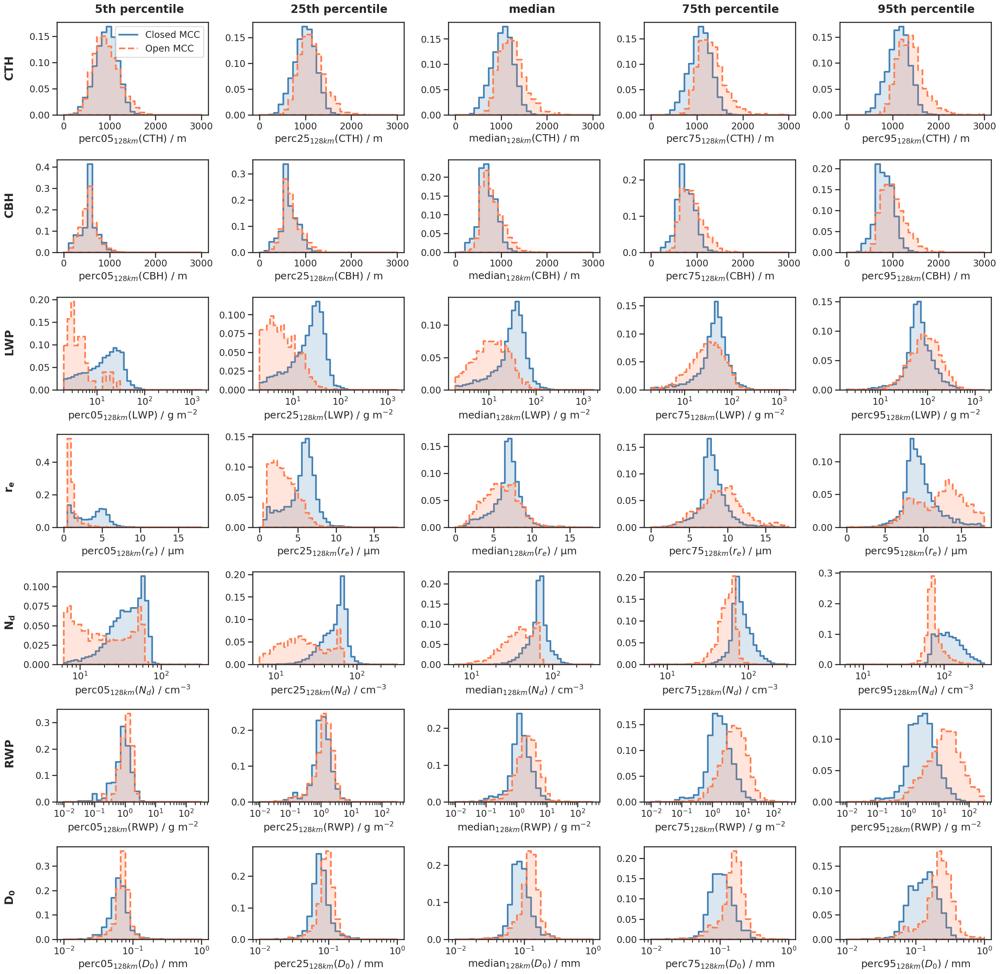

In [47]:
nrows = 7

vars_to_plot_perc = {
    'cth_m_perc05': [np.linspace(0,3000,30), 'linear', 'perc05$_{128km}$(CTH) / m'],
    'cth_m_perc25': [np.linspace(0,3000,30), 'linear', 'perc25$_{128km}$(CTH) / m'],
    'cth_m_median': [np.linspace(0,3000,30), 'linear', 'median$_{128km}$(CTH) / m'],
    'cth_m_perc75': [np.linspace(0,3000,30), 'linear', 'perc75$_{128km}$(CTH) / m'],
    'cth_m_perc95': [np.linspace(0,3000,30), 'linear', 'perc95$_{128km}$(CTH) / m'],
    #
    'cbh_m_perc05': [np.linspace(0,3000,30), 'linear', 'perc05$_{128km}$(CBH) / m'],
    'cbh_m_perc25': [np.linspace(0,3000,30), 'linear', 'perc25$_{128km}$(CBH) / m'],
    'cbh_m_median': [np.linspace(0,3000,30), 'linear', 'median$_{128km}$(CBH) / m'],
    'cbh_m_perc75': [np.linspace(0,3000,30), 'linear', 'perc75$_{128km}$(CBH) / m'],
    'cbh_m_perc95': [np.linspace(0,3000,30), 'linear', 'perc95$_{128km}$(CBH) / m'],
    #
    'lwp_perc05': [np.logspace(0.3,3.2,40), 'log', 'perc05$_{128km}$(LWP) / g m$^{-2}$'],
    'lwp_perc25': [np.logspace(0.3,3.2,40), 'log', 'perc25$_{128km}$(LWP) / g m$^{-2}$'],
    'lwp_median': [np.logspace(0.3,3.2,40), 'log', 'median$_{128km}$(LWP) / g m$^{-2}$'],
    'lwp_perc75': [np.logspace(0.3,3.2,40), 'log', 'perc75$_{128km}$(LWP) / g m$^{-2}$'],
    'lwp_perc95': [np.logspace(0.3,3.2,40), 'log', 'perc95$_{128km}$(LWP) / g m$^{-2}$'],
    #
    'ER_perc05': [np.linspace(0,18,40), 'linear', 'perc05$_{128km}$($r_e$) / µm'],
    'ER_perc25': [np.linspace(0,18,40), 'linear', 'perc25$_{128km}$($r_e$) / µm'],
    'ER_median': [np.linspace(0,18,40), 'linear', 'median$_{128km}$($r_e$) / µm'],
    'ER_perc75': [np.linspace(0,18,40), 'linear', 'perc75$_{128km}$($r_e$) / µm'],
    'ER_perc95': [np.linspace(0,18,40), 'linear', 'perc95$_{128km}$($r_e$) / µm'],
    #
    'Nd_perc05': [np.logspace(0.8,2.5,40), 'log', 'perc05$_{128km}$($N_d$) / cm$^{-3}$'],
    'Nd_perc25': [np.logspace(0.8,2.5,40), 'log', 'perc25$_{128km}$($N_d$) / cm$^{-3}$'],
    'Nd_median': [np.logspace(0.8,2.5,40), 'log', 'median$_{128km}$($N_d$) / cm$^{-3}$'],
    'Nd_perc75': [np.logspace(0.8,2.5,40), 'log', 'perc75$_{128km}$($N_d$) / cm$^{-3}$'],
    'Nd_perc95': [np.logspace(0.8,2.5,40), 'log', 'perc95$_{128km}$($N_d$) / cm$^{-3}$'],
    #
    'rwp_perc05': [np.logspace(-2,2.5,30), 'log', 'perc05$_{128km}$(RWP) / g m$^{-2}$'],
    'rwp_perc25': [np.logspace(-2,2.5,30), 'log', 'perc25$_{128km}$(RWP) / g m$^{-2}$'],
    'rwp_median': [np.logspace(-2,2.5,30), 'log', 'median$_{128km}$(RWP) / g m$^{-2}$'],
    'rwp_perc75': [np.logspace(-2,2.5,30), 'log', 'perc75$_{128km}$(RWP) / g m$^{-2}$'],
    'rwp_perc95': [np.logspace(-2,2.5,30), 'log', 'perc95$_{128km}$(RWP) / g m$^{-2}$'],
    #
    'rain_median_volume_diameter_perc05': [np.logspace(-2,0,30), 'log', 'perc05$_{128km}$($D_0$) / mm'],
    'rain_median_volume_diameter_perc25': [np.logspace(-2,0,30), 'log', 'perc25$_{128km}$($D_0$) / mm'],
    'rain_median_volume_diameter_median': [np.logspace(-2,0,30), 'log', 'median$_{128km}$($D_0$) / mm'],
    'rain_median_volume_diameter_perc75': [np.logspace(-2,0,30), 'log', 'perc75$_{128km}$($D_0$) / mm'],
    'rain_median_volume_diameter_perc95': [np.logspace(-2,0,30), 'log', 'perc95$_{128km}$($D_0$) / mm']
}



fig, ax = plt.subplots(nrows,5, figsize=(25, 3.5*nrows))
axs = ax.flatten()
for i, (var, plot_params) in enumerate(vars_to_plot_perc.items()):
    for j in [1,2]: #[0,1,2,3,4,5]: 
        histplot_with_style(j, axs[i], dffil, var, plot_params[0])
    #axs[i].set_xlim(plot_params[0][0], plot_params[0][-1])
    axs[i].set_xscale(plot_params[1])
    axs[i].set_xlabel(plot_params[2])

for a in axs:
    a.set_ylabel('')

legend_elements = [
    Line2D([0], [0], color=catcolors[i], lw=3, linestyle=line_styles[i], label=cats_names[i])
    for i in [1,2]
]
axs[0].legend(handles=legend_elements, loc='upper right')

axs[0].annotate('5th percentile', xy=(0.25, 1.1), xycoords='axes fraction', fontsize=20, fontweight='bold')
axs[1].annotate('25th percentile', xy=(0.25, 1.1), xycoords='axes fraction', fontsize=20, fontweight='bold')
axs[2].annotate('median', xy=(0.4, 1.1), xycoords='axes fraction', fontsize=20, fontweight='bold')
axs[3].annotate('75th percentile', xy=(0.25, 1.1), xycoords='axes fraction', fontsize=20, fontweight='bold')
axs[4].annotate('95th percentile', xy=(0.25, 1.1), xycoords='axes fraction', fontsize=20, fontweight='bold')
for idx, text in enumerate(['CTH','CBH','LWP','$\mathbf{r_e}$','$\mathbf{N_d}$','RWP','$\mathbf{D_0}$']):
    ax[idx,0].annotate(text, xy=(-0.35, 0.4), xycoords='axes fraction', rotation=90, fontsize=20, fontweight='bold')

fig.tight_layout()
plt.savefig('./figures/cloud_rain_histograms_perc.png', dpi=300)

## relationships: LWP, H, RWP

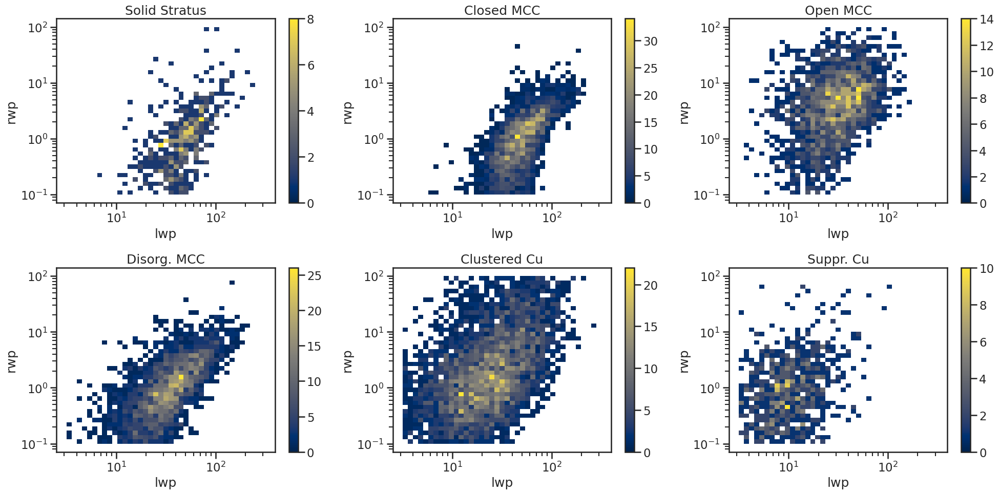

In [73]:
fig, axs = plt.subplots(2,3,figsize=(20,10))
for i in [0,1,2,3,4,5]:
    sns.histplot(ax=axs.flatten()[i], data=dffil[dffil.cats==i], x='lwp', y='rwp', bins=( np.logspace(0.5,2.5,40), np.logspace(-1,2,40)), cbar=True, cmap='cividis')
    xline = np.linspace(0,15,100)
    yline = (xline)**2 + 10
    #axs.flatten()[i].plot(xline, yline, color='black', lw=2)
    axs.flatten()[i].set_yscale('log')
    axs.flatten()[i].set_xscale('log')
    axs.flatten()[i].set_title(cats_names[i])
fig.tight_layout()

Text(0.5, 1.0, 'Mean RWP given LWP for different cloud categories')

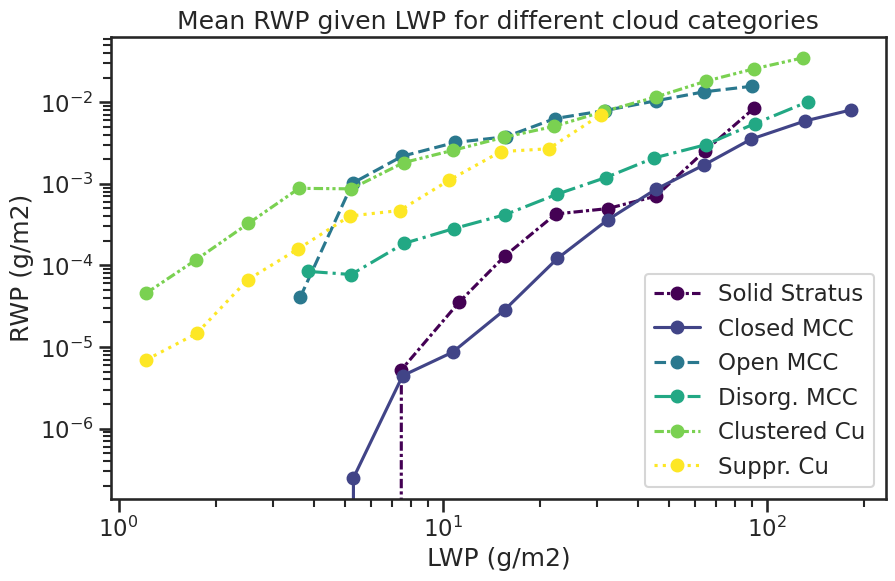

In [39]:
fig, axs = plt.subplots(1,1,figsize=(10,6))
for i in [0,1,2,3,4,5]:
    tmp = dffil[(dffil.cats==i)]
    rwp_given_lwp = tmp[['lwp','rwp']].groupby(pd.cut(tmp['lwp'], np.logspace(0,3,20))).mean()
    rwp_given_lwp['size'] = tmp.groupby(pd.cut(tmp['lwp'], np.logspace(0,3,20))).size()
    rwp_given_lwp['rwp'] = rwp_given_lwp['rwp'].where(rwp_given_lwp['size'] >= 20, np.nan)
    rwp_given_lwp.plot(y='rwp', x='lwp', logy=True, logx=True,marker='o', ax=axs, label=cats_names[i], color=catcolors[i], linestyle=line_styles[i])
    # rotate xlabels and round to 1 decimal place
    #plt.xticks(rotation=45)
#plt.ylim(-10,160)
plt.xlabel('LWP (g/m2)')
plt.ylabel('RWP (g/m2)')
plt.title('Mean RWP given LWP for different cloud categories')

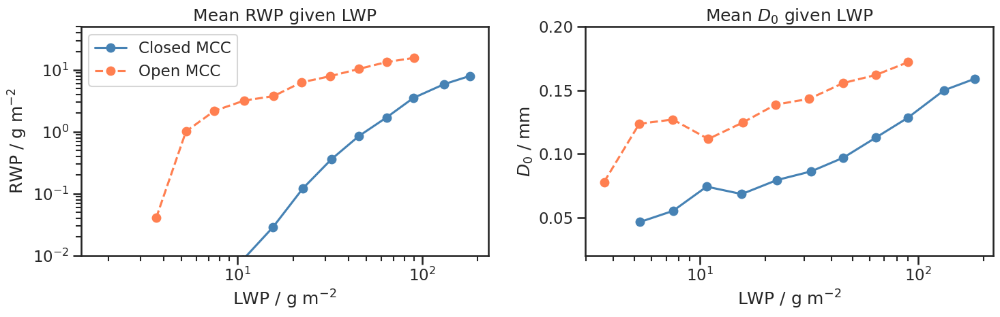

In [48]:
fig, axs = plt.subplots(1,2,figsize=(15,5))
for i in [1,2]:
    ax=axs[0]
    tmp = dffil[(dffil.cats==i)]
    rwp_given_lwp = tmp[['lwp','rwp']].groupby(pd.cut(tmp['lwp'], np.logspace(0,3,20))).mean()
    rwp_given_lwp['size'] = tmp.groupby(pd.cut(tmp['lwp'], np.logspace(0,3,20))).size()
    rwp_given_lwp['rwp'] = rwp_given_lwp['rwp'].where(rwp_given_lwp['size'] >= 20, np.nan)
    rwp_given_lwp.plot(y='rwp', x='lwp', logy=True, logx=True, marker='o', ax=ax, label=cats_names[i], color=catcolors[i], linestyle=line_styles[i])
    #for sr in [0,1,2,3]:
    #    tmp = dffil[(dffil.cats==i) & (dffil.stratus_region_index == sr)]
    #    rwp_given_lwp = tmp[['lwp','rwp']].groupby(pd.cut(tmp['lwp'], np.logspace(0,3,20))).mean()
    #    rwp_given_lwp['size'] = tmp.groupby(pd.cut(tmp['lwp'], np.logspace(0,3,20))).size()
    #    rwp_given_lwp['rwp'] = rwp_given_lwp['rwp'].where(rwp_given_lwp['size'] >= 20, np.nan)
    #    rwp_given_lwp.plot(y='rwp', x='lwp', logy=True, logx=True,ax=ax, label=cats_names[i], color=catcolors[i], linestyle=line_styles[i], lw=1, legend=False, alpha=0.5)
    ax.set_ylim(1e-2,5e1)
    ax.set_xlabel('LWP / g m$^{-2}$')
    ax.set_ylabel('RWP / g m$^{-2}$')
    ax.set_title('Mean RWP given LWP')

    ax=axs[1]
    tmp = dffil[(dffil.cats==i)]
    rvd_given_lwp = tmp[['lwp','rain_median_volume_diameter']].groupby(pd.cut(tmp['lwp'], np.logspace(0,3,20))).mean()
    rvd_given_lwp['size'] = tmp.groupby(pd.cut(tmp['lwp'], np.logspace(0,3,20))).size()
    rvd_given_lwp['rain_median_volume_diameter'] = rvd_given_lwp['rain_median_volume_diameter'].where(rvd_given_lwp['size'] >= 20, np.nan)
    rvd_given_lwp.plot(y='rain_median_volume_diameter', x='lwp', logy=False, logx=True,marker='o', ax=ax, label=cats_names[i], color=catcolors[i], linestyle=line_styles[i], legend=False)
    #for sr in [0,1,2,3]:
    #    tmp = dffil[(dffil.cats==i) & (dffil.stratus_region_index == sr)]
    #    rvd_given_lwp = tmp[['lwp','rain_median_volume_diameter']].groupby(pd.cut(tmp['lwp'], np.logspace(0,3,20))).mean()
    #    rvd_given_lwp['size'] = tmp.groupby(pd.cut(tmp['lwp'], np.logspace(0,3,20))).size()
    #    rvd_given_lwp['rain_median_volume_diameter'] = rvd_given_lwp['rain_median_volume_diameter'].where(rvd_given_lwp['size'] >= 20, np.nan)
    #    rvd_given_lwp.plot(y='rain_median_volume_diameter', x='lwp', logy=False, logx=True, ax=ax, label=cats_names[i], color=catcolors[i], linestyle=line_styles[i], lw=1, legend=False, alpha=0.5)
    ax.set_ylim(2e-2,2e-1)
    ax.set_xlabel('LWP / g m$^{-2}$')
    ax.set_ylabel('$D_0$ / mm')
    ax.set_title('Mean $D_0$ given LWP')

fig.tight_layout()
plt.savefig('./figures/rwp_rvd_given_lwp.png', dpi=300)

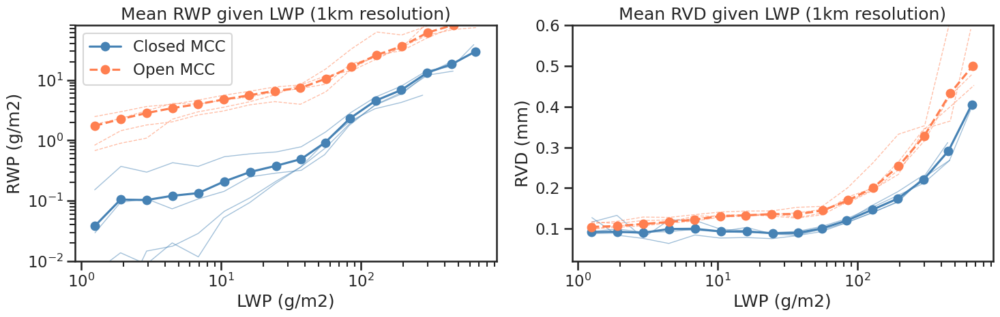

In [ ]:
fig, axs = plt.subplots(1,2,figsize=(15,5))
for i in [1,2]:
    ax=axs[0]
    tmp = dffil_1km[(dffil_1km.cats==i)]
    rwp_given_lwp = tmp[['lwp','rwp']].groupby(pd.cut(tmp['lwp'], np.logspace(0,3.5,20))).mean()
    rwp_given_lwp['size'] = tmp.groupby(pd.cut(tmp['lwp'], np.logspace(0,3.5,20))).size()
    rwp_given_lwp['rwp'] = rwp_given_lwp['rwp'].where(rwp_given_lwp['size'] >= 20, np.nan)
    rwp_given_lwp.plot(y='rwp', x='lwp', logy=True, logx=True, marker='o', ax=ax, label=cats_names[i], color=catcolors[i], linestyle=line_styles[i])
    for sr in [0,1,2,3]:
        tmp = dffil_1km[(dffil_1km.cats==i) & (dffil_1km.stratus_region_index == sr)]
        rwp_given_lwp = tmp[['lwp','rwp']].groupby(pd.cut(tmp['lwp'], np.logspace(0,3.5,20))).mean()
        rwp_given_lwp['size'] = tmp.groupby(pd.cut(tmp['lwp'], np.logspace(0,3.5,20))).size()
        rwp_given_lwp['rwp'] = rwp_given_lwp['rwp'].where(rwp_given_lwp['size'] >= 20, np.nan)
        rwp_given_lwp.plot(y='rwp', x='lwp', logy=True, logx=True,ax=ax, label=cats_names[i], color=catcolors[i], linestyle=line_styles[i], lw=1, legend=False, alpha=0.5)
    ax.set_ylim(1e-2,8e1)
    ax.set_xlabel('LWP (g/m2)')
    ax.set_ylabel('RWP (g/m2)')
    ax.set_title('Mean RWP given LWP (1km resolution)')

    ax=axs[1]
    tmp = dffil_1km[(dffil_1km.cats==i)]
    rvd_given_lwp = tmp[['lwp','rain_median_volume_diameter']].groupby(pd.cut(tmp['lwp'], np.logspace(0,3.5,20))).mean()
    rvd_given_lwp['size'] = tmp.groupby(pd.cut(tmp['lwp'], np.logspace(0,3.5,20))).size()
    rvd_given_lwp['rain_median_volume_diameter'] = rvd_given_lwp['rain_median_volume_diameter'].where(rvd_given_lwp['size'] >= 20, np.nan)
    rvd_given_lwp.plot(y='rain_median_volume_diameter', x='lwp', logy=False, logx=True,marker='o', ax=ax, label=cats_names[i], color=catcolors[i], linestyle=line_styles[i], legend=False)
    for sr in [0,1,2,3]:
        tmp = dffil_1km[(dffil_1km.cats==i) & (dffil_1km.stratus_region_index == sr)]
        rvd_given_lwp = tmp[['lwp','rain_median_volume_diameter']].groupby(pd.cut(tmp['lwp'], np.logspace(0,3.5,20))).mean()
        rvd_given_lwp['size'] = tmp.groupby(pd.cut(tmp['lwp'], np.logspace(0,3.5,20))).size()
        rvd_given_lwp['rain_median_volume_diameter'] = rvd_given_lwp['rain_median_volume_diameter'].where(rvd_given_lwp['size'] >= 20, np.nan)
        rvd_given_lwp.plot(y='rain_median_volume_diameter', x='lwp', logy=False, logx=True, ax=ax, label=cats_names[i], color=catcolors[i], linestyle=line_styles[i], lw=1, legend=False, alpha=0.5)
    ax.set_ylim(2e-2,6e-1)
    ax.set_xlabel('LWP (g/m2)')
    ax.set_ylabel('$D_0$ (mm)')
    ax.set_title('Mean $D_0$ given LWP (1km resolution)')

fig.tight_layout()

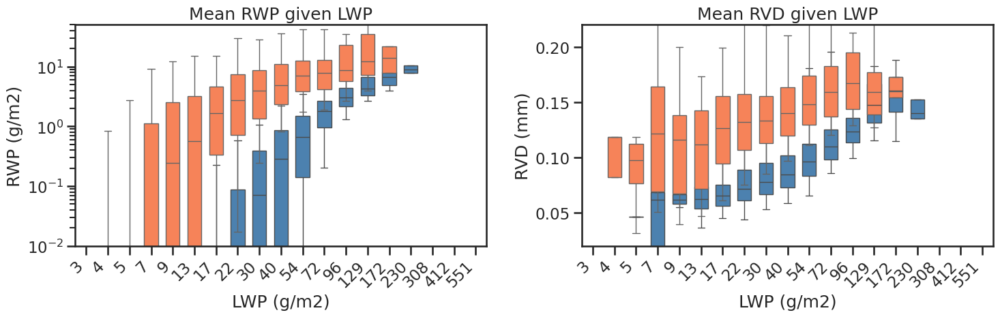

In [ ]:

fig, axs = plt.subplots(1,2,figsize=(15,5))
for i in [1,2]:
    ax=axs[0]
    tmp = dffil[(dffil.cats == i)][['rwp', 'lwp', 'cats']]
    tmp['lwp_binned'] = pd.cut(tmp['lwp'], bins=np.logspace(0.4,2.8,20))
    tmp['lwp_binned'] = tmp['lwp_binned'].apply(lambda x: np.round(x.mid))
    sns.boxplot(ax=ax, data=tmp, y='rwp', x='lwp_binned', whis=(5, 95), native_scale=False, showfliers=False, saturation=0.9, color=catcolors[i], gap=1.8)
    tmp_median = tmp.groupby('lwp_binned').median().reset_index()
    #sns.scatterplot(ax=ax, data=tmp_median, x='lwp_binned', y='rwp', color='black', marker='d', s=150, zorder=2)
    ax.set_yscale('log')
    ax.set_ylim(1e-2,5e1)
    ax.set_xlabel('LWP (g/m2)')
    ax.set_ylabel('RWP (g/m2)')
    ax.set_title('Mean RWP given LWP')
    # Create labels showing bin edges in log format
    bins=np.logspace(0.4,2.8,20)
    bin_labels = [f'{pd.Interval(bins[i], bins[i+1]).mid:.0f}' for i in range(len(bins)-1)]
    ax.set_xticklabels(bin_labels, rotation=45, ha='right')


    ax=axs[1]
    tmp = dffil[(dffil.cats == i)][['rain_median_volume_diameter', 'lwp', 'cats']]
    tmp['lwp_binned'] = pd.cut(tmp['lwp'], bins=np.logspace(0.4,2.8,20))
    tmp['lwp_binned'] = tmp['lwp_binned'].apply(lambda x: np.round(x.mid))
    sns.boxplot(ax=ax, data=tmp, y='rain_median_volume_diameter', x='lwp_binned', whis=(5, 95), native_scale=False, showfliers=False, saturation=0.9, color=catcolors[i], gap=1.8)
    tmp_median = tmp.groupby('lwp_binned').median().reset_index()
    #sns.scatterplot(ax=ax, data=tmp_median, x='lwp_binned', y='rain_median_volume_diameter', color='black', marker='d', s=150, zorder=2)
    bin_labels = [f'{pd.Interval(bins[i], bins[i+1]).mid:.0f}' for i in range(len(bins)-1)]
    ax.set_xticklabels(bin_labels, rotation=45, ha='right')
    ax.set_ylim(2e-2,2.2e-1)
    ax.set_xlabel('LWP (g/m2)')
    ax.set_ylabel('$D_0$ (mm)')
    ax.set_title('Mean $D_0$ given LWP')

fig.tight_layout()

Text(0.5, 1.0, 'Mean RWP given LWP')

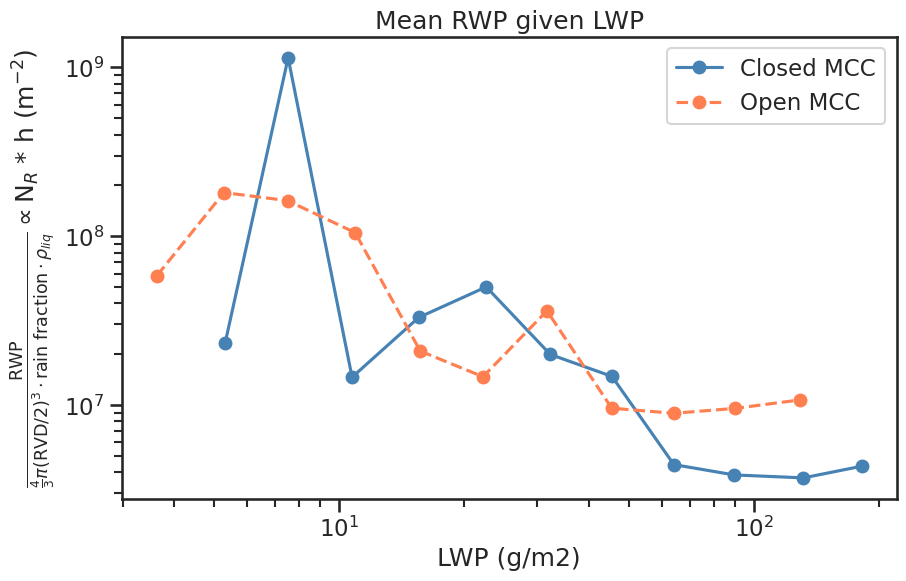

In [ ]:
fig, axs = plt.subplots(1,1,figsize=(10,6))
for i in [1,2]:
    tmp = dffil[(dffil.cats==i)]
    tmp['rwp_divided_by_rvd3'] = tmp['rwp']*1e-3 / (4/3 * np.pi * (tmp['rain_median_volume_diameter']*1e-3/2)**3) / tmp['rain_fraction'] * 1e-3
    rwp_given_lwp = tmp[['lwp','rwp_divided_by_rvd3']].groupby(pd.cut(tmp['lwp'], np.logspace(0,3,20))).mean()
    rwp_given_lwp['size'] = tmp.groupby(pd.cut(tmp['lwp'], np.logspace(0,3,20))).size()
    rwp_given_lwp['rwp_divided_by_rvd3'] = rwp_given_lwp['rwp_divided_by_rvd3'].where(rwp_given_lwp['size'] >= 10, np.nan)
    rwp_given_lwp.plot(y='rwp_divided_by_rvd3', x='lwp', logy=True, logx=True,marker='o', ax=axs, label=cats_names[i], color=catcolors[i], linestyle=line_styles[i])
    # rotate xlabels and round to 1 decimal place
    #plt.xticks(rotation=45)
#plt.ylim(1e-2,5e1)
plt.xlabel('LWP (g/m2)')
plt.ylabel('$\\frac{\\mathrm{RWP}}{\\frac{4}{3} \\pi (\\mathrm{$D_0$}/2)^3 \\cdot \\mathrm{rain\\ fraction} \\cdot \\rho_{liq}} \\propto \\mathrm{N}_R$ * h (m$^{-2}$)')
plt.title('Mean RWP given LWP')

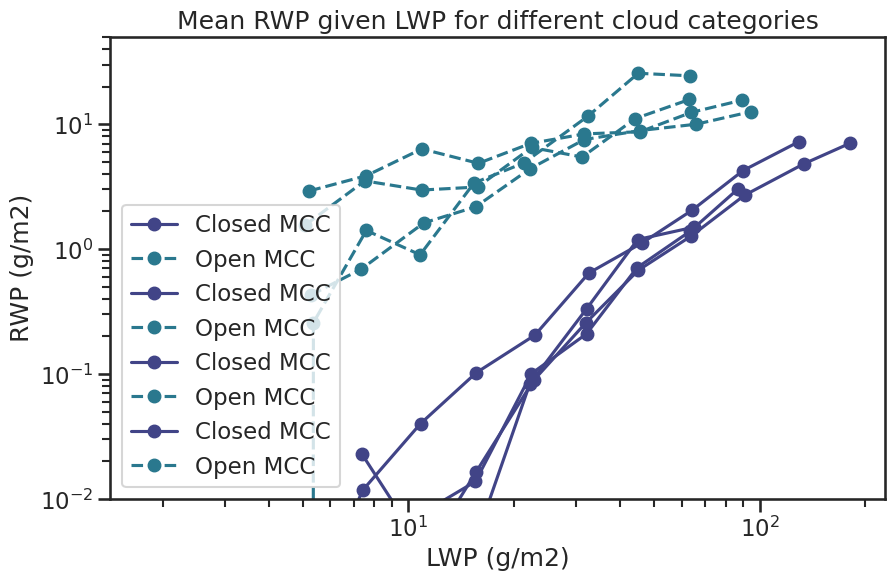

In [ ]:
fig, axs = plt.subplots(1,1,figsize=(10,6))
for sr in [0,1,2,3]:
    for i in [1,2]:
        tmp = dffil[(dffil.cats==i) & (dffil.stratus_region_index == sr)]
        rwp_given_lwp = tmp[['lwp','rwp']].groupby(pd.cut(tmp['lwp'], np.logspace(0,3,20))).mean()
        rwp_given_lwp['size'] = tmp.groupby(pd.cut(tmp['lwp'], np.logspace(0,3,20))).size()
        rwp_given_lwp['rwp'] = rwp_given_lwp['rwp'].where(rwp_given_lwp['size'] >= 10, np.nan)
        rwp_given_lwp.plot(y='rwp', x='lwp', logy=True, logx=True,marker='o', ax=axs, label=cats_names[i], color=catcolors[i], linestyle=line_styles[i])
        # rotate xlabels and round to 1 decimal place
        #plt.xticks(rotation=45)
    plt.ylim(1e-2,5e1)
    plt.xlabel('LWP (g/m2)')
    plt.ylabel('RWP (g/m2)')
    plt.title('Mean RWP given LWP for different cloud categories')

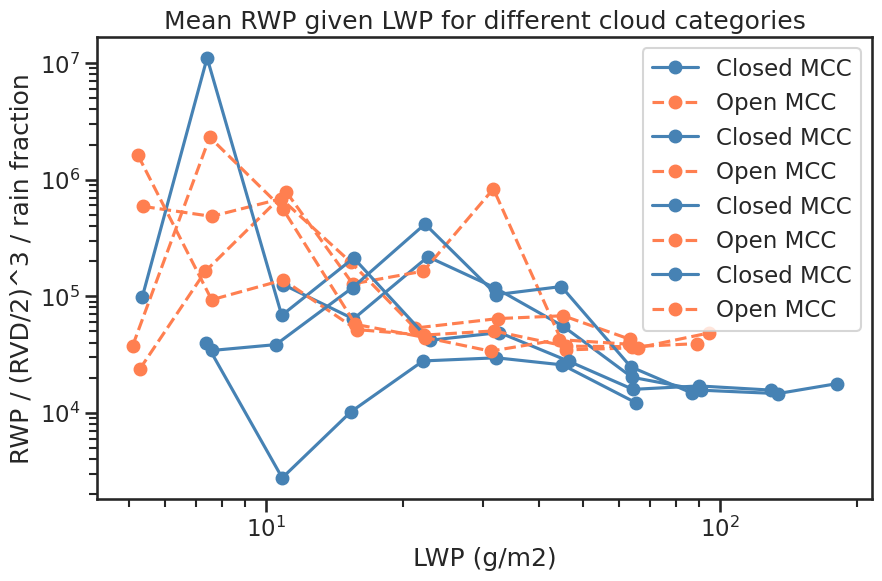

In [ ]:
fig, axs = plt.subplots(1,1,figsize=(10,6))
for sr in [0,1,2,3]:
    for i in [1,2]:
        tmp = dffil[(dffil.cats==i) & (dffil.stratus_region_index == sr)]
        tmp['rwp_divided_by_rvd3'] = tmp['rwp'] / ((tmp['rain_median_volume_diameter']/2)**3) / tmp['rain_fraction']
        rwp_given_lwp = tmp[['lwp','rwp_divided_by_rvd3']].groupby(pd.cut(tmp['lwp'], np.logspace(0,3,20))).mean()
        rwp_given_lwp['size'] = tmp.groupby(pd.cut(tmp['lwp'], np.logspace(0,3,20))).size()
        rwp_given_lwp['rwp_divided_by_rvd3'] = rwp_given_lwp['rwp_divided_by_rvd3'].where(rwp_given_lwp['size'] >= 10, np.nan)
        rwp_given_lwp.plot(y='rwp_divided_by_rvd3', x='lwp', logy=True, logx=True,marker='o', ax=axs, label=cats_names[i], color=catcolors[i], linestyle=line_styles[i])
        # rotate xlabels and round to 1 decimal place
        #plt.xticks(rotation=45)
    #plt.ylim(1e-2,5e1)
    plt.xlabel('LWP (g/m2)')
    plt.ylabel('RWP / ($D_0$/2)^3 / rain fraction')
    plt.title('Mean RWP given LWP for different cloud categories')

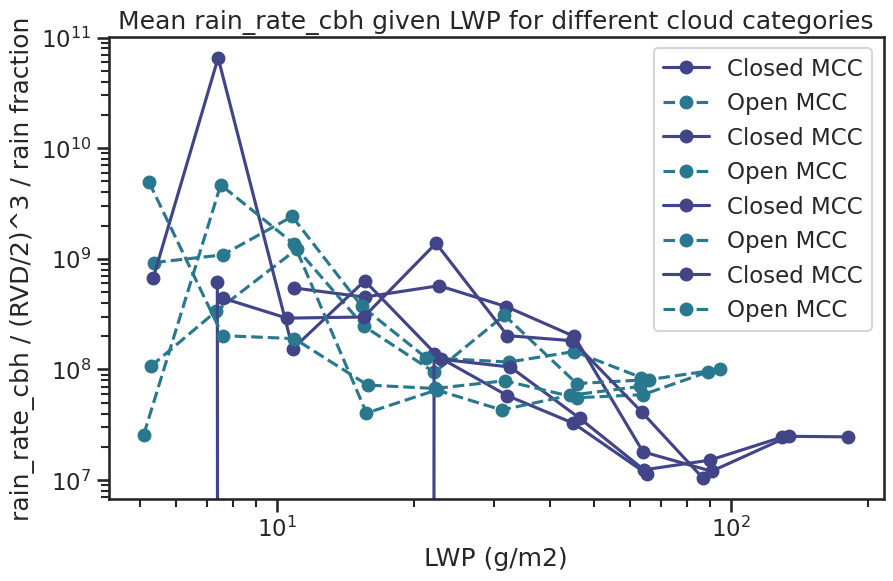

In [ ]:
fig, axs = plt.subplots(1,1,figsize=(10,6))
for sr in [0,1,2,3]:
    for i in [1,2]:
        tmp = dffil[(dffil.cats==i) & (dffil.stratus_region_index == sr)]
        tmp['rain_rate_cbh_divided_by_rvd3'] = tmp['rain_rate_cbh'] / ((tmp['rain_median_volume_diameter']/2)**3) / tmp['rain_fraction']
        rain_rate_cbh_given_lwp = tmp[['lwp','rain_rate_cbh_divided_by_rvd3']].groupby(pd.cut(tmp['lwp'], np.logspace(0,3,20))).mean()
        rain_rate_cbh_given_lwp['size'] = tmp.groupby(pd.cut(tmp['lwp'], np.logspace(0,3,20))).size()
        rain_rate_cbh_given_lwp['rain_rate_cbh_divided_by_rvd3'] = rain_rate_cbh_given_lwp['rain_rate_cbh_divided_by_rvd3'].where(rain_rate_cbh_given_lwp['size'] >= 10, np.nan)
        rain_rate_cbh_given_lwp.plot(y='rain_rate_cbh_divided_by_rvd3', x='lwp', logy=True, logx=True,marker='o', ax=axs, label=cats_names[i], color=catcolors[i], linestyle=line_styles[i])
        # rotate xlabels and round to 1 decimal place
        #plt.xticks(rotation=45)
    #plt.ylim(1e-2,5e1)
    plt.xlabel('LWP (g/m2)')
    plt.ylabel('rain_rate_cbh / ($D_0$/2)^3 / rain fraction')
    plt.title('Mean rain_rate_cbh given LWP for different cloud categories')

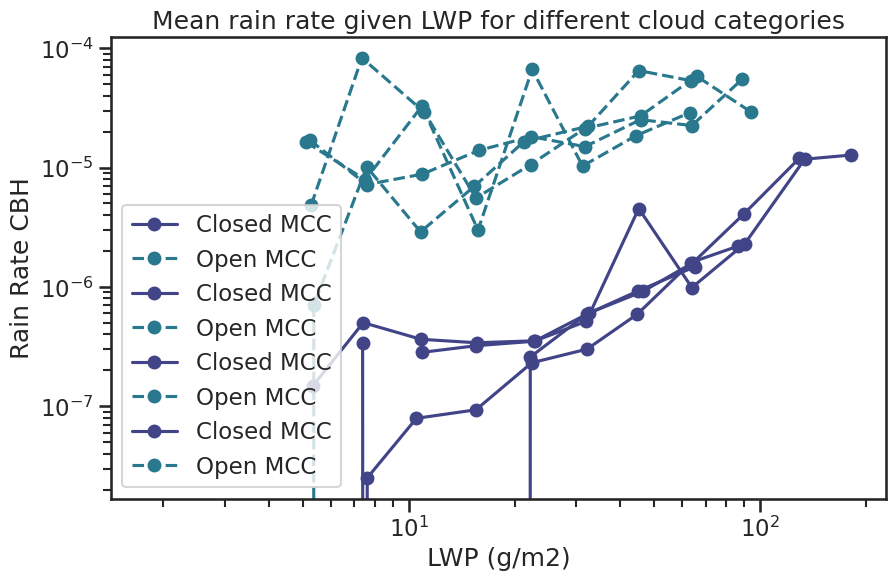

In [38]:
fig, axs = plt.subplots(1,1,figsize=(10,6))
for sr in [0,1,2,3]:
    for i in [1,2]:
        tmp = dffil[(dffil.cats==i) & (dffil.stratus_region_index == sr)]
        rain_rate_cbh_given_lwp = tmp[['lwp','rain_rate_cbh']].groupby(pd.cut(tmp['lwp'], np.logspace(0,3,20))).mean()
        rain_rate_cbh_given_lwp['size'] = tmp.groupby(pd.cut(tmp['lwp'], np.logspace(0,3,20))).size()
        rain_rate_cbh_given_lwp['rain_rate_cbh'] = rain_rate_cbh_given_lwp['rain_rate_cbh'].where(rain_rate_cbh_given_lwp['size'] >= 10, np.nan)
        rain_rate_cbh_given_lwp.plot(y='rain_rate_cbh', x='lwp', logy=True, logx=True,marker='o', ax=axs, label=cats_names[i], color=catcolors[i], linestyle=line_styles[i])
        # rotate xlabels and round to 1 decimal place
        #plt.xticks(rotation=45)
    #plt.ylim(1e-2,5e1)
    plt.xlabel('LWP (g/m2)')
    plt.ylabel('Rain Rate CBH')
    plt.title('Mean rain rate given LWP for different cloud categories')

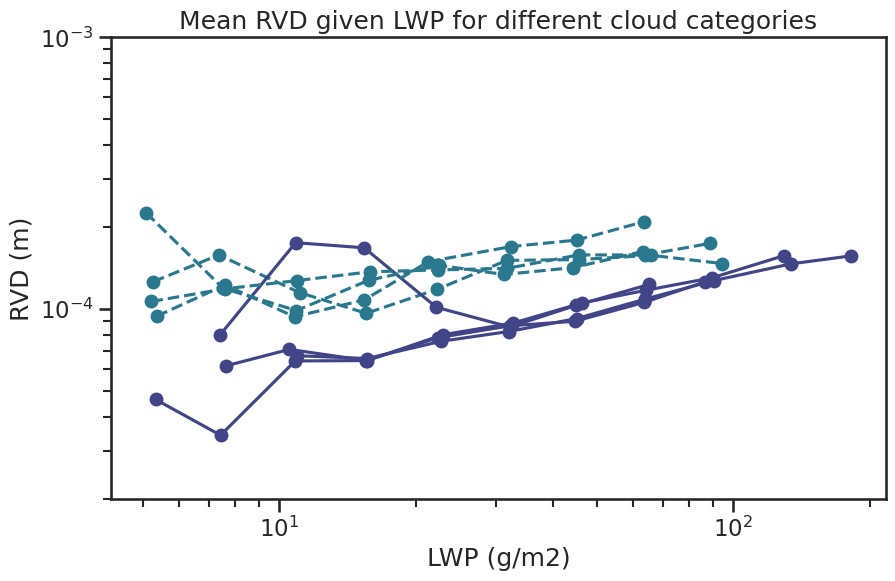

In [ ]:
fig, axs = plt.subplots(1,1,figsize=(10,6))
for sr in [0,1,2,3]:
    for i in [1,2]:
        tmp = dffil[(dffil.cats==i) & (dffil.stratus_region_index == sr)]
        rvd_given_lwp = tmp[['lwp','rain_median_volume_diameter']].groupby(pd.cut(tmp['lwp'], np.logspace(0,3,20))).mean()
        rvd_given_lwp['size'] = tmp.groupby(pd.cut(tmp['lwp'], np.logspace(0,3,20))).size()
        rvd_given_lwp['rain_median_volume_diameter'] = rvd_given_lwp['rain_median_volume_diameter'].where(rvd_given_lwp['size'] >= 10, np.nan)
        rvd_given_lwp.plot(y='rain_median_volume_diameter', x='lwp', logy=True, logx=True,marker='o', ax=axs, label=cats_names[i], color=catcolors[i], linestyle=line_styles[i], legend=False)
        # rotate xlabels and round to 1 decimal place
        #plt.xticks(rotation=45)
    plt.ylim(2e-5,1e-3)
    plt.xlabel('LWP (g/m2)')
    plt.ylabel('$D_0$ (m)')
    plt.title('Mean $D_0$ given LWP for different cloud categories')

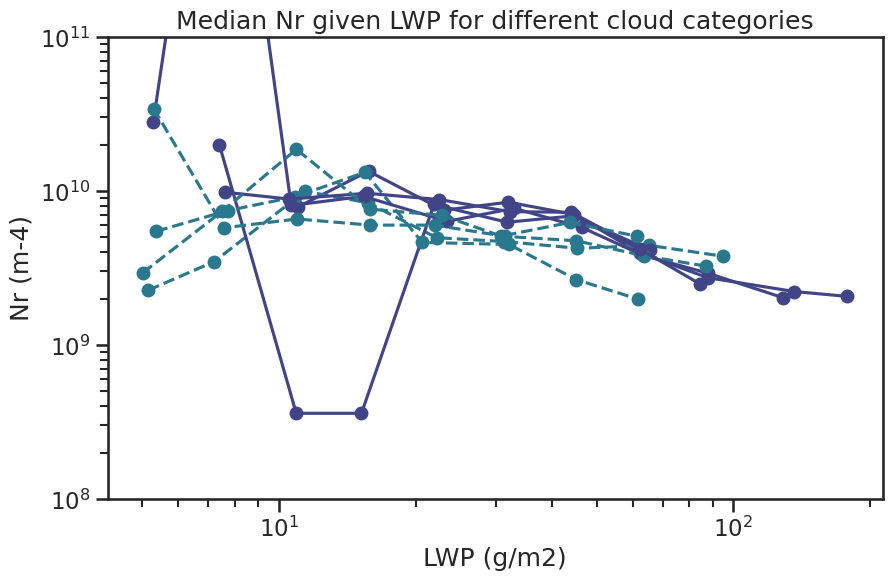

In [202]:
fig, axs = plt.subplots(1,1,figsize=(10,6))
for sr in [0,1,2,3]:
    for i in [1,2]:
        tmp = dffil[(dffil.cats==i) & (dffil.stratus_region_index == sr)]
        Nr_given_lwp = tmp[['lwp','rain_normalized_number_concentration']].groupby(pd.cut(tmp['lwp'], np.logspace(0,3,20))).median()
        Nr_given_lwp['size'] = tmp.groupby(pd.cut(tmp['lwp'], np.logspace(0,3,20))).size()
        Nr_given_lwp['rain_normalized_number_concentration'] = Nr_given_lwp['rain_normalized_number_concentration'].where(Nr_given_lwp['size'] >= 10, np.nan)
        Nr_given_lwp.plot(y='rain_normalized_number_concentration', x='lwp', logy=True, logx=True,marker='o', ax=axs, label=cats_names[i], color=catcolors[i], linestyle=line_styles[i], legend=False)
        # rotate xlabels and round to 1 decimal place
        #plt.xticks(rotation=45)
    plt.ylim(1e8, 1e11)
    plt.xlabel('LWP (g/m2)')
    plt.ylabel('Nr (m-4)')
    plt.title('Median Nr given LWP for different cloud categories')

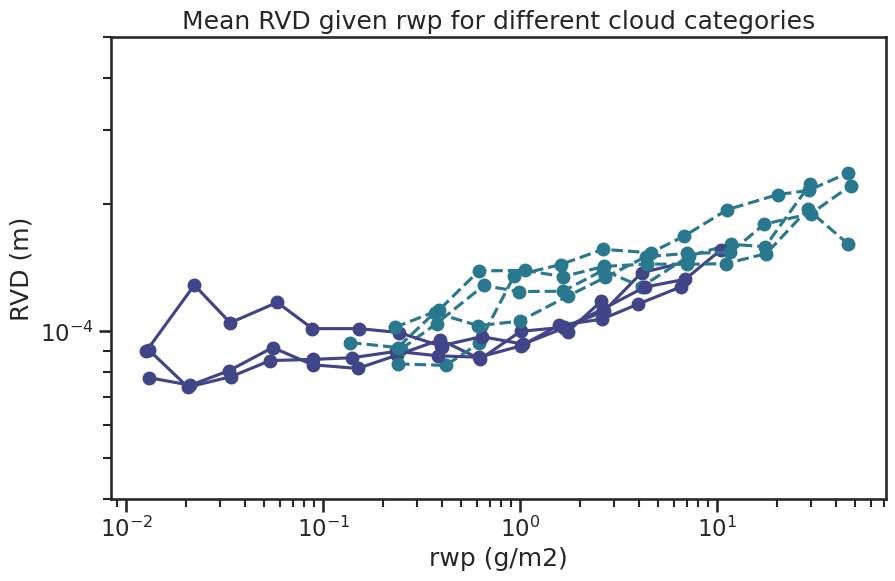

In [ ]:
fig, axs = plt.subplots(1,1,figsize=(10,6))
for sr in [0,1,2,3]:
    for i in [1,2]:
        tmp = dffil[(dffil.cats==i) & (dffil.stratus_region_index == sr)]
        rvd_given_rwp = tmp[['rwp','rain_median_volume_diameter']].groupby(pd.cut(tmp['rwp'], np.logspace(-2,2,20))).mean()
        rvd_given_rwp['size'] = tmp.groupby(pd.cut(tmp['rwp'], np.logspace(-2,2,20))).size()
        rvd_given_rwp['rain_median_volume_diameter'] = rvd_given_rwp['rain_median_volume_diameter'].where(rvd_given_rwp['size'] >= 10, np.nan)
        rvd_given_rwp.plot(y='rain_median_volume_diameter', x='rwp', logy=True, logx=True,marker='o', ax=axs, label=cats_names[i], color=catcolors[i], linestyle=line_styles[i], legend=False)
        # rotate xlabels and round to 1 decimal place
        #plt.xticks(rotation=45)
    plt.ylim(4e-5,5e-4)
    plt.xlabel('rwp (g/m2)')
    plt.ylabel('$D_0$ (m)')
    plt.title('Mean $D_0$ given rwp for different cloud categories')

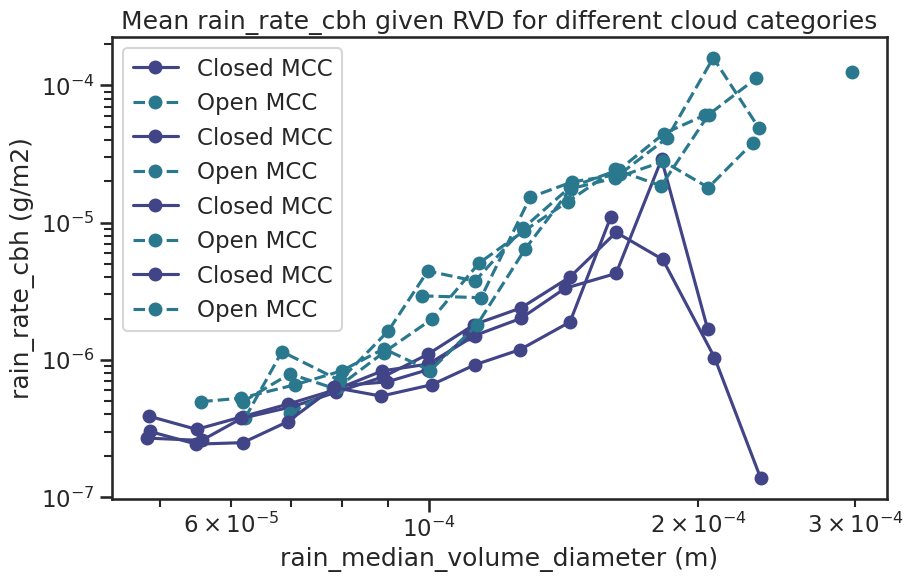

In [ ]:
fig, axs = plt.subplots(1,1,figsize=(10,6))
for sr in [0,1,2,3]:
    for i in [1,2]:
        tmp = dffil[(dffil.cats==i) & (dffil.stratus_region_index == sr)]
        rain_rate_cbh_given_rain_median_volume_diameter = tmp[['rain_median_volume_diameter','rain_rate_cbh']].groupby(pd.cut(tmp['rain_median_volume_diameter'], np.logspace(-4.5,-3.5,20))).mean()
        rain_rate_cbh_given_rain_median_volume_diameter['size'] = tmp.groupby(pd.cut(tmp['rain_median_volume_diameter'], np.logspace(-4.5,-3.5,20))).size()
        rain_rate_cbh_given_rain_median_volume_diameter['rain_rate_cbh'] = rain_rate_cbh_given_rain_median_volume_diameter['rain_rate_cbh'].where(rain_rate_cbh_given_rain_median_volume_diameter['size'] >= 10, np.nan)
        rain_rate_cbh_given_rain_median_volume_diameter.plot(y='rain_rate_cbh', x='rain_median_volume_diameter', logy=True, logx=True,marker='o', ax=axs, label=cats_names[i], color=catcolors[i], linestyle=line_styles[i])
        # rotate xlabels and round to 1 decimal place
        #plt.xticks(rotation=45)
    #plt.ylim(1e-1,5e1)
    plt.xlabel('rain_median_volume_diameter (m)')
    plt.ylabel('rain_rate_cbh (g/m2)')
    plt.title('Mean rain_rate_cbh given $D_0$ for different cloud categories')

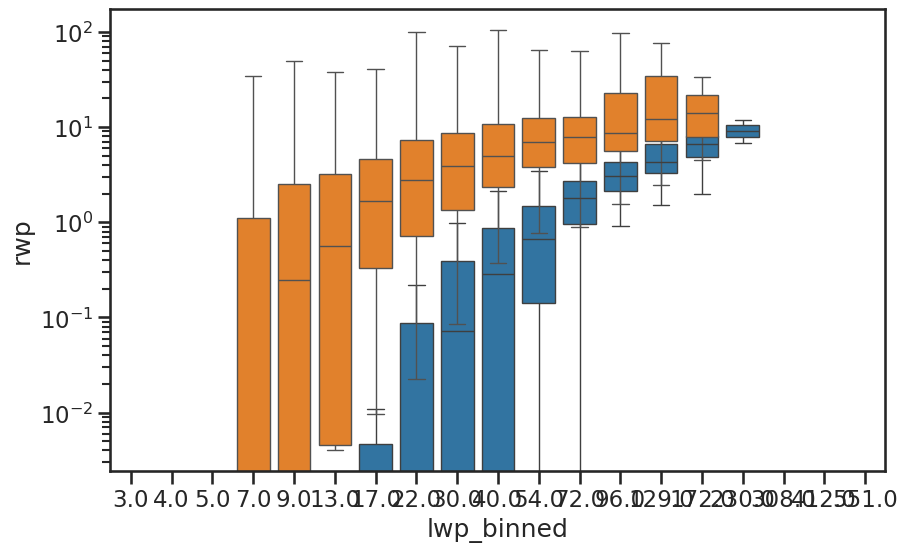

In [28]:
plt.figure(figsize=(10,6))
tmp = dffil[(dffil.cats.isin([1,2]))][['rwp', 'lwp', 'cats']]
tmp['lwp_binned'] = pd.cut(tmp['lwp'], bins=np.logspace(0.4,2.8,20))
tmp['lwp_binned'] = tmp['lwp_binned'].apply(lambda x: np.round(x.mid))
for i in [1,2]:
    sns.boxplot(data=tmp[tmp.cats == i], y='rwp', x='lwp_binned', showfliers=False)
    plt.yscale('log')

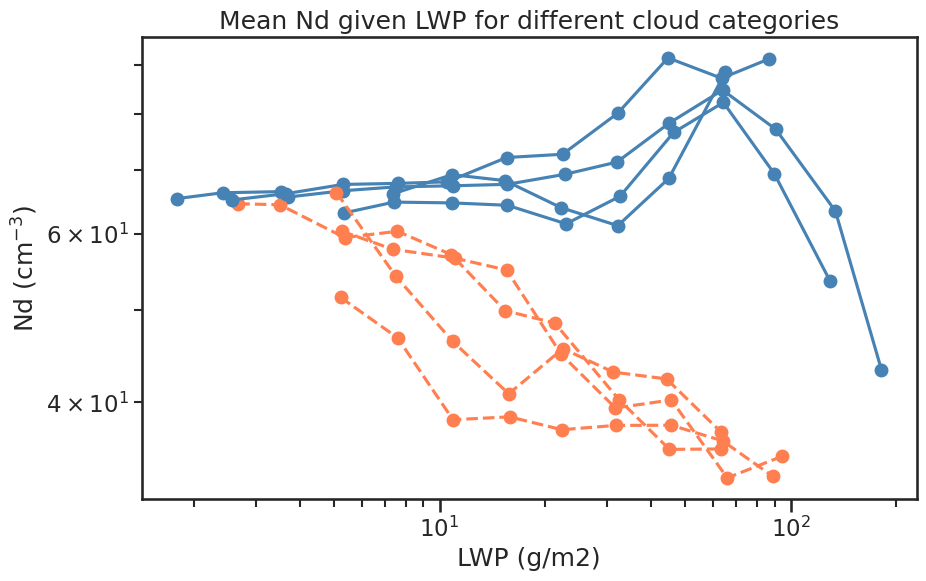

In [32]:
fig, axs = plt.subplots(1,1,figsize=(10,6))
for sr in [0,1,2,3]:
    for i in [1,2]:
        tmp = dffil[(dffil.cats==i) & (dffil.stratus_region_index == sr)]
        Nd_given_lwp = tmp[['lwp','Nd']].groupby(pd.cut(tmp['lwp'], np.logspace(0,3,20))).mean()
        Nd_given_lwp['size'] = tmp.groupby(pd.cut(tmp['lwp'], np.logspace(0,3,20))).size()
        Nd_given_lwp['Nd'] = Nd_given_lwp['Nd'].where(Nd_given_lwp['size'] >= 10, np.nan)
        Nd_given_lwp.plot(y='Nd', x='lwp', logy=True, logx=True,marker='o', ax=axs, label=cats_names[i], color=catcolors[i], linestyle=line_styles[i], legend=False)
        # rotate xlabels and round to 1 decimal place
        #plt.xticks(rotation=45)
    #plt.ylim(-10,160)
    plt.xlabel('LWP (g/m2)')
    plt.ylabel('Nd (cm$^{-3}$)')
    plt.title('Mean Nd given LWP for different cloud categories')

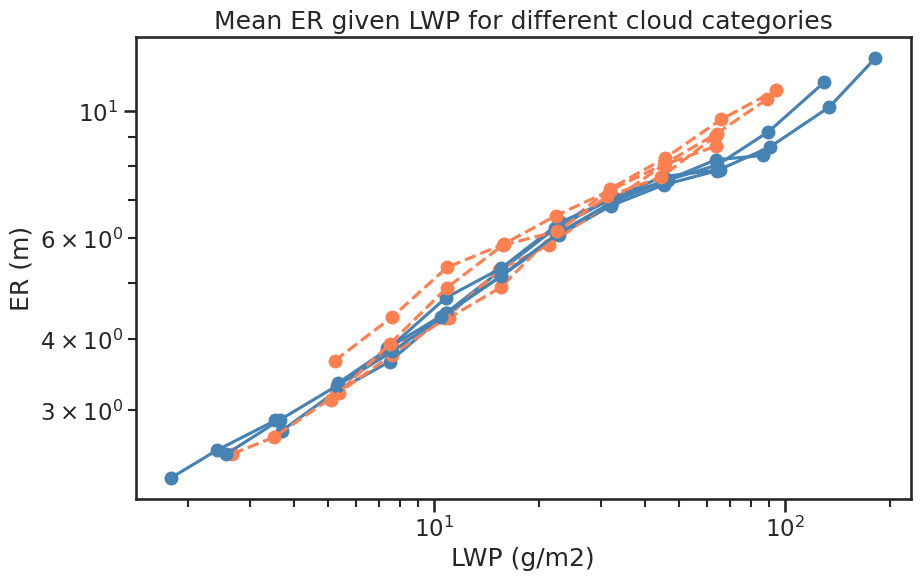

In [33]:
fig, axs = plt.subplots(1,1,figsize=(10,6))
for sr in [0,1,2,3]:
    for i in [1,2]:
        tmp = dffil[(dffil.cats==i) & (dffil.stratus_region_index == sr)]
        ER_given_lwp = tmp[['lwp','ER']].groupby(pd.cut(tmp['lwp'], np.logspace(0,3,20))).mean()
        ER_given_lwp['size'] = tmp.groupby(pd.cut(tmp['lwp'], np.logspace(0,3,20))).size()
        ER_given_lwp['ER'] = ER_given_lwp['ER'].where(ER_given_lwp['size'] >= 10, np.nan)
        ER_given_lwp.plot(y='ER', x='lwp', logy=True, logx=True,marker='o', ax=axs, label=cats_names[i], color=catcolors[i], linestyle=line_styles[i], legend=False)
        # rotate xlabels and round to 1 decimal place
        #plt.xticks(rotation=45)
    #plt.ylim(-10,160)
    plt.xlabel('LWP (g/m2)')
    plt.ylabel('ER (m)')
    plt.title('Mean ER given LWP for different cloud categories')

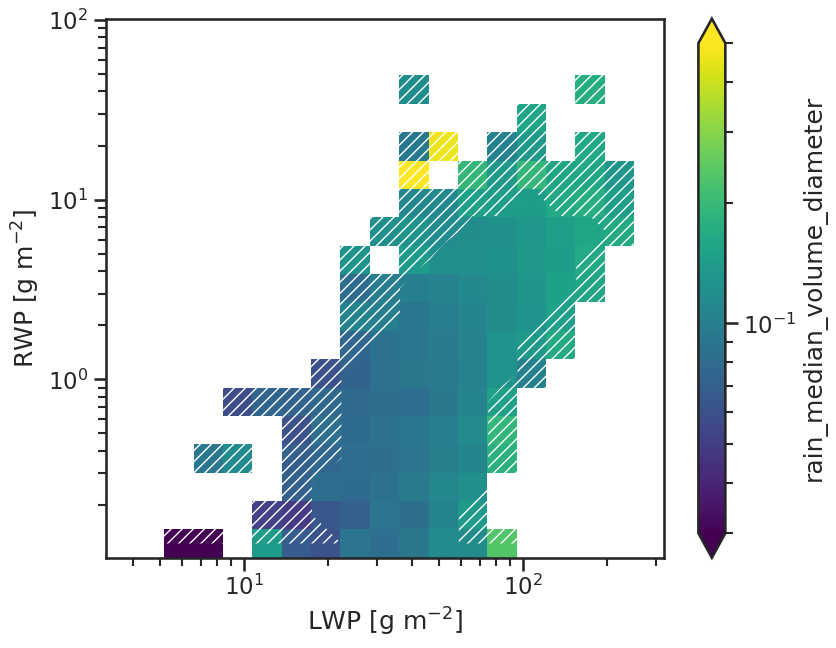

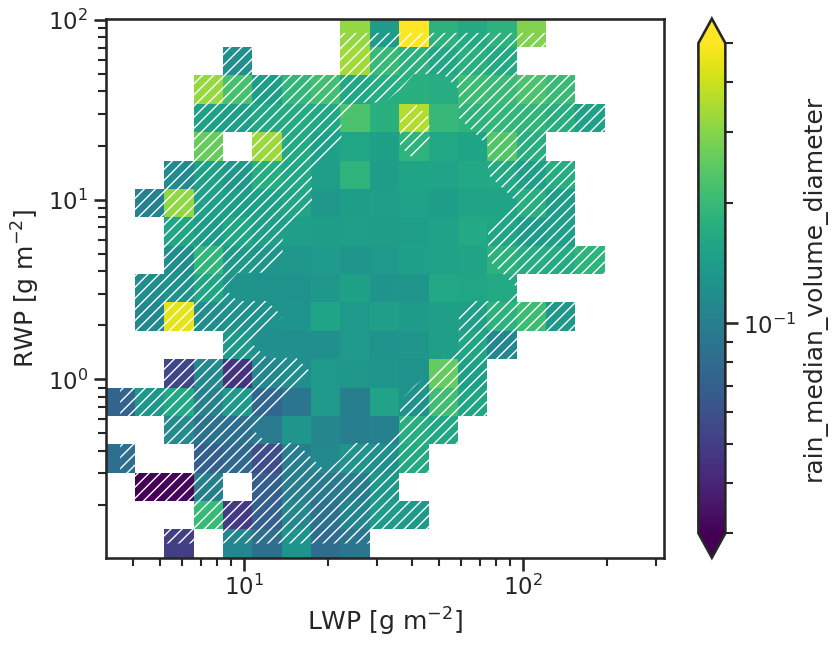

In [35]:
from matplotlib.colors import LogNorm

x = 'lwp'
y = 'rwp'
z = 'rain_median_volume_diameter'
for cat in [1,2]:
	tmp = dffil[dffil.cats == cat][[x, y, z]]
	tmp = tmp[tmp[z] > 0]
	tmp = tmp.dropna()

	# Define bins for x and y (you can customize the bin edges)
	x_bins = pd.cut(tmp[x], bins=np.logspace(0.5,2.5,20))
	y_bins = pd.cut(tmp[y], bins=np.logspace(-1,2,20))

	# Add binned columns to the DataFrame
	tmp[x+'_bin'] = x_bins
	tmp[y+'_bin'] = y_bins
	# save the midpoint of each bin interval in the tmp DataFrame
	tmp[x+'_bin_mid'] = tmp[x+'_bin'].apply(lambda x: (x.mid))
	tmp[y+'_bin_mid'] = tmp[y+'_bin'].apply(lambda x: (x.mid))

	heatmap_data = tmp.groupby([x+'_bin_mid', y+'_bin_mid'])[z].mean().to_xarray()
	heatmap_data.T.plot(figsize=(9,7), xscale='log', yscale='log', norm =LogNorm(), vmin=3e-2, vmax=5e-1) 
	# set colorbar scale to log
	# Overlay pattern "/" to indicate regions with low counts (<10)
	heatmap_data_counts = tmp.groupby([x+'_bin_mid', y+'_bin_mid'])[z].count().to_xarray()
	mask = (heatmap_data_counts.T < 10)
	plt.contourf(
		mask.coords['lwp_bin_mid'],
		mask.coords['rwp_bin_mid'],
		mask.values,  # invert mask: True where you want hatching
		levels=[0.5, 1],
		hatches=['///'],
		colors='none'
	)

	ax = plt.gca()
	ax.set_ylabel('RWP [g m$^{-2}$]')
	ax.set_xlabel('LWP [g m$^{-2}$]')
	plt.show()

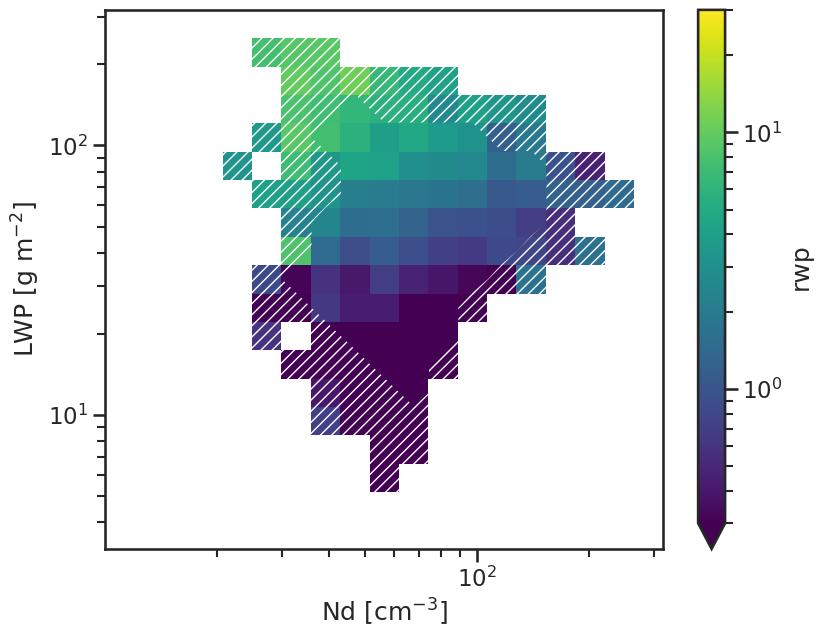

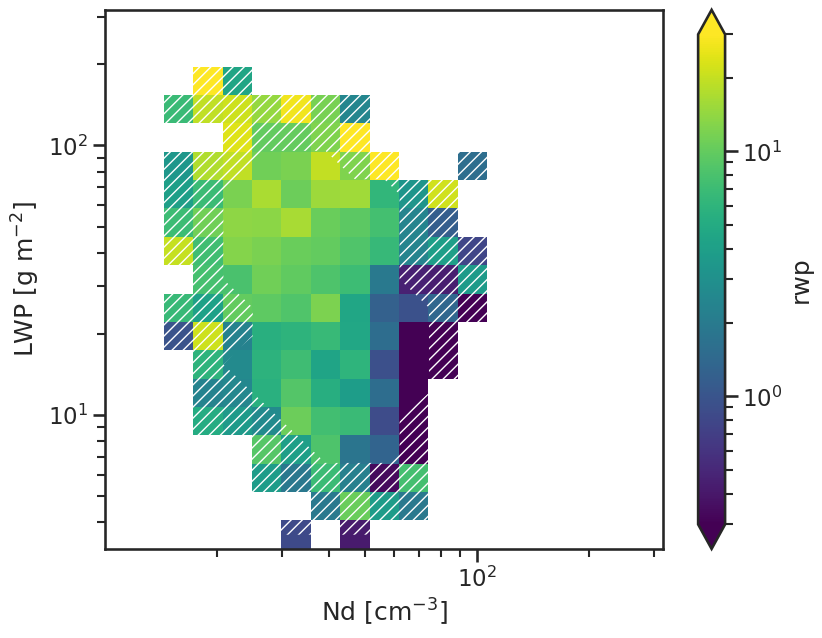

In [40]:
from matplotlib.colors import LogNorm

x = 'Nd'
y = 'lwp'
z = 'rwp'
for cat in [1,2]:
	tmp = dffil[dffil.cats == cat][[x, y, z]]
	tmp = tmp[tmp[z] > 0]
	tmp = tmp.dropna()

	# Define bins for x and y (you can customize the bin edges)
	y_bins = pd.cut(tmp[y], bins=np.logspace(0.5,2.5,20))
	x_bins = pd.cut(tmp[x], bins=np.logspace(1,2.5,20))

	# Add binned columns to the DataFrame
	tmp[x+'_bin'] = x_bins
	tmp[y+'_bin'] = y_bins
	# save the midpoint of each bin interval in the tmp DataFrame
	tmp[x+'_bin_mid'] = tmp[x+'_bin'].apply(lambda x: (x.mid))
	tmp[y+'_bin_mid'] = tmp[y+'_bin'].apply(lambda x: (x.mid))

	heatmap_data = tmp.groupby([x+'_bin_mid', y+'_bin_mid'])[z].mean().to_xarray()
	heatmap_data.T.plot(figsize=(9,7), xscale='log', yscale='log', norm =LogNorm(), vmin=3e-1, vmax=3e1) 
	# set colorbar scale to log
	# Overlay pattern "/" to indicate regions with low counts (<10)
	heatmap_data_counts = tmp.groupby([x+'_bin_mid', y+'_bin_mid'])[z].count().to_xarray()
	mask = (heatmap_data_counts.T < 10)
	plt.contourf(
		mask.coords['Nd_bin_mid'],
		mask.coords['lwp_bin_mid'],
		mask.values,  # invert mask: True where you want hatching
		levels=[0.5, 1],
		hatches=['///'],
		colors='none'
	)

	ax = plt.gca()
	ax.set_ylabel('LWP [g m$^{-2}$]')
	ax.set_xlabel('Nd [cm$^{-3}$]')
	plt.show()

## archetypical profiles

In [36]:
profile_vars = ['cbh_m', 'cth_m', 'N_cloudy_pixels', 'cloud_cover',
                'lwp_fil', 'rwp'] # 'rain_occurrence', 

In [37]:
cat = 2
dfcat = dffil[dffil.cats == cat]

In [38]:
# find scenes that fall within the 40-60% quantile for all profile_vars
dfcat_sel = dfcat[['orbit', 'scene_id'] + profile_vars].copy()
dfcat_sel = dfcat_sel.groupby(['orbit', 'scene_id']).mean().reset_index()
quantiles = dfcat_sel[profile_vars].quantile([0.2,0.25, 0.5, 0.75])

In [39]:
quantiles

,cbh_m,cth_m,N_cloudy_pixels,cloud_cover,lwp_fil,rwp
0.20,613.794690,971.759204,3.862869,0.489075,15.684651,0.295239
0.25,637.695602,1012.138336,4.088173,0.509155,17.506990,0.583084
0.50,754.869934,1183.647583,4.979670,0.600555,27.871853,3.040493
0.75,918.742752,1369.337067,5.718344,0.698593,43.050149,7.895551


In [40]:
print(f'Initial number of scenes in cat {cat}: {len(dfcat_sel)}')
for var in profile_vars:
    #dfcat_sel = dfcat_sel[(dfcat_sel[var] >= quantiles[var][0.25]) & (dfcat_sel[var] <= quantiles[var][0.75])]
    dfcat_sel = dfcat_sel[(dfcat_sel[var] >= quantiles[var][0.25]) & (dfcat_sel[var] <= quantiles[var][0.75])]
    print(f'After applying {var} quantile filter, number of scenes in cat {cat}: {len(dfcat_sel)}')

    # distance to 0.5 quantile as a measure of how close the scene is to the median
    dfcat_sel['dist_' + var] = np.abs(dfcat_sel[var] - quantiles[var][0.5]) / (quantiles[var][0.75] - quantiles[var][0.25])

print(f'Final number of scenes in cat {cat}: {len(dfcat_sel)}')

Initial number of scenes in cat 2: 2452
After applying cbh_m quantile filter, number of scenes in cat 2: 1226
After applying cth_m quantile filter, number of scenes in cat 2: 912
After applying N_cloudy_pixels quantile filter, number of scenes in cat 2: 585
After applying cloud_cover quantile filter, number of scenes in cat 2: 292
After applying lwp_fil quantile filter, number of scenes in cat 2: 173
After applying rwp quantile filter, number of scenes in cat 2: 127
Final number of scenes in cat 2: 127


In [41]:
dfcat_sel['dist_mean'] = dfcat_sel[[f'dist_{v}' for v in profile_vars]].mean(axis=1)
dfcat_sel = dfcat_sel.sort_values('dist_mean')

dfcat_sel

,orbit,scene_id,cbh_m,cth_m,N_cloudy_pixels,cloud_cover,lwp_fil,rwp,dist_cbh_m,dist_cth_m,dist_N_cloudy_pixels,dist_cloud_cover,dist_lwp_fil,dist_rwp,dist_mean
541,03203E,29412,762.942566,1171.933105,4.712500,0.575256,28.420746,2.071728,0.028723,0.032795,0.163891,0.133548,0.021489,0.132481,0.085488
1911,06844E,36155,754.984863,1147.493042,4.802469,0.631653,27.081065,1.252431,0.000409,0.101217,0.108701,0.164156,0.030959,0.244523,0.108327
168,01538E,26778,753.102539,1193.513306,5.168224,0.610046,22.304842,1.274229,0.006289,0.027620,0.115666,0.050101,0.217945,0.241541,0.109860
2307,07727E,12081,785.758118,1179.654297,4.757576,0.589844,29.603174,0.825245,0.109904,0.011179,0.136240,0.056545,0.067780,0.302941,0.114098
170,01538E,26780,700.000610,1118.742065,5.011628,0.627747,26.145600,2.386183,0.195232,0.181707,0.019604,0.143536,0.067582,0.089479,0.116190
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
742,04152E,31124,880.308350,1333.744385,5.290698,0.544800,20.098636,7.454097,0.446325,0.420205,0.190795,0.294321,0.304317,0.603573,0.376589
2092,07202E,36783,859.352783,1327.037476,5.389610,0.543762,41.615017,6.147555,0.371763,0.401429,0.251471,0.299799,0.538037,0.424899,0.381233
969,05161D,20126,883.337830,1344.508057,5.446429,0.549255,38.589396,7.103316,0.457104,0.450339,0.286325,0.270801,0.419586,0.555602,0.406626
1363,06124E,8910,898.156311,1369.120605,5.412371,0.643066,18.604714,7.188580,0.509830,0.519243,0.265433,0.224406,0.362803,0.567262,0.408163


In [ ]:
def plot_ACMCAP_MCOP_for_scene_id(scene_id):
    sys.path.append('/home/jmayer/ACI_research/Code/mesoscale_structure/')
    import access_ec_on_maap as maap
    sys.path.append('./../../../ectools/')
    from ectools import colormaps

    dfscene = dffil[dffil.scene_id == scene_id]
    orbit = dfscene.orbit.values[0]
    time_mid = dfscene.time_mid.values[0]
    year = pd.to_datetime(time_mid).year
    month = pd.to_datetime(time_mid).month
    day = pd.to_datetime(time_mid).day
    lat_max = dfscene.lat_max.values[0]
    lat_min = dfscene.lat_min.values[0]
    region_idx = dfscene.stratus_region_index.values[0]
    region = stratus_region_names[region_idx]

    #filename = glob.glob(f'/home/jmayer/Object_Data/ACM_CAP_2B/{year}/{month:02d}/{day:02d}/*_{orbit}.h5')[0]
    #ACMCAP = ecio.load_ACMCAP(filename)
    #encoding = ACMCAP.encoding
    print('Loading ACM-CAP data via MAAP...')
    ACMCAP_list = maap.get_acmcap_via_maap(
                        region=region, 
                        frame=orbit[-1],
                        orbitNumber=orbit[:-1],
                        max_items=1,
                        )
    ACMCAP = ACMCAP_list[0][0]
    encoding = ACMCAP.encoding
    ACMCAP = ACMCAP.where((ACMCAP.latitude > lat_min) & (ACMCAP.latitude < lat_max), drop=True)
    ACMCAP.encoding = encoding.copy()
    ACMCAP = ACMCAP.assign_coords(height_coord=("JSG_height", ACMCAP.height.isel(along_track=0).data))
    ACMCAP = ACMCAP.swap_dims({'JSG_height': 'height_coord'})

    # load MCOP
    MCOP_list = maap.get_mcop_via_maap(
            region=region, 
            frame=orbit[-1],
            orbitNumber=orbit[:-1],
            mcop_variables=['time', 'latitude', 'longitude', 'cloud_optical_thickness', 'cloud_water_path','cloud_effective_radius'], 
            max_items=1)
        
    MCOP, _ = MCOP_list[0]

    MCOP = MCOP.assign_coords(
        {
        'along_track': (
            ["along_track"],
            MCOP['along_track'].data,
            MCOP['along_track'].attrs
            ),
        'across_track': (
            ['across_track'],
            MCOP['across_track'].data,
            MCOP['across_track'].attrs
            )
        })
    along_track_min = np.abs(MCOP.sel(across_track=284).latitude - lat_min).argmin()
    along_track_max = np.abs(MCOP.sel(across_track=284).latitude - lat_max).argmin()
    MCOP2 = MCOP.sel(along_track=slice(MCOP.along_track[along_track_max], MCOP.along_track[along_track_min]))
    MCOP2 = MCOP2.sel(across_track=slice(360 - 256, 360))

    # load C-FMR
    CFMR_list = maap.get_cfmr_via_maap(
                        frame=orbit[-1],
                        orbitNumber=orbit[:-1],
                        max_items=1,
                        )
    CFMR = CFMR_list[0][0]
    CFMR = CFMR.where((CFMR.latitude > lat_min) & (CFMR.latitude < lat_max), drop=True)
    CFMR = CFMR.assign_coords(height_coord=("CPR_height", CFMR.height.isel(along_track=0).data))
    CFMR = CFMR.swap_dims({'CPR_height': 'height_coord'})
    CFMR = CFMR.where(CFMR.height_coord > -500, drop=True)

    # load CCD
    #CCD_list = maap.get_ccd_via_maap(
    #                frame=orbit[-1],
    #                orbitNumber=orbit[:-1],
    #                max_items=1,
    #                )
    #CCD = CCD_list[0][0]
    #CCD = CCD.where((CCD.latitude > lat_min) & (CCD.latitude < lat_max), drop=True)
    #CCD = CCD.assign_coords(height_coord=("CPR_height", CCD.height.isel(along_track=0).data))
    #CCD = CCD.swap_dims({'CPR_height': 'height_coord'})
    #CCD = CCD.where(CCD.height_coord > -500, drop=True)

    # plot
    sns.set_context('talk')
    fig, axs = plt.subplots(2,1, figsize=(9,8.5), gridspec_kw={'height_ratios': [1, 3]})
    #ACMCAP.rain_water_content.T.plot(ax=axs[0], ylim=(0,3000), vmin=1e-7, vmax=1e-4, norm=LogNorm(), cmap='Blues', add_colorbar=False)
    (ACMCAP.liquid_water_content*1e3).T.plot(ax=axs[0], ylim=(0,3000), vmin=1e-3, vmax=1e0, norm=LogNorm(), cmap='turbo', cbar_kwargs={'label': 'LWC (g m$^{-3}$)'})
    #dffil[dffil.scene_id == dfcat_sel.scene_id.values[0]].lcl.plot(ax=axs[0])
    mean_LWP = (ACMCAP.liquid_water_content.where(ACMCAP.liquid_water_content > 0).sum(dim='height_coord')*100).mean().values * 1e3
    axs[0].annotate(fr'{mean_LWP:.1f}g/m$^{2}$', xy=(0.8,0.85), xycoords='axes fraction', fontsize=15)
    axs[0].set_title(f'{orbit}, lat:{lat_min.round(2)}-{lat_max.round(2)}')
    ax = axs[1]
    (MCOP2.cloud_water_path * 1e3).T.plot(ax=ax, cmap='viridis', vmin=1e1, vmax=1e3, norm=LogNorm(), add_colorbar=True, cbar_kwargs={'label': 'LWP (g m$^{-2}$)'})
    ax.axhline(284, color='k', linestyle='--', lw=2)
    mean_LWP = (MCOP2.cloud_water_path.where((MCOP2.cloud_water_path > 0) & (~np.isinf(MCOP2.cloud_water_path))).mean().values * 1e3)
    ax.annotate(fr'{mean_LWP:.1f}g/m$^{2}$', xy=(0.8,0.9), xycoords='axes fraction', fontsize=15)
    ax.set_title('MCOP liquid water path')
    for ax in axs:
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_xlabel('')
        ax.set_ylabel('')
    fig.tight_layout()
    plt.show()

    sns.set_context('talk')
    fig, axs = plt.subplots(2,1, figsize=(9,8.5), gridspec_kw={'height_ratios': [1, 3]})
    (ACMCAP.liquid_effective_radius * 1e6).T.plot(ax=axs[0], ylim=(0,3000), vmin=5, vmax=20, cmap='turbo', cbar_kwargs={'label': 'ER ($\mu$m)'})
    #dffil[dffil.scene_id == dfcat_sel.scene_id.values[0]].lcl.plot(ax=axs[0])
    mean_ER = (ACMCAP.liquid_effective_radius.where(ACMCAP.liquid_water_content > 0).mean(dim='height_coord')).mean().values * 1e6
    axs[0].annotate(f'{mean_ER:.1f}$\mu$m', xy=(0.8,0.85), xycoords='axes fraction', fontsize=15)
    axs[0].set_title(f'{orbit}, lat:{lat_min.round(2)}-{lat_max.round(2)}')
    ax = axs[1]
    (MCOP2.cloud_effective_radius * 1e6).T.plot(ax=ax, cmap='viridis', vmin=5, vmax=20, add_colorbar=True, cbar_kwargs={'label': 'ER ($\mu$m)'})
    ax.axhline(284, color='k', linestyle='--', lw=2)
    mean_ER = MCOP2.cloud_effective_radius.where(MCOP2.cloud_water_path > 0).mean().values * 1e6
    ax.annotate(f'{mean_ER:.1f}$\mu$m', xy=(0.8,0.9), xycoords='axes fraction', fontsize=15)
    ax.set_title('MCOP effective radius')
    for ax in axs:
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_xlabel('')
        ax.set_ylabel('')
    fig.tight_layout()
    plt.show()

    sns.set_context('talk')
    fig, axs = plt.subplots(5,1, figsize=(9,11), gridspec_kw={'height_ratios': [1, 1, 1, 1, 1]})
    (ACMCAP.liquid_number_concentration.where(ACMCAP.liquid_number_concentration > 0) * 1e-6).T.plot(ax=axs[0], ylim=(0,3000), vmin=1e1, vmax=2e2, norm=LogNorm(), cmap='turbo', cbar_kwargs={'label': 'N$_d$ (cm$^{-3}$)'})
    mean_Nd = (ACMCAP.liquid_number_concentration.where(ACMCAP.liquid_number_concentration > 0).mean(dim='height_coord')).mean().values * 1e-6
    axs[0].annotate(f'{mean_Nd:.1f}cm$^{{-3}}$', xy=(0.8,0.85), xycoords='axes fraction', fontsize=15)
    axs[0].set_title(f'{orbit}, lat:{lat_min.round(2)}-{lat_max.round(2)}')
    (ACMCAP.rain_water_content*1e3).T.plot(ax=axs[1], ylim=(0,3000), vmin=1e-4, vmax=1e-1, norm=LogNorm(), cmap='turbo', cbar_kwargs={'label': 'RWC (g m$^{-3}$)'})
    mean_RWP = (ACMCAP.rain_water_content.where(ACMCAP.rain_water_content > 0).sum(dim='height_coord')*100).mean().values * 1e3
    axs[1].annotate(fr'{mean_RWP:.1f}g/m$^{2}$', xy=(0.8,0.85), xycoords='axes fraction', fontsize=15)
    (ACMCAP.rain_median_volume_diameter*1e6).T.plot(ax=axs[2], ylim=(0,3000), vmin=1e1, vmax=1e4, norm=LogNorm(), cmap='turbo', cbar_kwargs={'label': '$D_0$ ($\mu$m)'})
    mean_RVD = (ACMCAP.rain_median_volume_diameter.where(ACMCAP.rain_water_content > 0).mean(dim='height_coord')).mean().values * 1e6
    axs[2].annotate(fr'{mean_RVD:.1f}$\mu$m', xy=(0.8,0.85), xycoords='axes fraction', fontsize=15)
    (ACMCAP.rain_normalized_number_concentration*1e-6).T.plot(ax=axs[4], ylim=(0,3000), vmin=1e2, vmax=1e5, norm=LogNorm(), cmap='turbo', cbar_kwargs={'label': 'N$_{R}$ (m$^{-3}$)'})
    mean_RNC = (ACMCAP.rain_normalized_number_concentration.where(ACMCAP.rain_water_content > 0).mean(dim='height_coord')).mean().values * 1e-6
    axs[4].annotate(fr'{mean_RNC:.1f}cm$^{{-3}}$', xy=(0.8,0.85), xycoords='axes fraction', fontsize=15)
    #ACMCAP.CPR_reflectivity_factor.T.plot(ax=axs[4], ylim=(0,3000), vmin=-40, vmax=0, cmap='turbo', cbar_kwargs={'label': 'Refl. (dBZ)'})
    CFMR.reflectivity_no_attenuation_correction.T.plot(ax=axs[3], cmap=colormaps.chiljet2, vmin=-30, vmax=0, ylim=(0,3000), cbar_kwargs={'label': 'Refl. (dBZ)'})
    #(CCD['doppler_velocity_best_estimate'] - CCD['sedimentation_velocity_best_estimate']).T.plot(ax=axs[4], cmap='RdBu', vmin=-2, vmax=2, ylim=(0,3000), cbar_kwargs={'label': 'w (m/s)'})
    for ax in axs:
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_xlabel('')
        ax.set_ylabel('')
    fig.tight_layout()
    plt.show()


07326E
Loading ACM-CAP data via MAAP...
Accessing 1 items (limited by max_items).
1 items found that matched the query.
Found .h5 file in enclosure_h5: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/ACM_CAP_2B/BA/2025/09/11/ECA_EXBA_ACM_CAP_2B_20250911T191711Z_20250911T210913Z_07326E/ECA_EXBA_ACM_CAP_2B_20250911T191711Z_20250911T210913Z_07326E/ECA_EXBA_ACM_CAP_2B_20250911T191711Z_20250911T210913Z_07326E.h5
HDF5 URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/ACM_CAP_2B/BA/2025/09/11/ECA_EXBA_ACM_CAP_2B_20250911T191711Z_20250911T210913Z_07326E/ECA_EXBA_ACM_CAP_2B_20250911T191711Z_20250911T210913Z_07326E/ECA_EXBA_ACM_CAP_2B_20250911T191711Z_20250911T210913Z_07326E.h5
Orbit: 07326E
Fetching ESA MAAP token...
p1eL7uonXs6MDxtGbgKdPVRAmnGxHpVE
Dataset URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/ACM_CAP_2B/BA/2025/09/11/ECA_EXBA_ACM_CAP_2B_20250911T191711Z_20250911T210913Z_07326E/ECA_EXBA_ACM_CAP_2B_20250911T191711Z_20250911T21

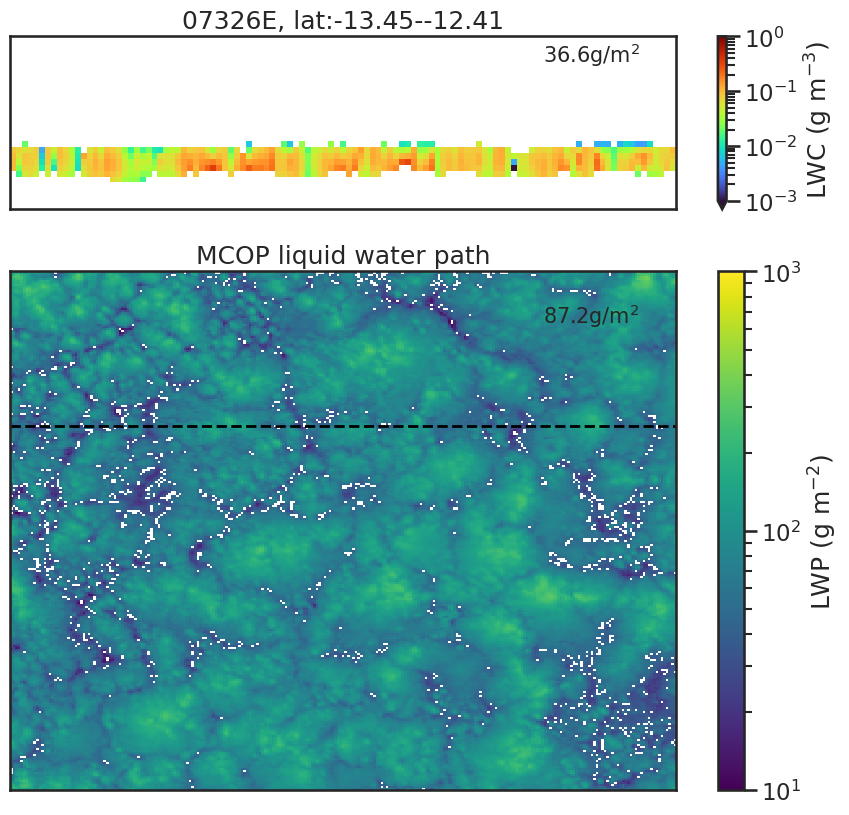

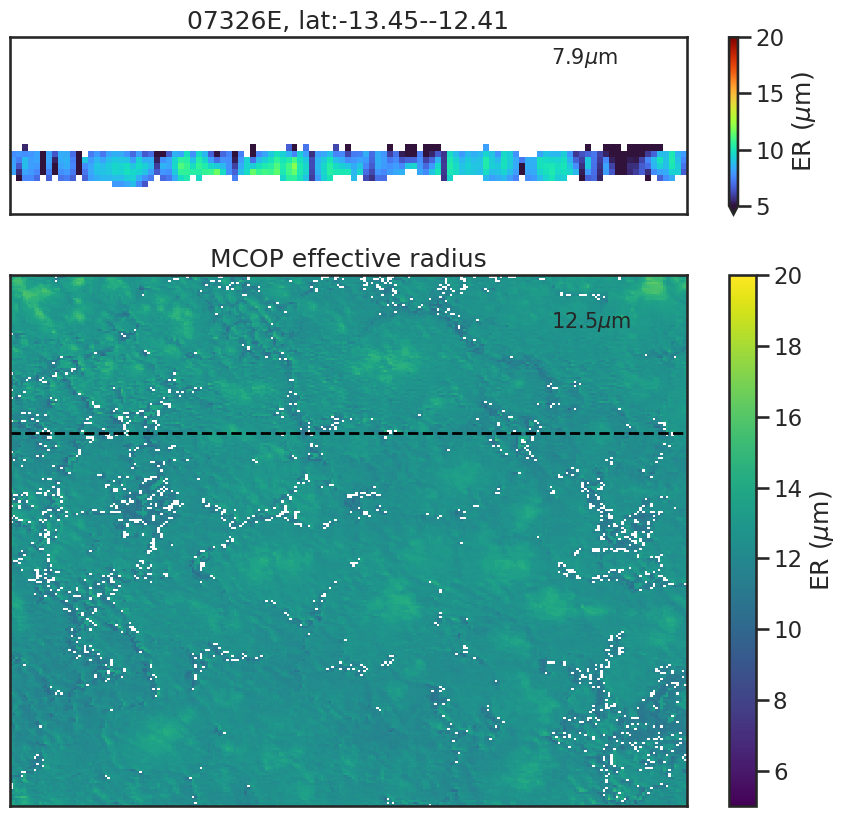

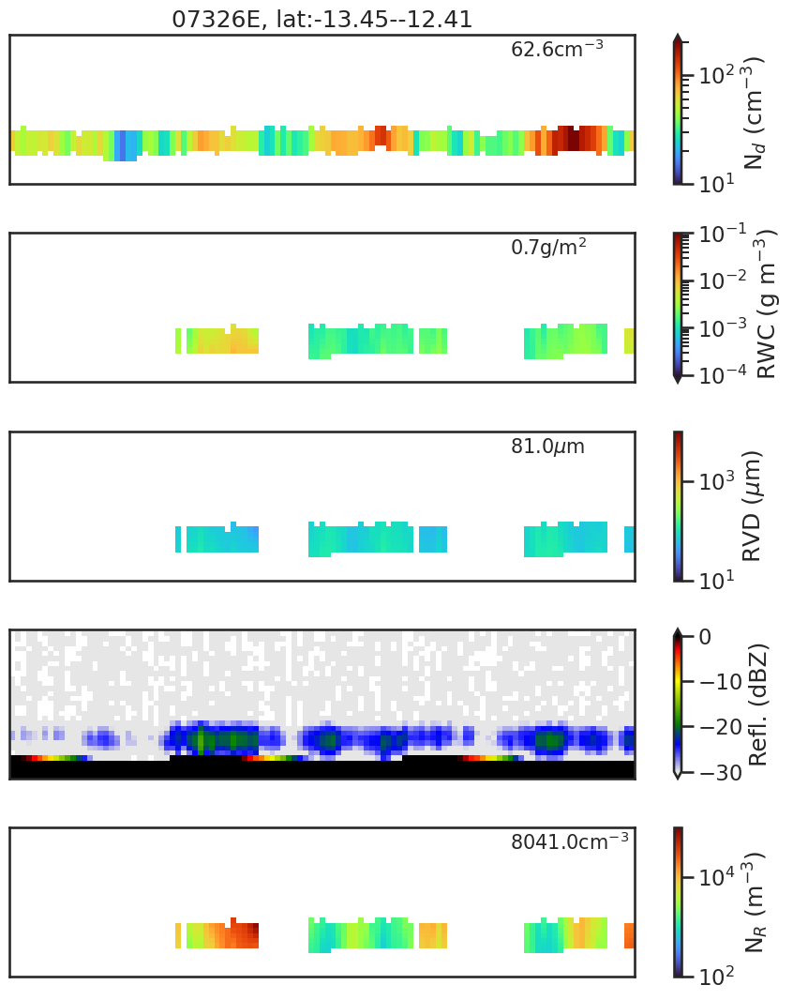

05881D
Loading ACM-CAP data via MAAP...
Accessing 1 items (limited by max_items).
1 items found that matched the query.
Found .h5 file in enclosure_h5: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/ACM_CAP_2B/BA/2025/06/10/ECA_EXBA_ACM_CAP_2B_20250610T221839Z_20250930T030111Z_05881D/ECA_EXBA_ACM_CAP_2B_20250610T221839Z_20250930T030111Z_05881D/ECA_EXBA_ACM_CAP_2B_20250610T221839Z_20250930T030111Z_05881D.h5
HDF5 URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/ACM_CAP_2B/BA/2025/06/10/ECA_EXBA_ACM_CAP_2B_20250610T221839Z_20250930T030111Z_05881D/ECA_EXBA_ACM_CAP_2B_20250610T221839Z_20250930T030111Z_05881D/ECA_EXBA_ACM_CAP_2B_20250610T221839Z_20250930T030111Z_05881D.h5
Orbit: 05881D
Fetching ESA MAAP token...
p1eL7uonXs6MDxtGbgKdPVRAmnGxHpVE
Dataset URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/ACM_CAP_2B/BA/2025/06/10/ECA_EXBA_ACM_CAP_2B_20250610T221839Z_20250930T030111Z_05881D/ECA_EXBA_ACM_CAP_2B_20250610T221839Z_20250930T03

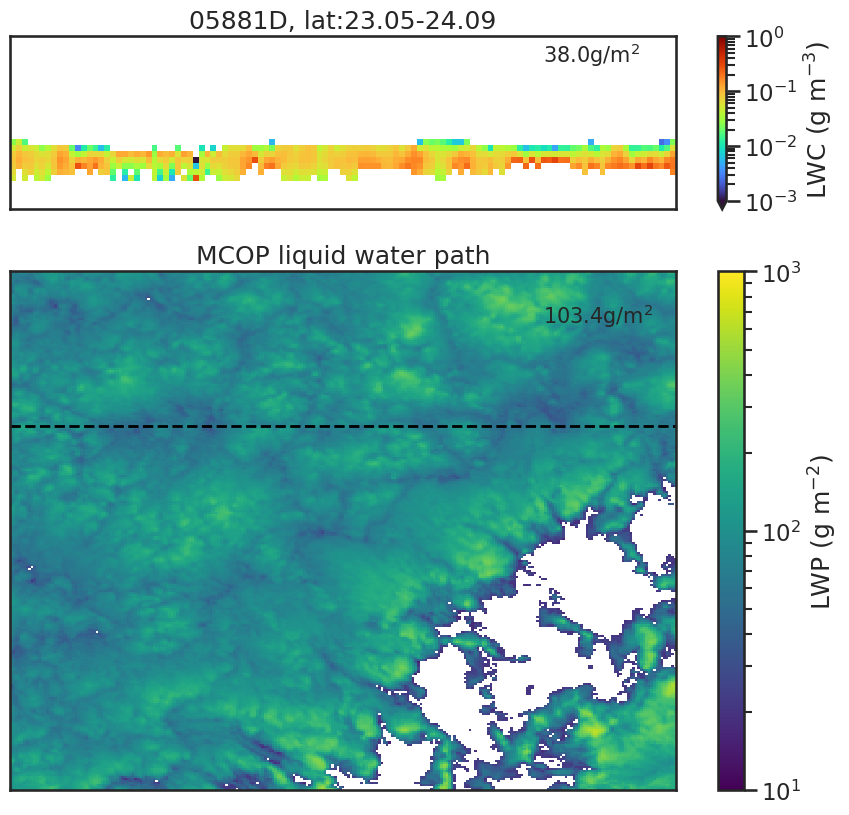

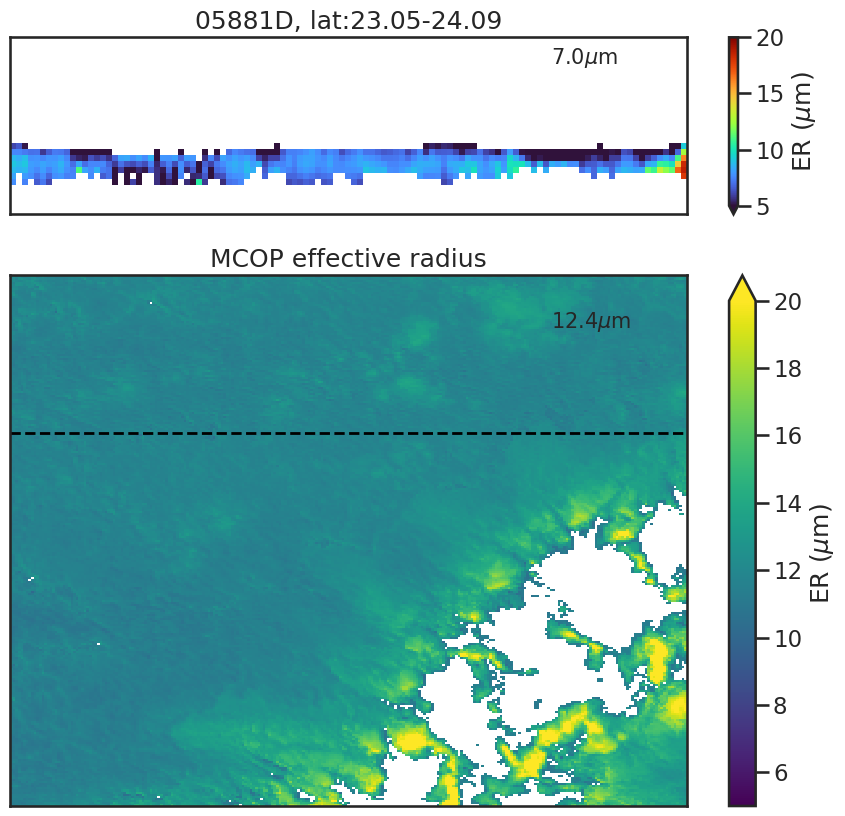

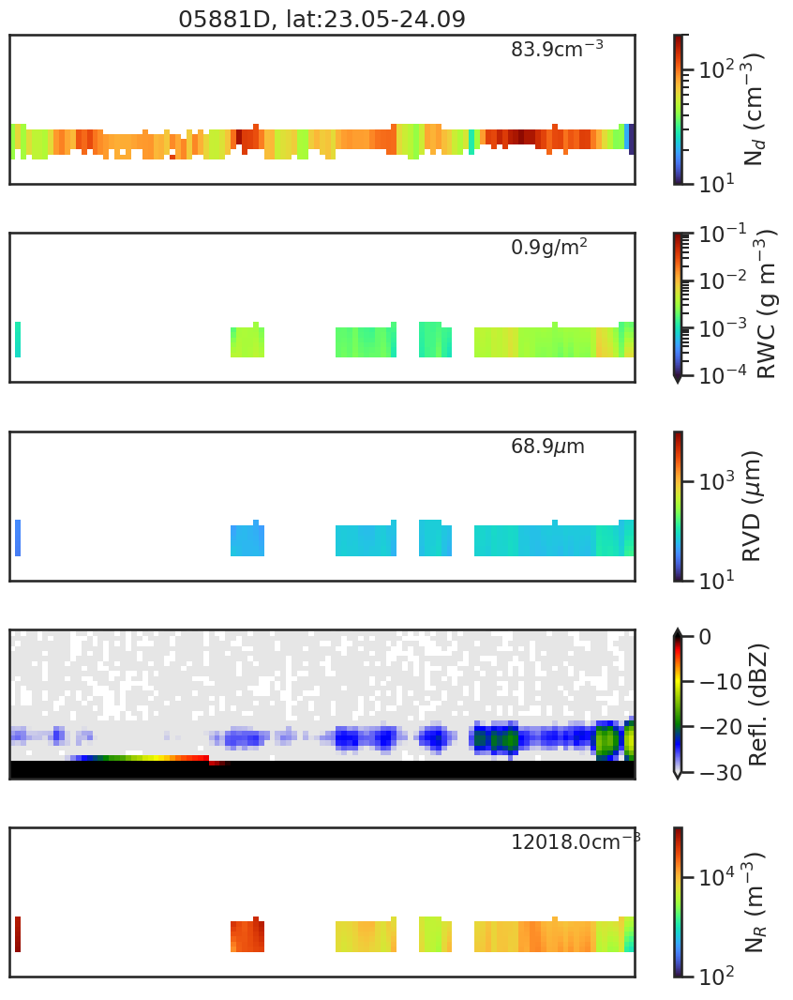

04683E
Loading ACM-CAP data via MAAP...
Accessing 1 items (limited by max_items).
1 items found that matched the query.
Found .h5 file in enclosure_h5: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/ACM_CAP_2B/BA/2025/03/25/ECA_EXBA_ACM_CAP_2B_20250325T224145Z_20250913T232258Z_04683E/ECA_EXBA_ACM_CAP_2B_20250325T224145Z_20250913T232258Z_04683E/ECA_EXBA_ACM_CAP_2B_20250325T224145Z_20250913T232258Z_04683E.h5
HDF5 URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/ACM_CAP_2B/BA/2025/03/25/ECA_EXBA_ACM_CAP_2B_20250325T224145Z_20250913T232258Z_04683E/ECA_EXBA_ACM_CAP_2B_20250325T224145Z_20250913T232258Z_04683E/ECA_EXBA_ACM_CAP_2B_20250325T224145Z_20250913T232258Z_04683E.h5
Orbit: 04683E
Fetching ESA MAAP token...
p1eL7uonXs6MDxtGbgKdPVRAmnGxHpVE
Dataset URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/ACM_CAP_2B/BA/2025/03/25/ECA_EXBA_ACM_CAP_2B_20250325T224145Z_20250913T232258Z_04683E/ECA_EXBA_ACM_CAP_2B_20250325T224145Z_20250913T23

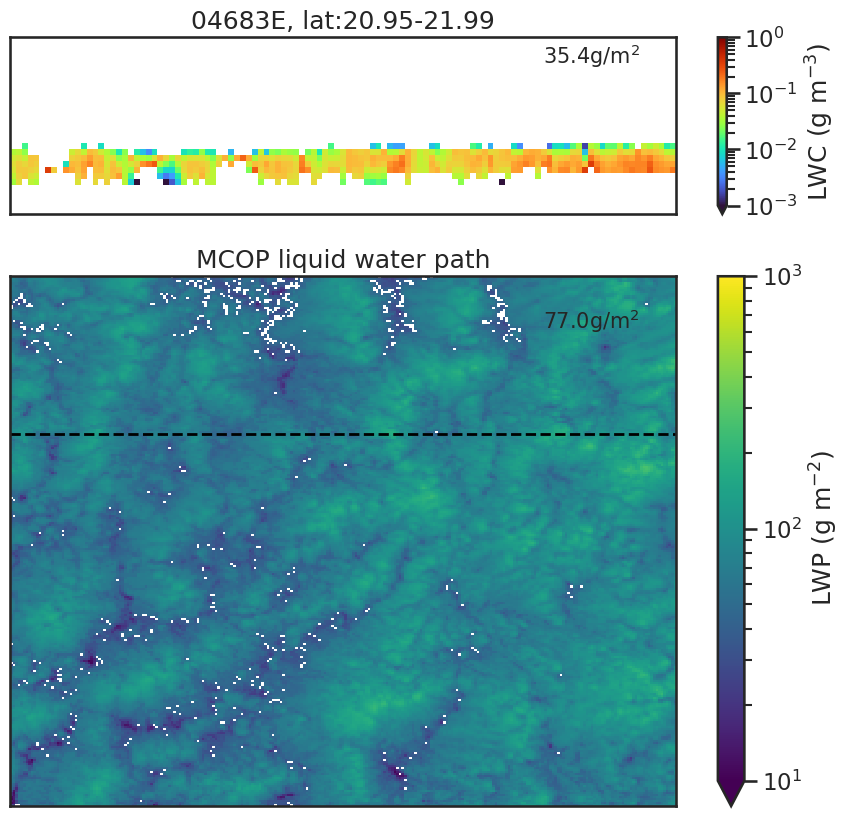

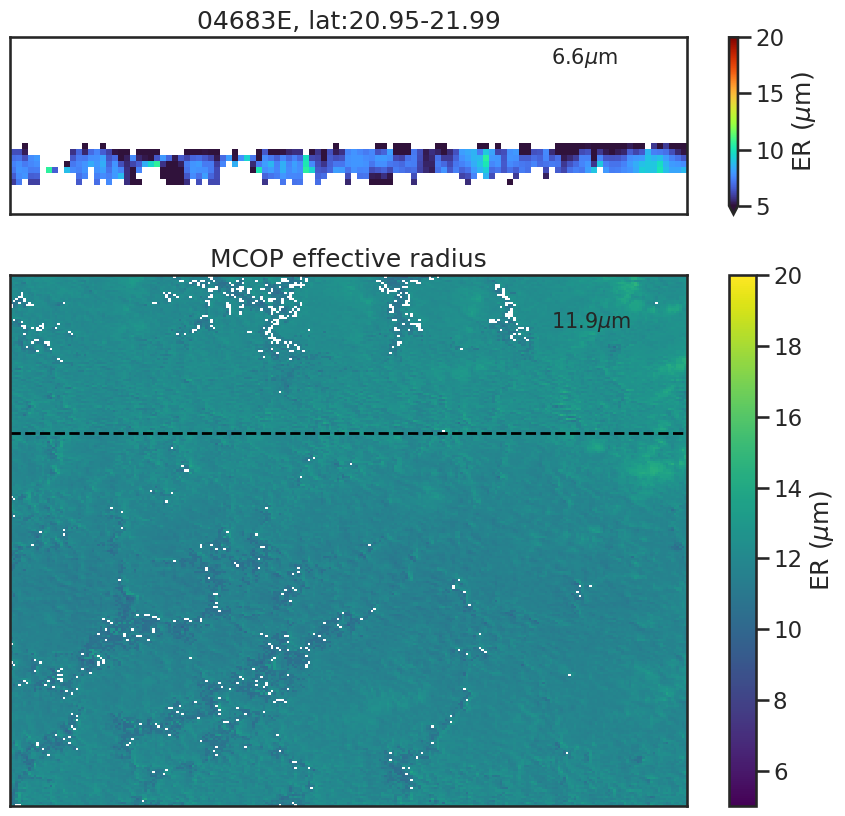

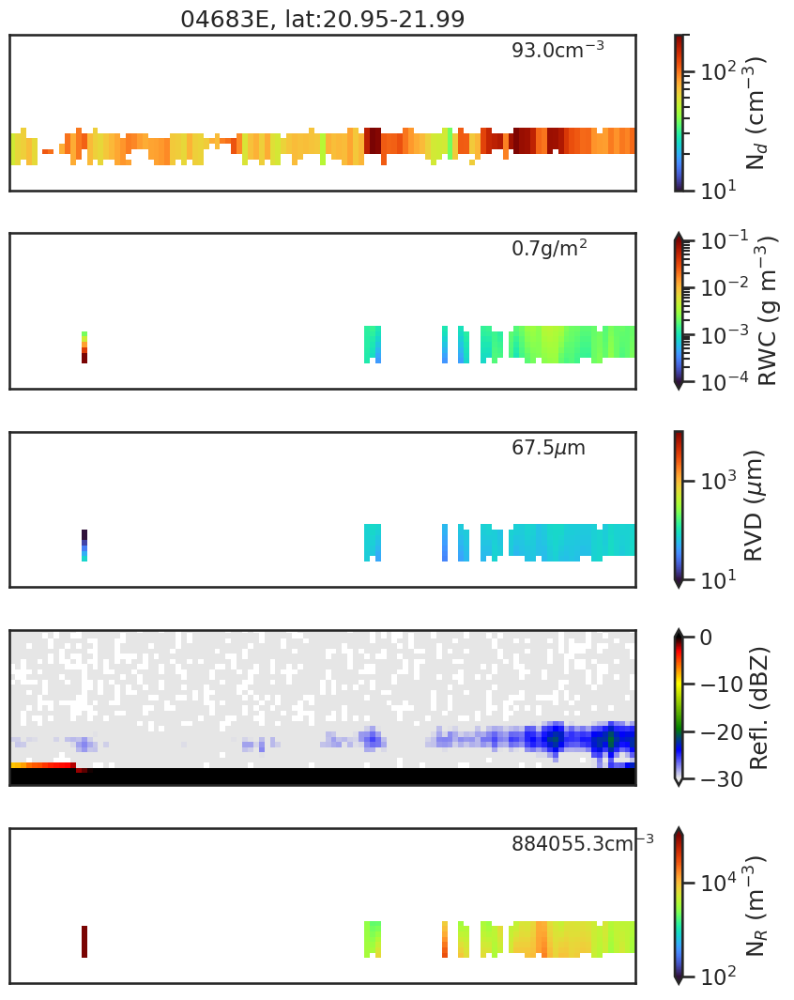

07326E
Loading ACM-CAP data via MAAP...
Accessing 1 items (limited by max_items).
1 items found that matched the query.
Found .h5 file in enclosure_h5: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/ACM_CAP_2B/BA/2025/09/11/ECA_EXBA_ACM_CAP_2B_20250911T191711Z_20250911T210913Z_07326E/ECA_EXBA_ACM_CAP_2B_20250911T191711Z_20250911T210913Z_07326E/ECA_EXBA_ACM_CAP_2B_20250911T191711Z_20250911T210913Z_07326E.h5
HDF5 URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/ACM_CAP_2B/BA/2025/09/11/ECA_EXBA_ACM_CAP_2B_20250911T191711Z_20250911T210913Z_07326E/ECA_EXBA_ACM_CAP_2B_20250911T191711Z_20250911T210913Z_07326E/ECA_EXBA_ACM_CAP_2B_20250911T191711Z_20250911T210913Z_07326E.h5
Orbit: 07326E
Fetching ESA MAAP token...
p1eL7uonXs6MDxtGbgKdPVRAmnGxHpVE
Dataset URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/ACM_CAP_2B/BA/2025/09/11/ECA_EXBA_ACM_CAP_2B_20250911T191711Z_20250911T210913Z_07326E/ECA_EXBA_ACM_CAP_2B_20250911T191711Z_20250911T21

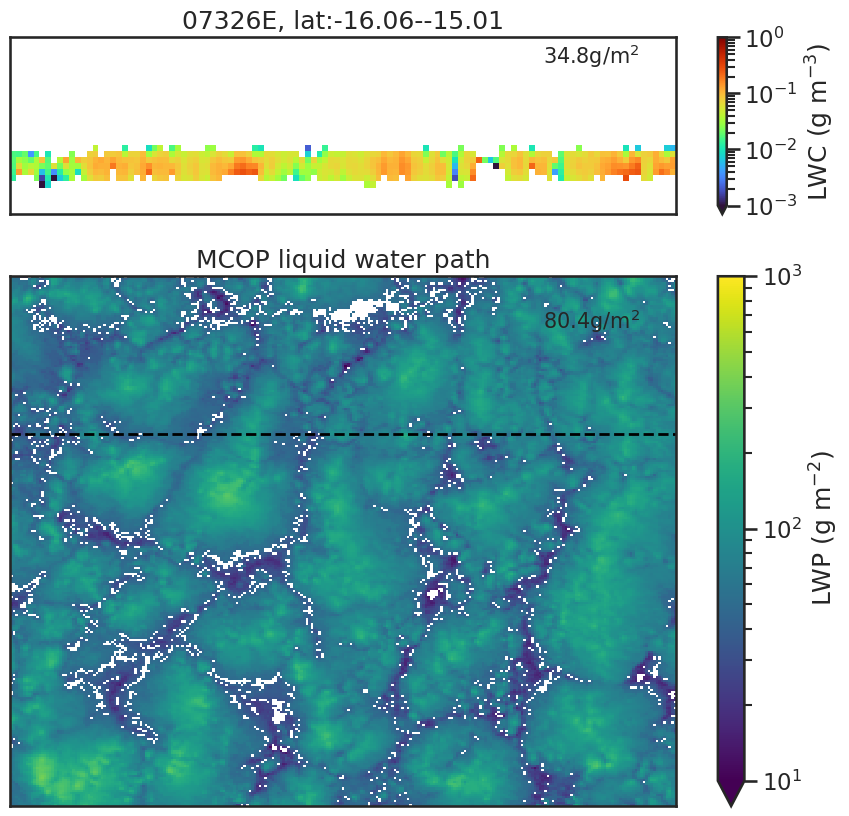

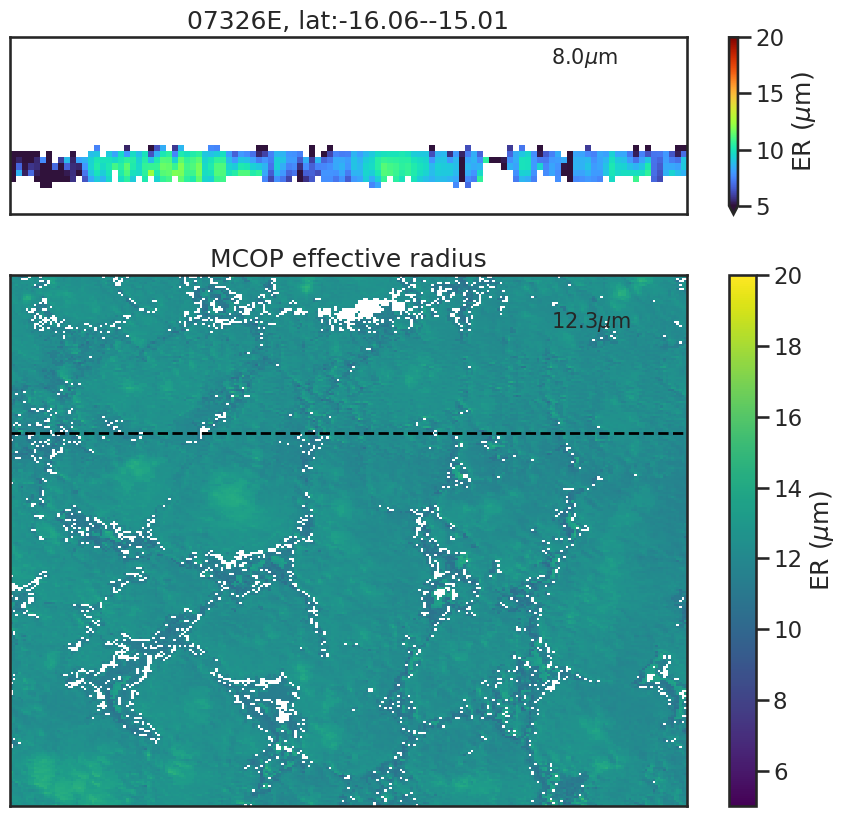

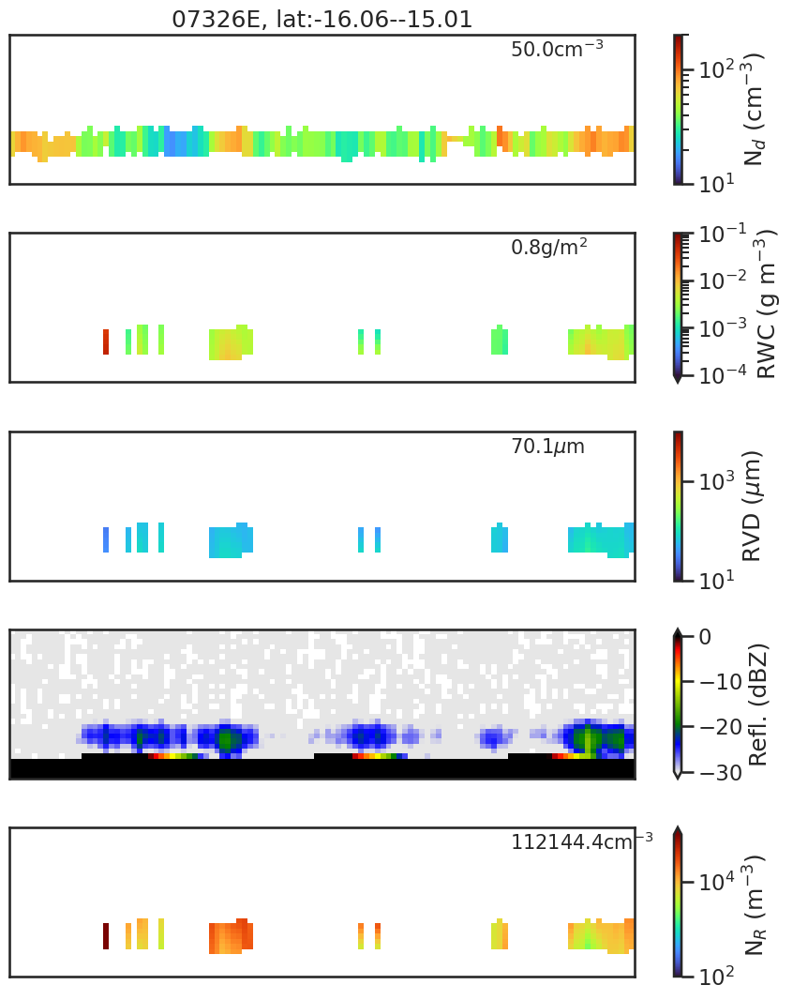

In [26]:
for si in dfcat_sel[dfcat_sel.rwp > 0.6].scene_id.unique()[0:4]:
    print(dffil[dffil.scene_id == si].orbit.values[0])
    
    profile_cat = xr.DataArray(np.zeros((113, 30)), dims=['along_track', 'height'], coords={'along_track': np.arange(113), 'height': np.arange(30)*100})
    #print(si)
    dfex = dffil[dffil.scene_id == si]
    if len(dfex) != 1:
        print(f'skipping scene {si} with {len(dfex)} points')
        continue
    if dfex.cert.iloc[0] < 0.75:
        print(f'skipping scene {si} with low cert {dfex.cert.iloc[0]}')
        continue
    try:
        plot_ACMCAP_MCOP_for_scene_id(si)
    except Exception as e:
        print(f'Error plotting scene {si}: {e}')
        print('-'*40)

05632E
Loading ACM-CAP data via MAAP...
Accessing 1 items (limited by max_items).
1 items found that matched the query.
Found .h5 file in enclosure_h5: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/ACM_CAP_2B/BA/2025/05/25/ECA_EXBA_ACM_CAP_2B_20250525T222652Z_20250918T033559Z_05632E/ECA_EXBA_ACM_CAP_2B_20250525T222652Z_20250918T033559Z_05632E/ECA_EXBA_ACM_CAP_2B_20250525T222652Z_20250918T033559Z_05632E.h5
HDF5 URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/ACM_CAP_2B/BA/2025/05/25/ECA_EXBA_ACM_CAP_2B_20250525T222652Z_20250918T033559Z_05632E/ECA_EXBA_ACM_CAP_2B_20250525T222652Z_20250918T033559Z_05632E/ECA_EXBA_ACM_CAP_2B_20250525T222652Z_20250918T033559Z_05632E.h5
Orbit: 05632E
Fetching ESA MAAP token...
p1eL7uonXs6MDxtGbgKdPVRAmnGxHpVE
Dataset URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/ACM_CAP_2B/BA/2025/05/25/ECA_EXBA_ACM_CAP_2B_20250525T222652Z_20250918T033559Z_05632E/ECA_EXBA_ACM_CAP_2B_20250525T222652Z_20250918T03

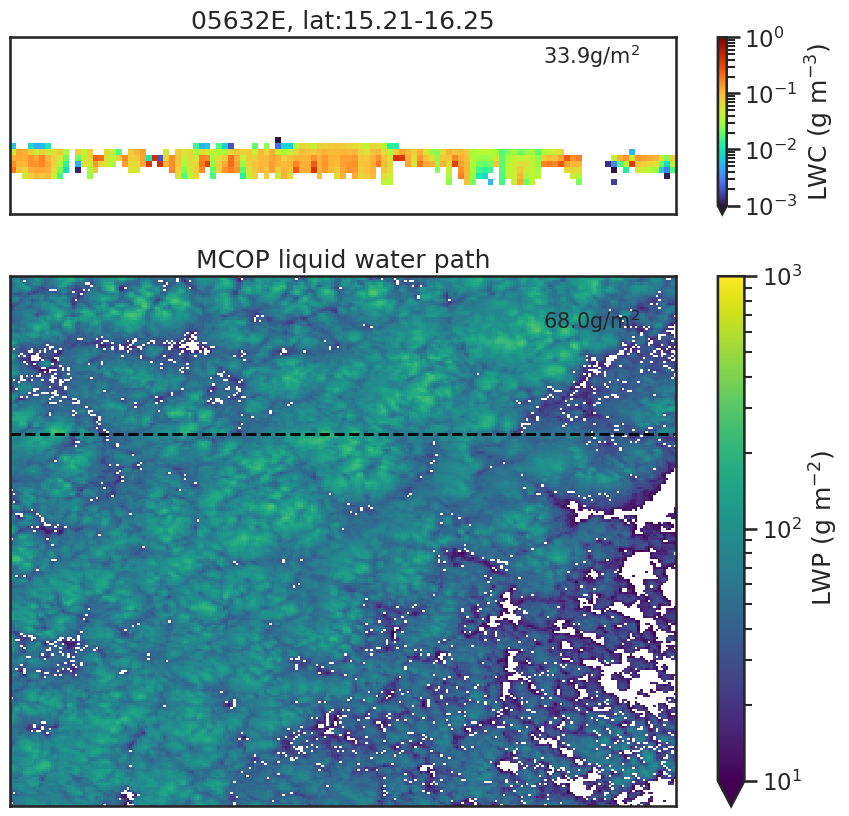

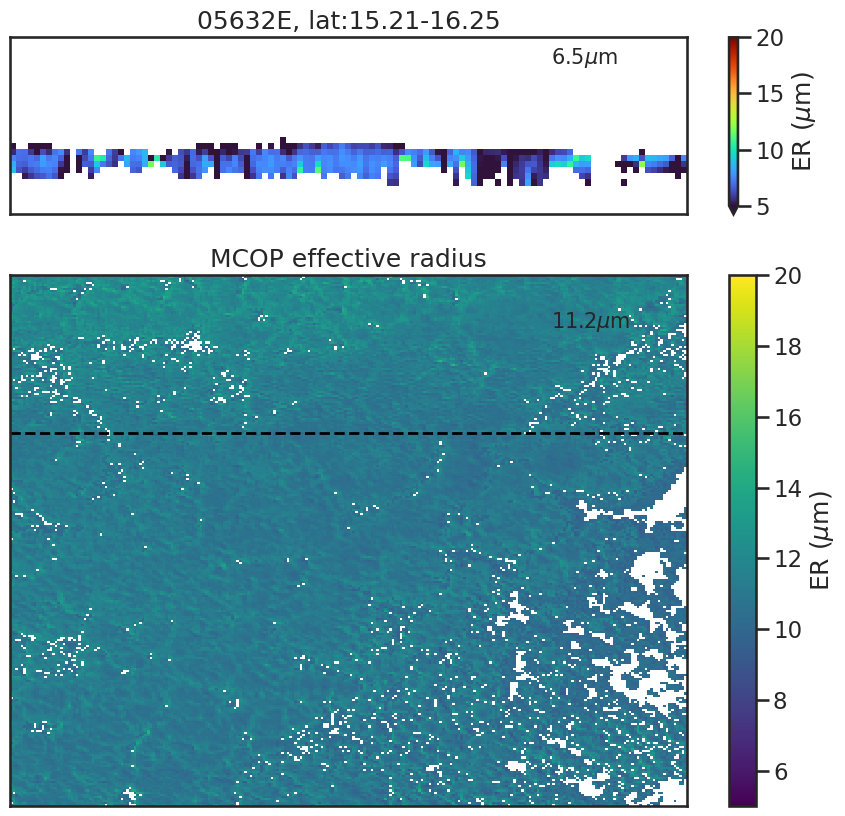

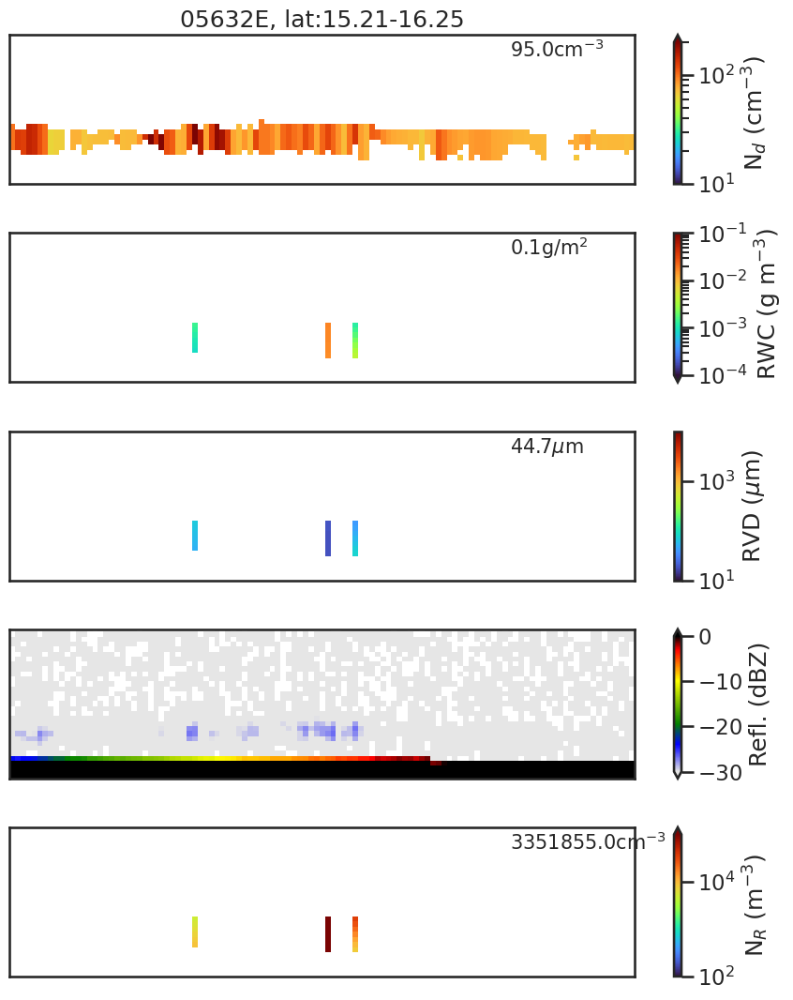

01036E
Loading ACM-CAP data via MAAP...
Accessing 1 items (limited by max_items).
1 items found that matched the query.
Found .h5 file in enclosure_h5: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/ACM_CAP_2B/BA/2024/08/03/ECA_EXBA_ACM_CAP_2B_20240803T131837Z_20250905T144107Z_01036E/ECA_EXBA_ACM_CAP_2B_20240803T131837Z_20250905T144107Z_01036E/ECA_EXBA_ACM_CAP_2B_20240803T131837Z_20250905T144107Z_01036E.h5
HDF5 URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/ACM_CAP_2B/BA/2024/08/03/ECA_EXBA_ACM_CAP_2B_20240803T131837Z_20250905T144107Z_01036E/ECA_EXBA_ACM_CAP_2B_20240803T131837Z_20250905T144107Z_01036E/ECA_EXBA_ACM_CAP_2B_20240803T131837Z_20250905T144107Z_01036E.h5
Orbit: 01036E
Fetching ESA MAAP token...
p1eL7uonXs6MDxtGbgKdPVRAmnGxHpVE
Dataset URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/ACM_CAP_2B/BA/2024/08/03/ECA_EXBA_ACM_CAP_2B_20240803T131837Z_20250905T144107Z_01036E/ECA_EXBA_ACM_CAP_2B_20240803T131837Z_20250905T14

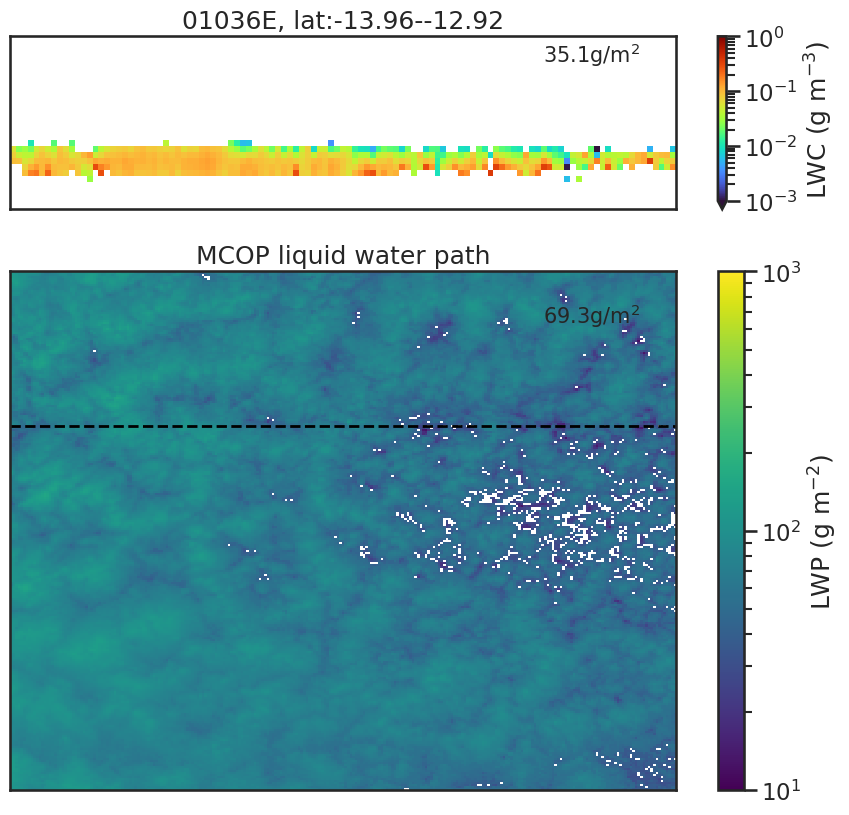

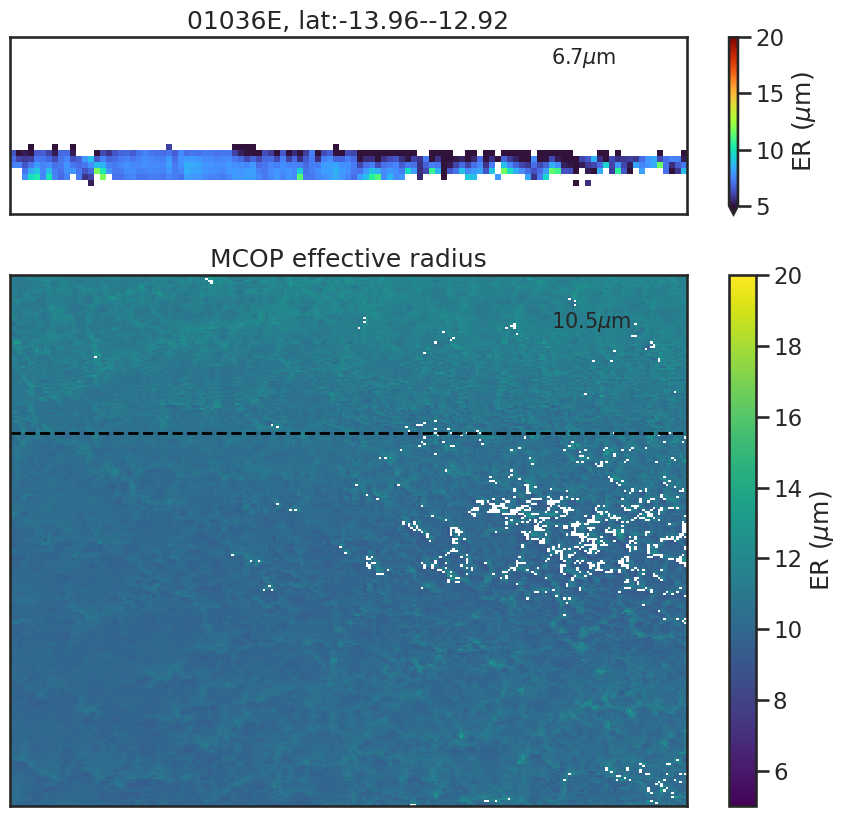

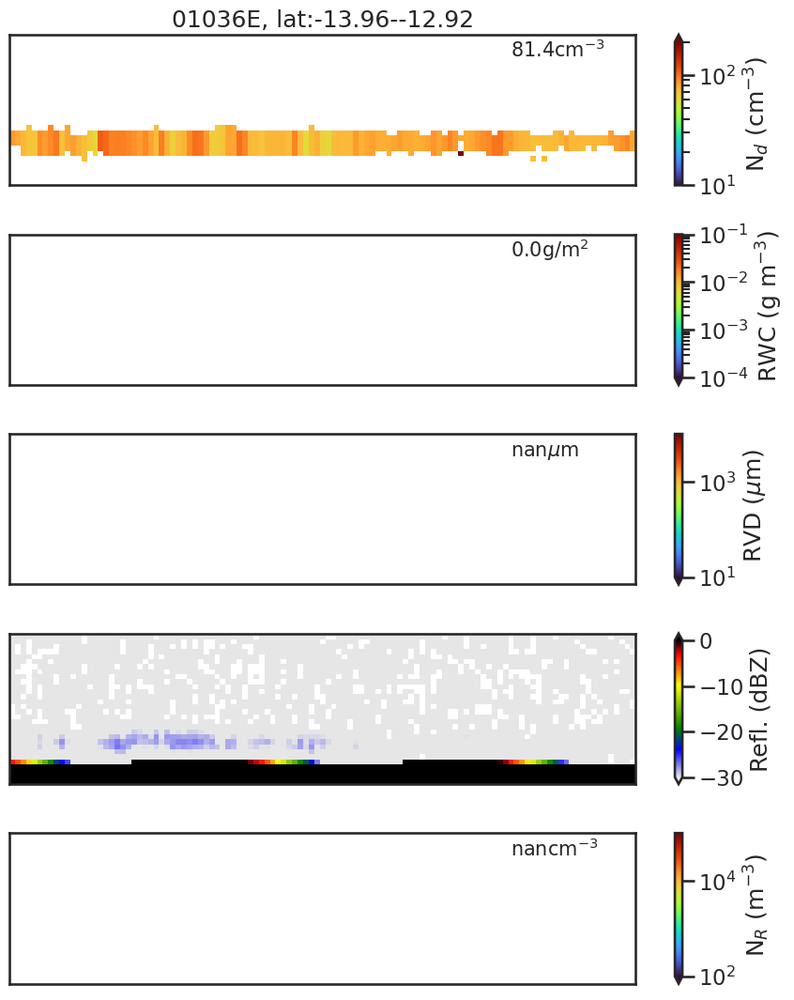

06015E
Loading ACM-CAP data via MAAP...
Accessing 1 items (limited by max_items).
1 items found that matched the query.
Found .h5 file in enclosure_h5: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/ACM_CAP_2B/BA/2025/06/19/ECA_EXBA_ACM_CAP_2B_20250619T131115Z_20250930T015605Z_06015E/ECA_EXBA_ACM_CAP_2B_20250619T131115Z_20250930T015605Z_06015E/ECA_EXBA_ACM_CAP_2B_20250619T131115Z_20250930T015605Z_06015E.h5
HDF5 URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/ACM_CAP_2B/BA/2025/06/19/ECA_EXBA_ACM_CAP_2B_20250619T131115Z_20250930T015605Z_06015E/ECA_EXBA_ACM_CAP_2B_20250619T131115Z_20250930T015605Z_06015E/ECA_EXBA_ACM_CAP_2B_20250619T131115Z_20250930T015605Z_06015E.h5
Orbit: 06015E
Fetching ESA MAAP token...
p1eL7uonXs6MDxtGbgKdPVRAmnGxHpVE
Dataset URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/ACM_CAP_2B/BA/2025/06/19/ECA_EXBA_ACM_CAP_2B_20250619T131115Z_20250930T015605Z_06015E/ECA_EXBA_ACM_CAP_2B_20250619T131115Z_20250930T01

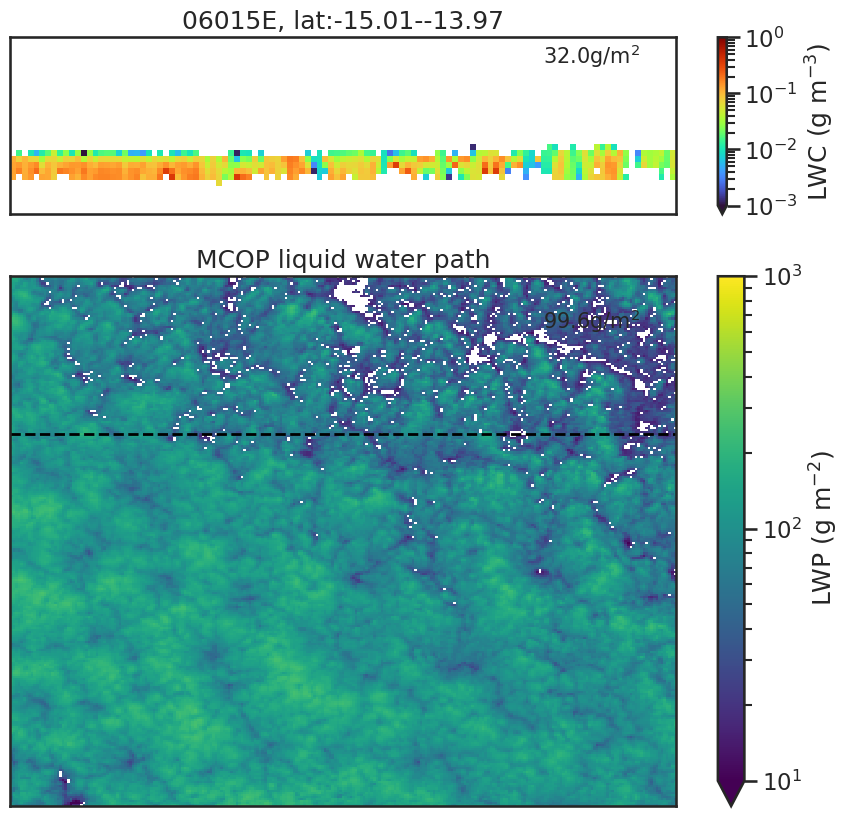

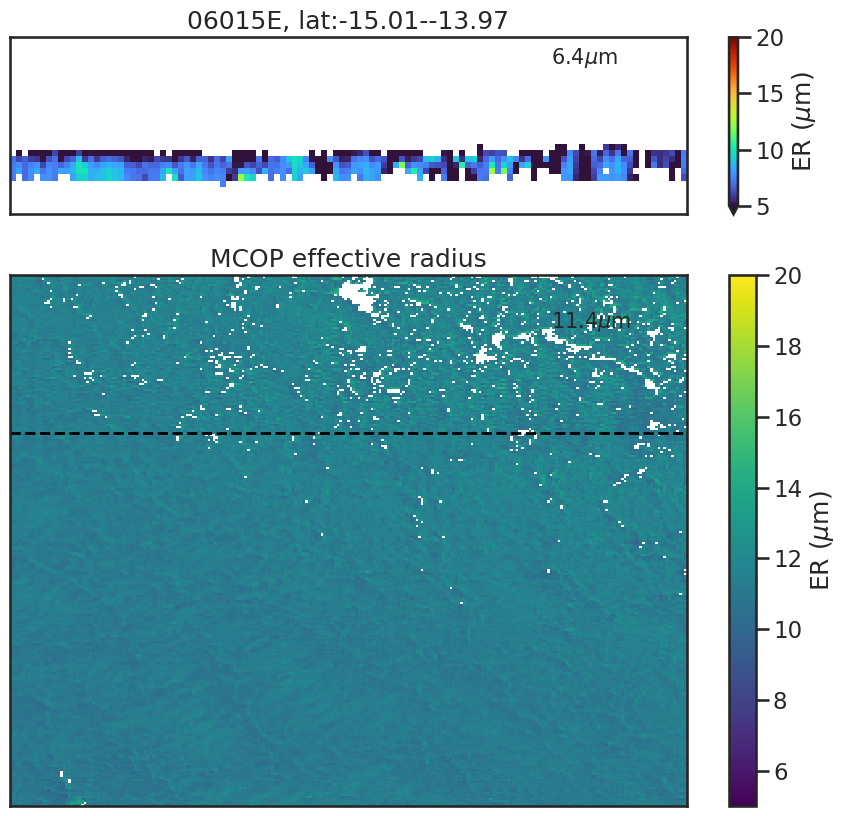

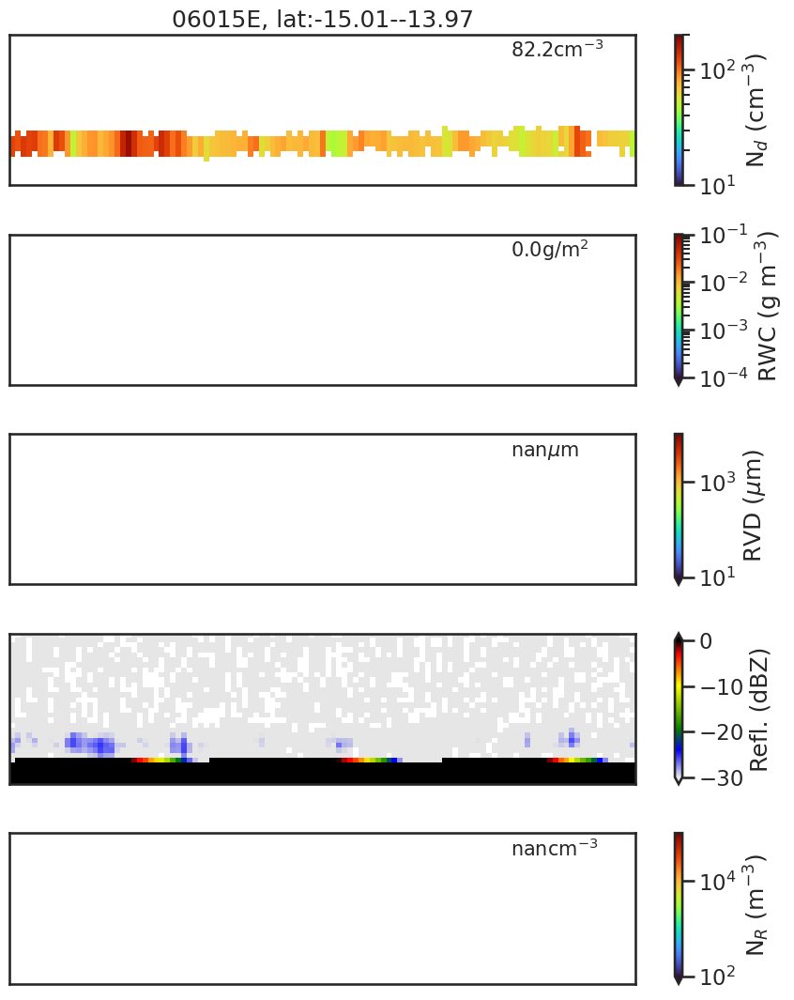

In [27]:
for si in dfcat_sel.scene_id.unique()[0:3]:
    print(dffil[dffil.scene_id == si].orbit.values[0])
    
    profile_cat = xr.DataArray(np.zeros((113, 30)), dims=['along_track', 'height'], coords={'along_track': np.arange(113), 'height': np.arange(30)*100})
    #print(si)
    dfex = dffil[dffil.scene_id == si]
    if len(dfex) != 1:
        print(f'skipping scene {si} with {len(dfex)} points')
        continue
    if dfex.cert.iloc[0] < 0.75:
        print(f'skipping scene {si} with low cert {dfex.cert.iloc[0]}')
        continue
    try:
        plot_ACMCAP_MCOP_for_scene_id(si)
    except Exception as e:
        print(f'Error plotting scene {si}: {e}')
        print('-'*40)

03203E
Loading ACM-CAP data via MAAP...
Accessing 1 items (limited by max_items).
1 items found that matched the query.
Found .h5 file in enclosure_h5: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/ACM_CAP_2B/BA/2024/12/20/ECA_EXBA_ACM_CAP_2B_20241220T195735Z_20250911T082158Z_03203E/ECA_EXBA_ACM_CAP_2B_20241220T195735Z_20250911T082158Z_03203E/ECA_EXBA_ACM_CAP_2B_20241220T195735Z_20250911T082158Z_03203E.h5
HDF5 URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/ACM_CAP_2B/BA/2024/12/20/ECA_EXBA_ACM_CAP_2B_20241220T195735Z_20250911T082158Z_03203E/ECA_EXBA_ACM_CAP_2B_20241220T195735Z_20250911T082158Z_03203E/ECA_EXBA_ACM_CAP_2B_20241220T195735Z_20250911T082158Z_03203E.h5
Orbit: 03203E
Fetching ESA MAAP token...
p1eL7uonXs6MDxtGbgKdPVRAmnGxHpVE
Dataset URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/ACM_CAP_2B/BA/2024/12/20/ECA_EXBA_ACM_CAP_2B_20241220T195735Z_20250911T082158Z_03203E/ECA_EXBA_ACM_CAP_2B_20241220T195735Z_20250911T08

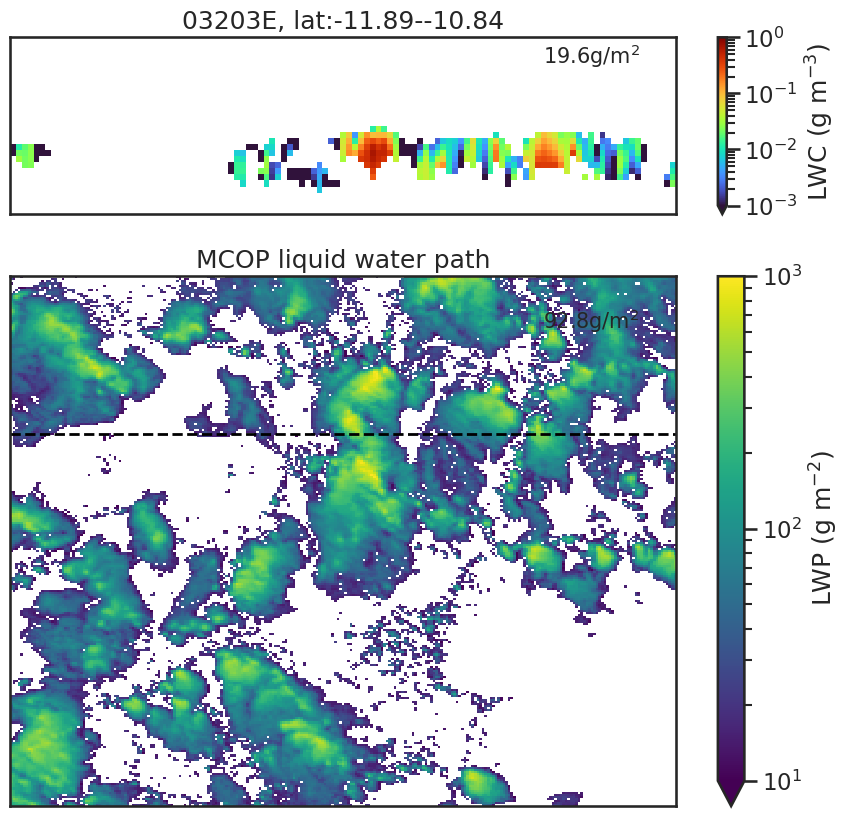

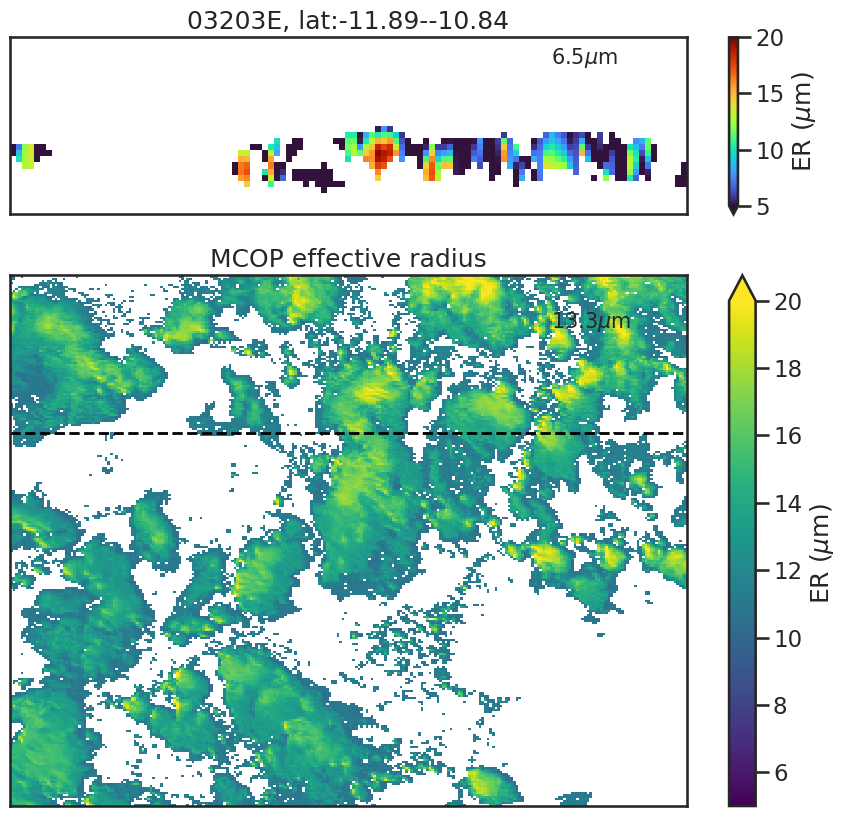

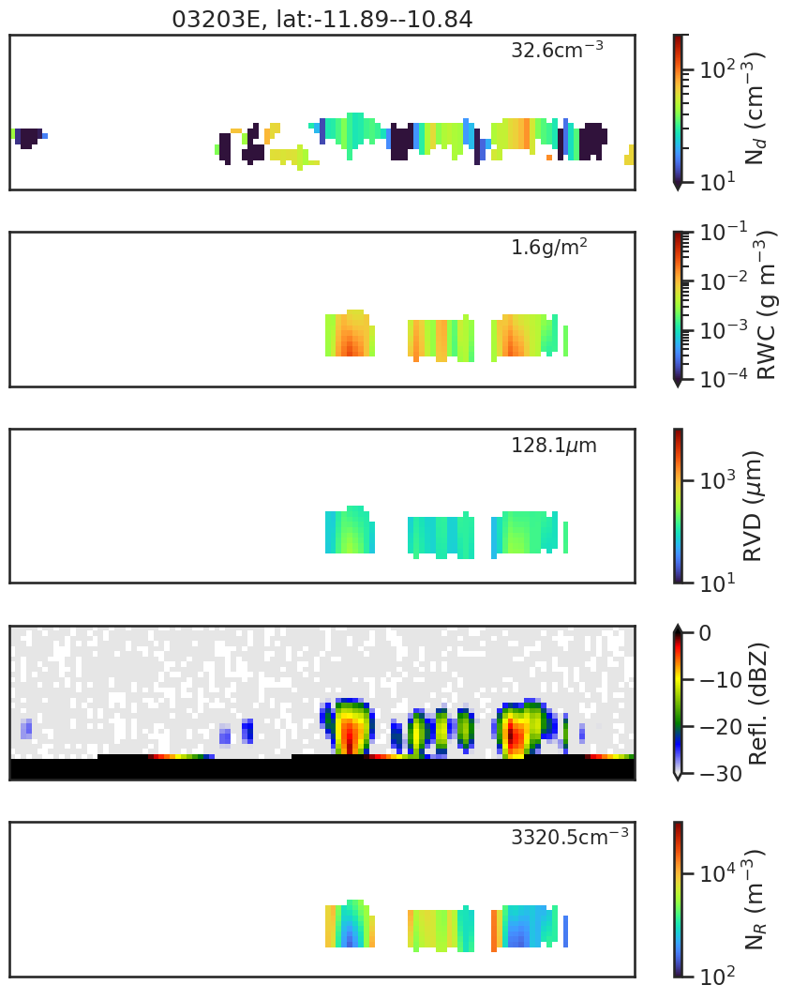

06844E
Loading ACM-CAP data via MAAP...
Accessing 1 items (limited by max_items).
1 items found that matched the query.
Found .h5 file in enclosure_h5: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/ACM_CAP_2B/BA/2025/08/11/ECA_EXBA_ACM_CAP_2B_20250811T195028Z_20250811T230313Z_06844E/ECA_EXBA_ACM_CAP_2B_20250811T195028Z_20250811T230313Z_06844E/ECA_EXBA_ACM_CAP_2B_20250811T195028Z_20250811T230313Z_06844E.h5
HDF5 URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/ACM_CAP_2B/BA/2025/08/11/ECA_EXBA_ACM_CAP_2B_20250811T195028Z_20250811T230313Z_06844E/ECA_EXBA_ACM_CAP_2B_20250811T195028Z_20250811T230313Z_06844E/ECA_EXBA_ACM_CAP_2B_20250811T195028Z_20250811T230313Z_06844E.h5
Orbit: 06844E
Fetching ESA MAAP token...
p1eL7uonXs6MDxtGbgKdPVRAmnGxHpVE
Dataset URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/ACM_CAP_2B/BA/2025/08/11/ECA_EXBA_ACM_CAP_2B_20250811T195028Z_20250811T230313Z_06844E/ECA_EXBA_ACM_CAP_2B_20250811T195028Z_20250811T23

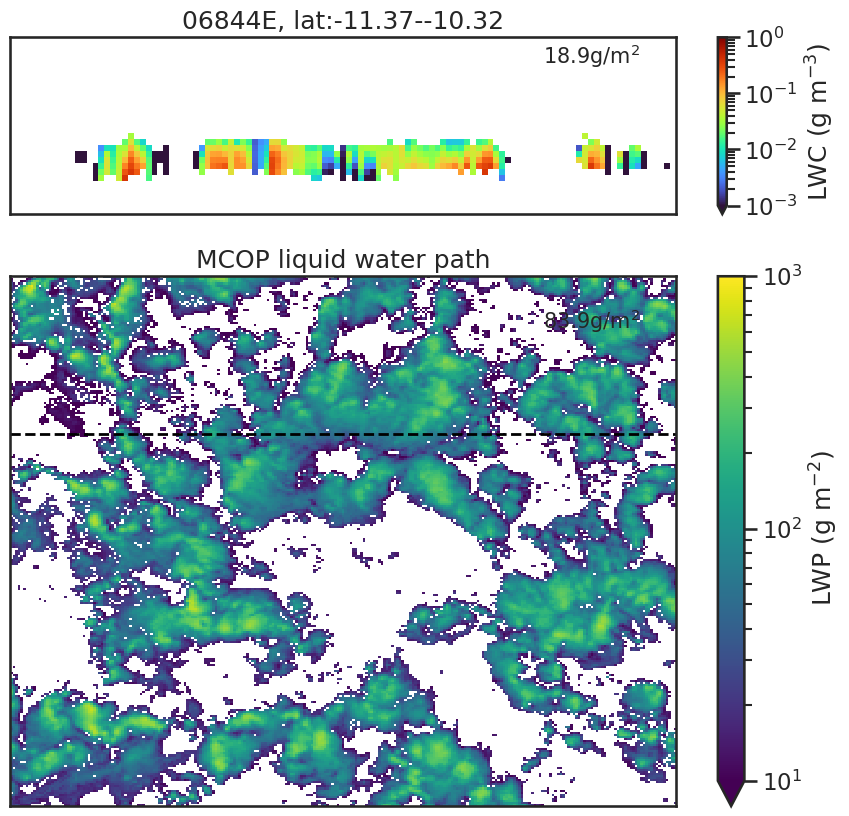

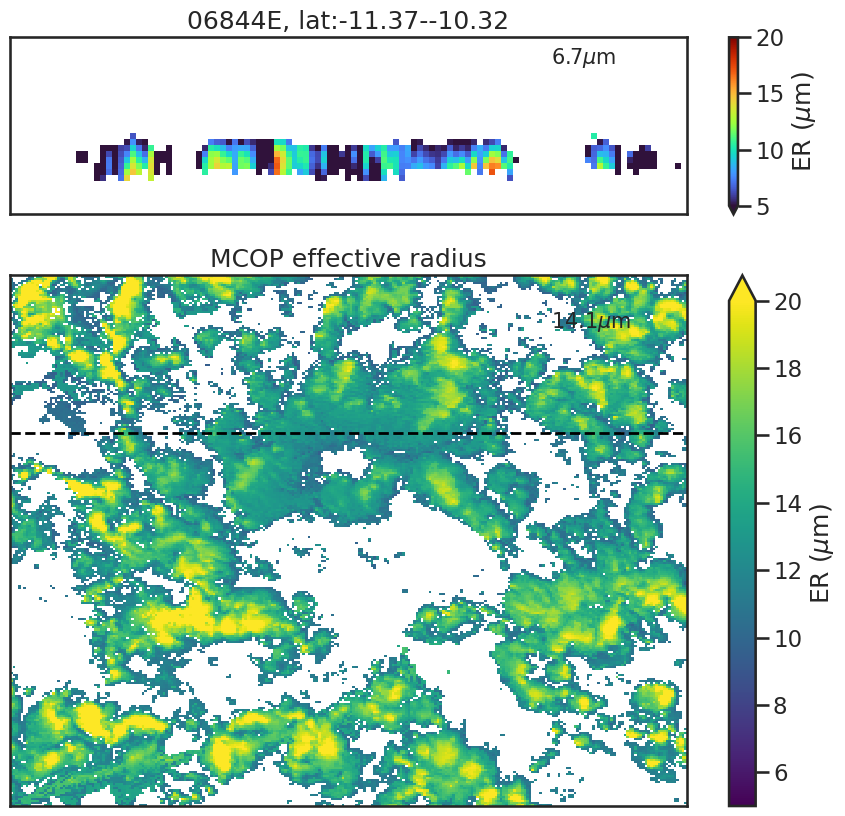

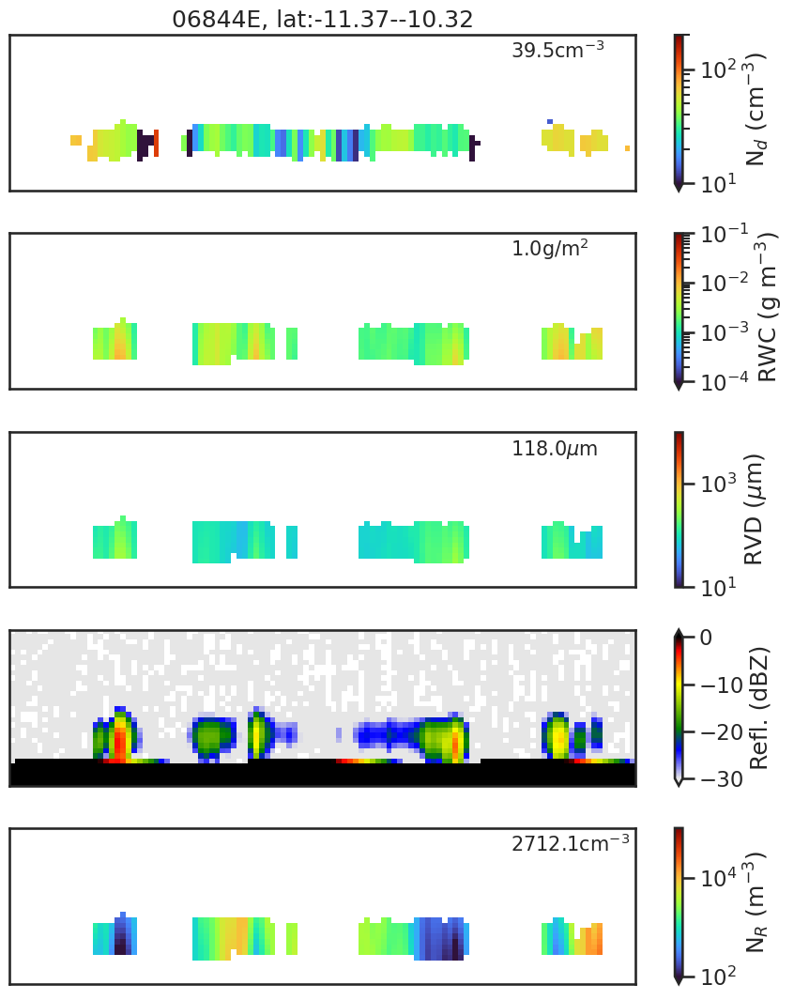

01538E
Loading ACM-CAP data via MAAP...
Accessing 1 items (limited by max_items).
1 items found that matched the query.
Found .h5 file in enclosure_h5: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/ACM_CAP_2B/BA/2024/09/04/ECA_EXBA_ACM_CAP_2B_20240904T195102Z_20250907T184325Z_01538E/ECA_EXBA_ACM_CAP_2B_20240904T195102Z_20250907T184325Z_01538E/ECA_EXBA_ACM_CAP_2B_20240904T195102Z_20250907T184325Z_01538E.h5
HDF5 URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/ACM_CAP_2B/BA/2024/09/04/ECA_EXBA_ACM_CAP_2B_20240904T195102Z_20250907T184325Z_01538E/ECA_EXBA_ACM_CAP_2B_20240904T195102Z_20250907T184325Z_01538E/ECA_EXBA_ACM_CAP_2B_20240904T195102Z_20250907T184325Z_01538E.h5
Orbit: 01538E
Fetching ESA MAAP token...
p1eL7uonXs6MDxtGbgKdPVRAmnGxHpVE
Dataset URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/ACM_CAP_2B/BA/2024/09/04/ECA_EXBA_ACM_CAP_2B_20240904T195102Z_20250907T184325Z_01538E/ECA_EXBA_ACM_CAP_2B_20240904T195102Z_20250907T18

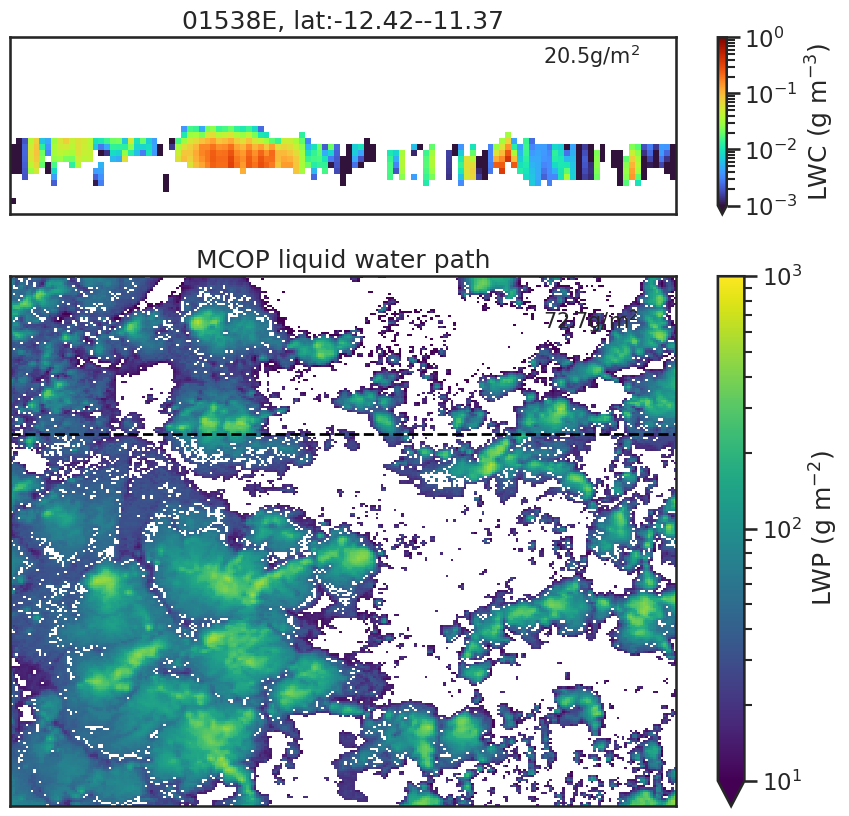

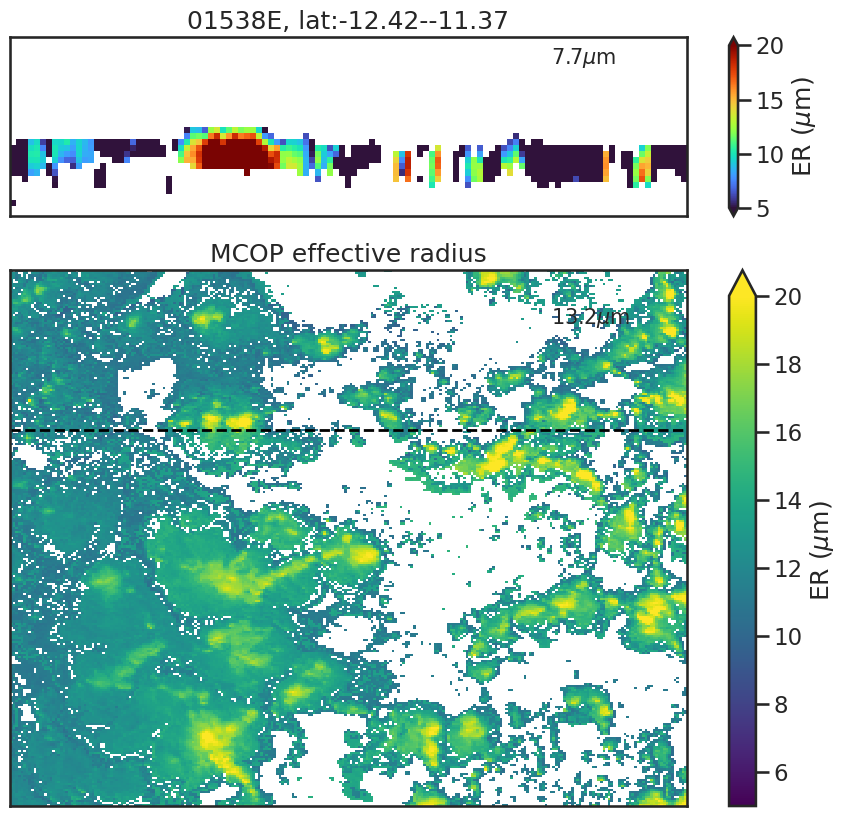

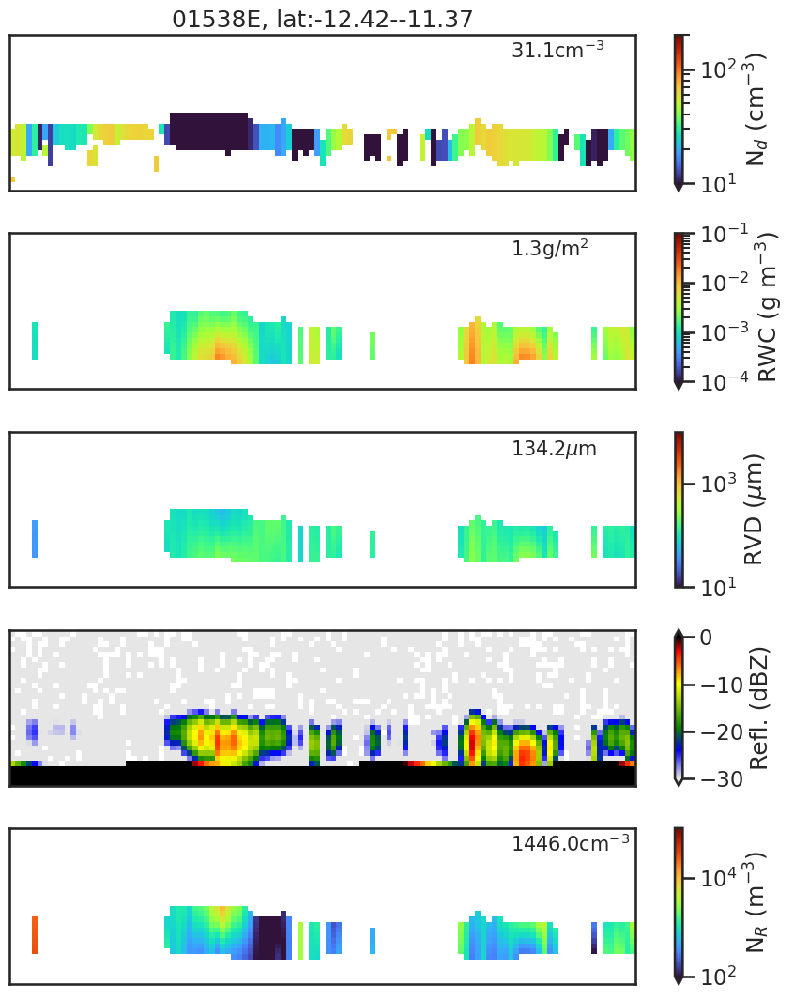

07727E
Loading ACM-CAP data via MAAP...
Accessing 1 items (limited by max_items).
1 items found that matched the query.
Found .h5 file in enclosure_h5: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/ACM_CAP_2B/BA/2025/10/07/ECA_EXBA_ACM_CAP_2B_20251007T134713Z_20251008T161900Z_07727E/ECA_EXBA_ACM_CAP_2B_20251007T134713Z_20251008T161900Z_07727E/ECA_EXBA_ACM_CAP_2B_20251007T134713Z_20251008T161900Z_07727E.h5
HDF5 URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/ACM_CAP_2B/BA/2025/10/07/ECA_EXBA_ACM_CAP_2B_20251007T134713Z_20251008T161900Z_07727E/ECA_EXBA_ACM_CAP_2B_20251007T134713Z_20251008T161900Z_07727E/ECA_EXBA_ACM_CAP_2B_20251007T134713Z_20251008T161900Z_07727E.h5
Orbit: 07727E
Fetching ESA MAAP token...
p1eL7uonXs6MDxtGbgKdPVRAmnGxHpVE
Dataset URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/ACM_CAP_2B/BA/2025/10/07/ECA_EXBA_ACM_CAP_2B_20251007T134713Z_20251008T161900Z_07727E/ECA_EXBA_ACM_CAP_2B_20251007T134713Z_20251008T16

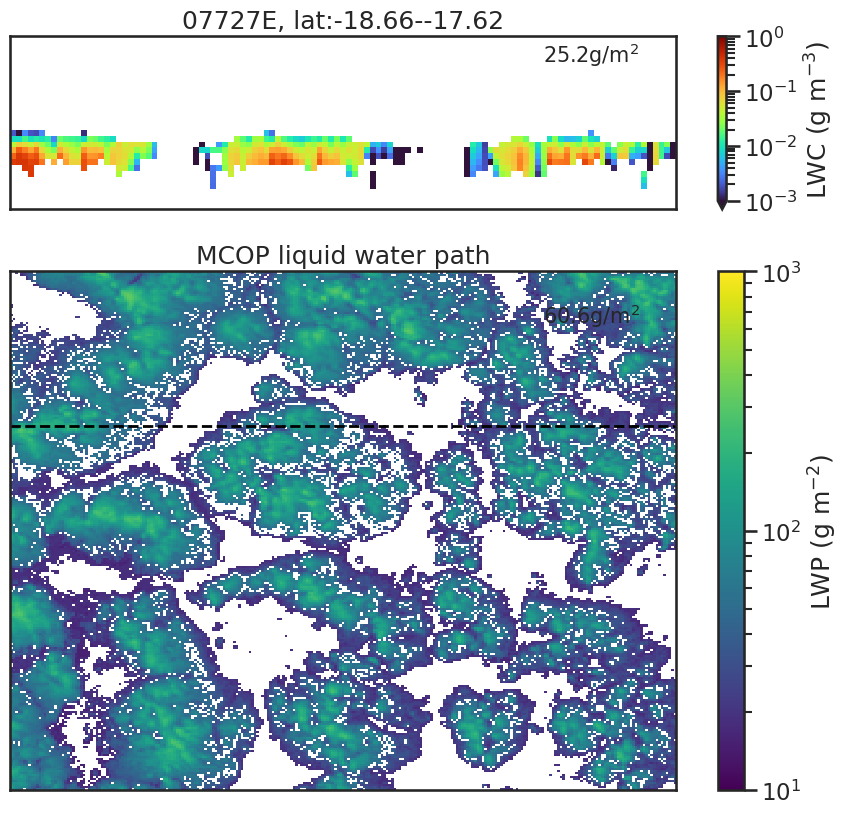

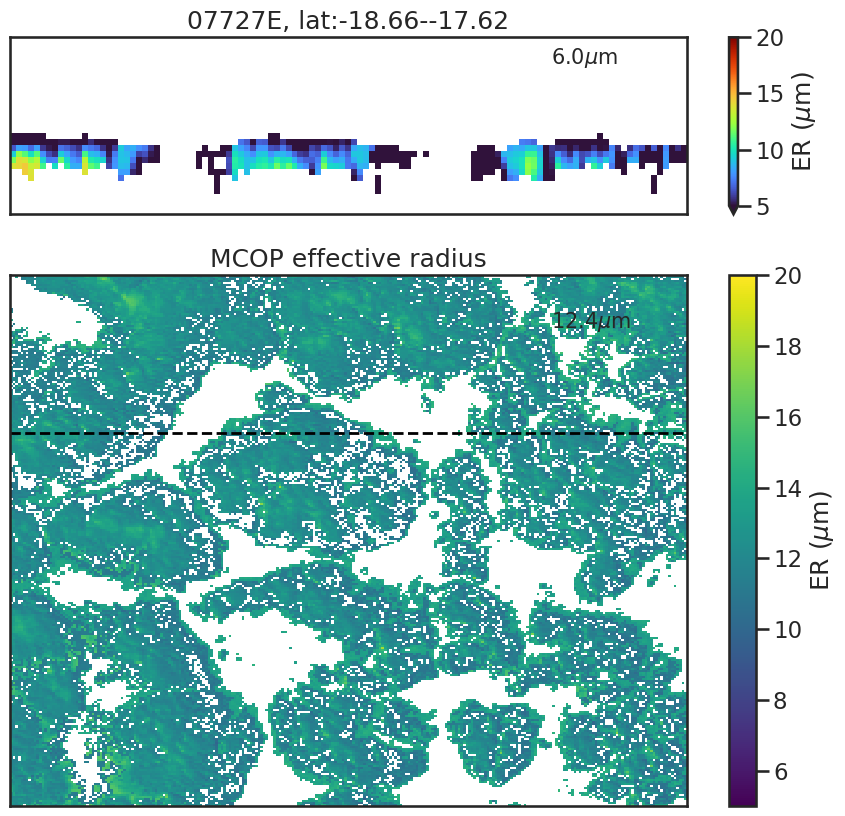

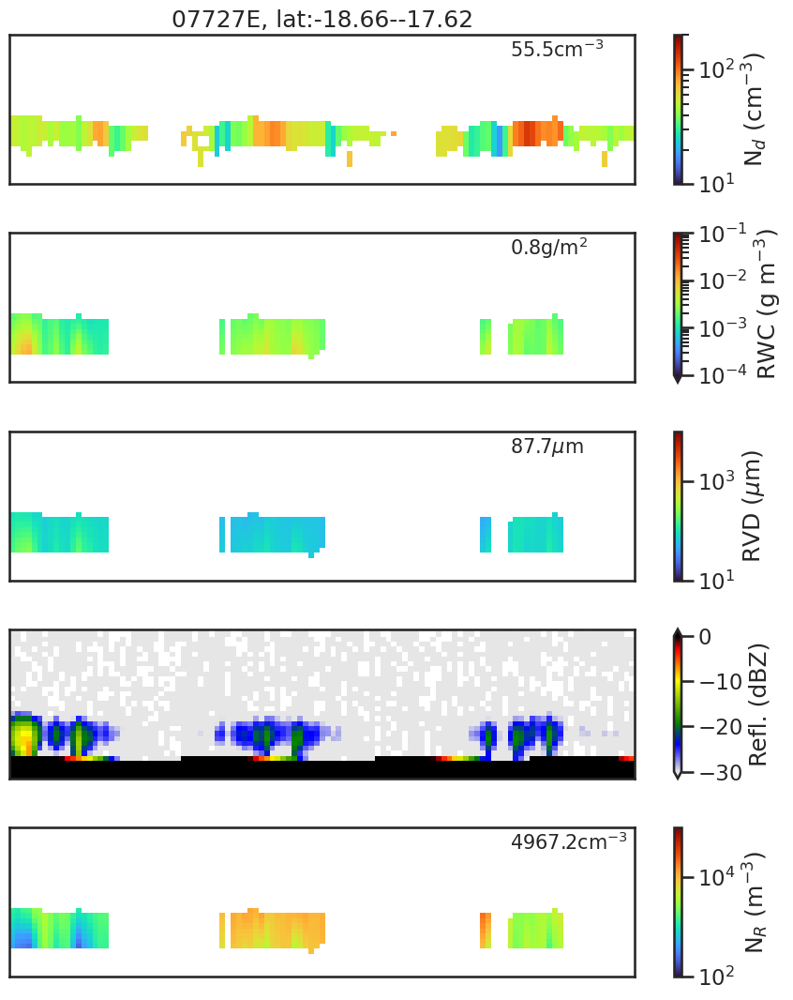

01538E
Loading ACM-CAP data via MAAP...
Accessing 1 items (limited by max_items).
1 items found that matched the query.
Found .h5 file in enclosure_h5: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/ACM_CAP_2B/BA/2024/09/04/ECA_EXBA_ACM_CAP_2B_20240904T195102Z_20250907T184325Z_01538E/ECA_EXBA_ACM_CAP_2B_20240904T195102Z_20250907T184325Z_01538E/ECA_EXBA_ACM_CAP_2B_20240904T195102Z_20250907T184325Z_01538E.h5
HDF5 URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/ACM_CAP_2B/BA/2024/09/04/ECA_EXBA_ACM_CAP_2B_20240904T195102Z_20250907T184325Z_01538E/ECA_EXBA_ACM_CAP_2B_20240904T195102Z_20250907T184325Z_01538E/ECA_EXBA_ACM_CAP_2B_20240904T195102Z_20250907T184325Z_01538E.h5
Orbit: 01538E
Fetching ESA MAAP token...
p1eL7uonXs6MDxtGbgKdPVRAmnGxHpVE
Dataset URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/ACM_CAP_2B/BA/2024/09/04/ECA_EXBA_ACM_CAP_2B_20240904T195102Z_20250907T184325Z_01538E/ECA_EXBA_ACM_CAP_2B_20240904T195102Z_20250907T18

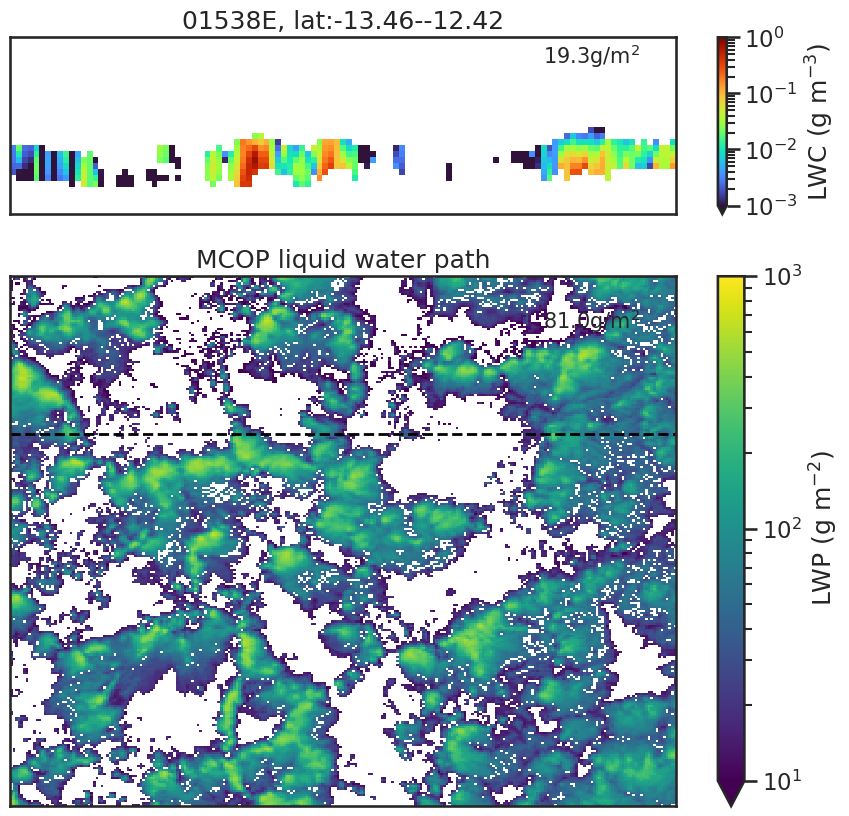

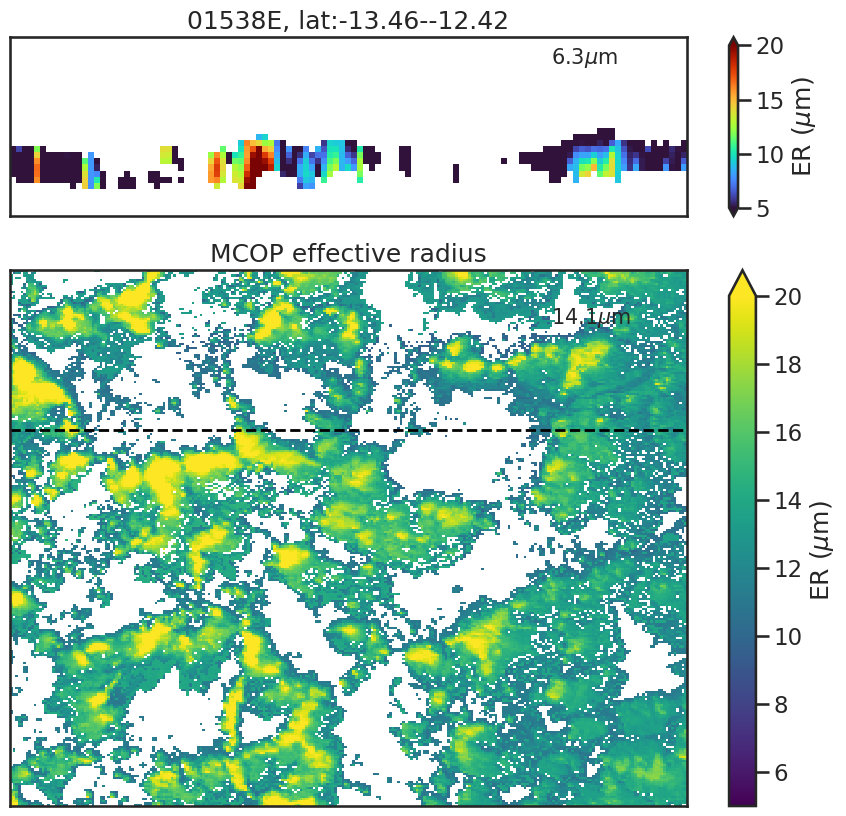

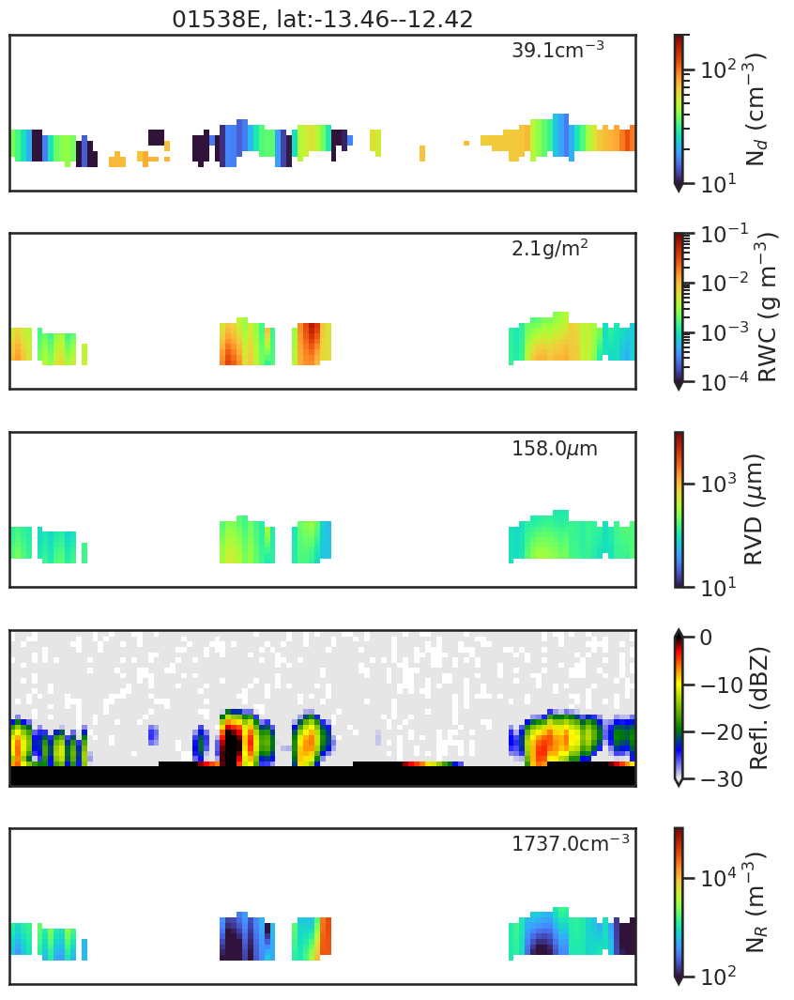

01087E
Loading ACM-CAP data via MAAP...
Accessing 1 items (limited by max_items).
1 items found that matched the query.
Found .h5 file in enclosure_h5: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/ACM_CAP_2B/BA/2024/08/06/ECA_EXBA_ACM_CAP_2B_20240806T200218Z_20250905T085308Z_01087E/ECA_EXBA_ACM_CAP_2B_20240806T200218Z_20250905T085308Z_01087E/ECA_EXBA_ACM_CAP_2B_20240806T200218Z_20250905T085308Z_01087E.h5
HDF5 URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/ACM_CAP_2B/BA/2024/08/06/ECA_EXBA_ACM_CAP_2B_20240806T200218Z_20250905T085308Z_01087E/ECA_EXBA_ACM_CAP_2B_20240806T200218Z_20250905T085308Z_01087E/ECA_EXBA_ACM_CAP_2B_20240806T200218Z_20250905T085308Z_01087E.h5
Orbit: 01087E
Fetching ESA MAAP token...
p1eL7uonXs6MDxtGbgKdPVRAmnGxHpVE
Dataset URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/ACM_CAP_2B/BA/2024/08/06/ECA_EXBA_ACM_CAP_2B_20240806T200218Z_20250905T085308Z_01087E/ECA_EXBA_ACM_CAP_2B_20240806T200218Z_20250905T08

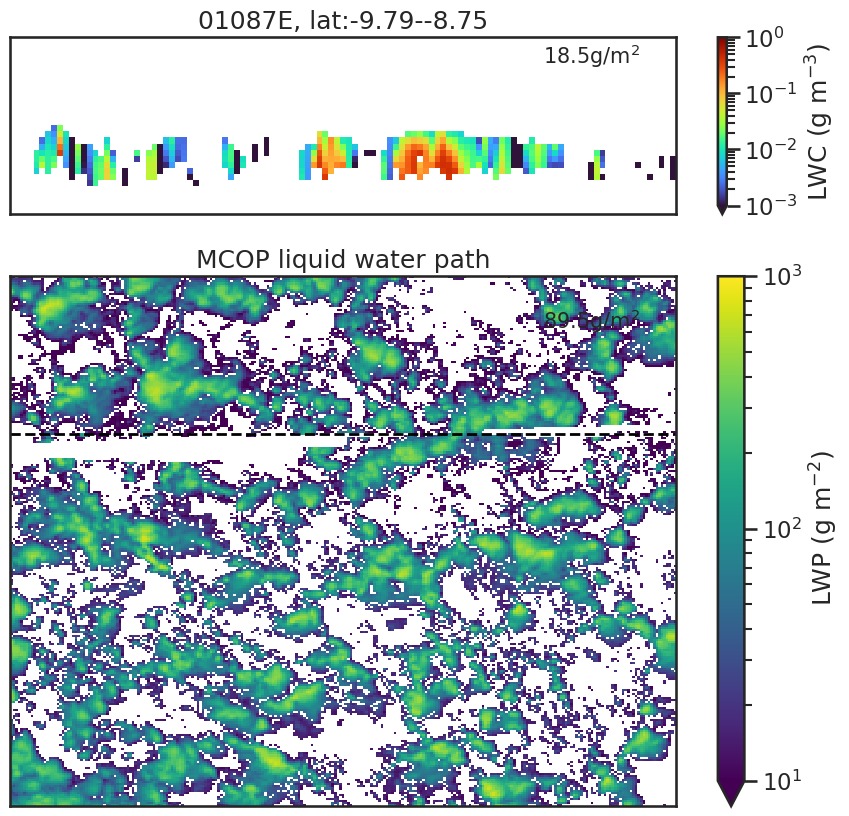

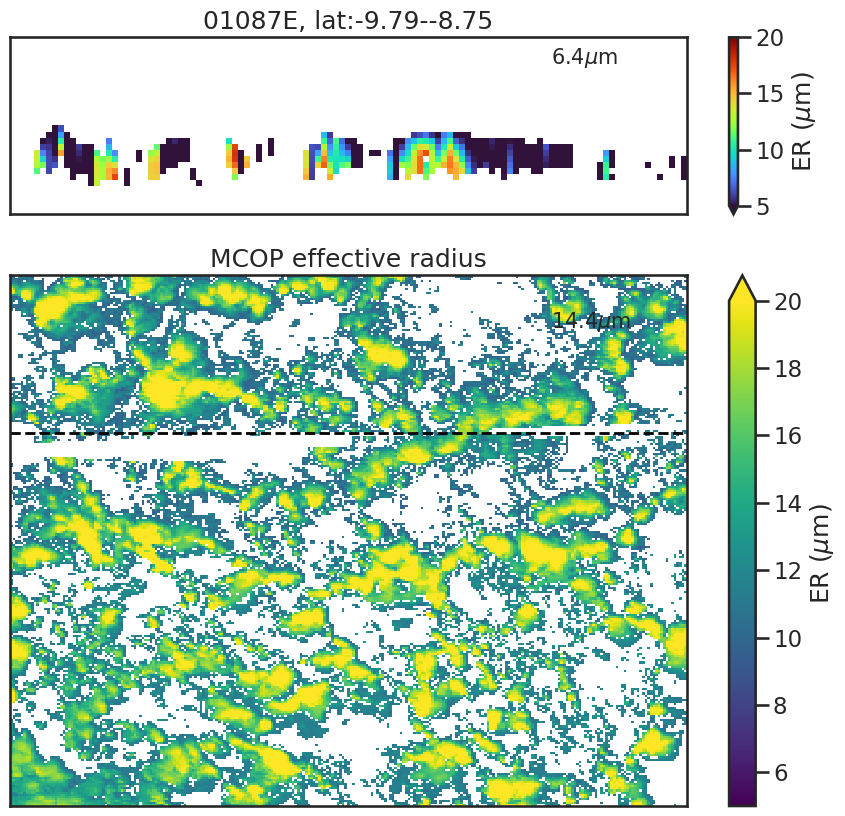

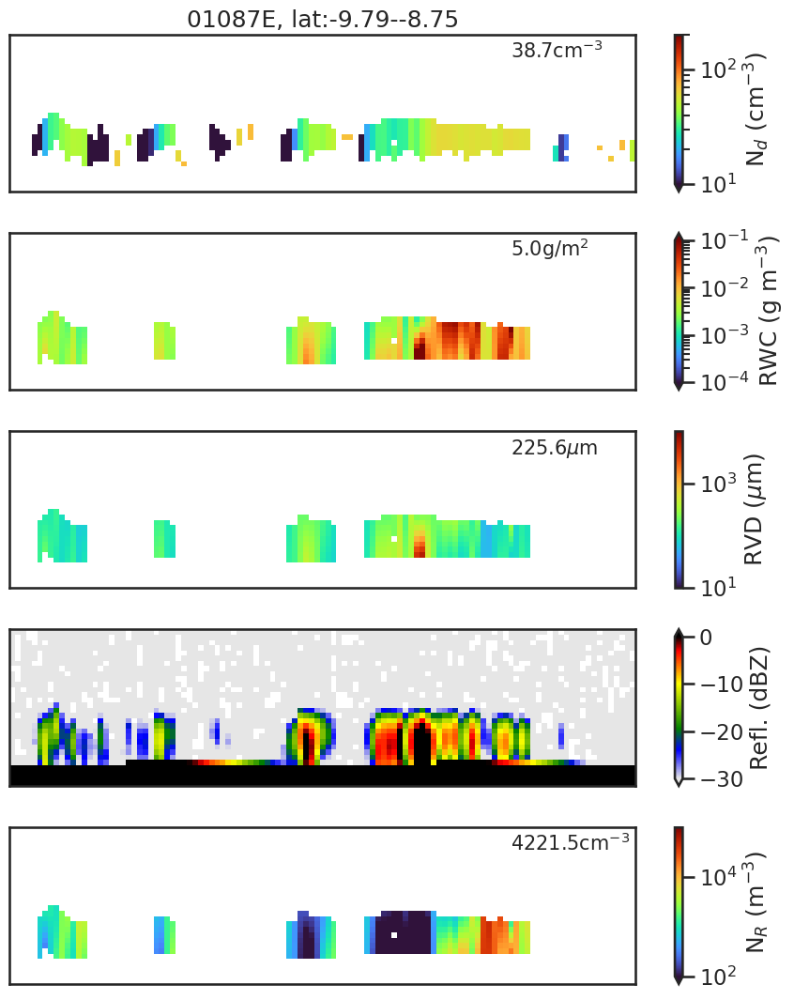

06704E
Loading ACM-CAP data via MAAP...
Accessing 1 items (limited by max_items).
1 items found that matched the query.
Found .h5 file in enclosure_h5: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/ACM_CAP_2B/BA/2025/08/02/ECA_EXBA_ACM_CAP_2B_20250802T195415Z_20250802T230301Z_06704E/ECA_EXBA_ACM_CAP_2B_20250802T195415Z_20250802T230301Z_06704E/ECA_EXBA_ACM_CAP_2B_20250802T195415Z_20250802T230301Z_06704E.h5
HDF5 URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/ACM_CAP_2B/BA/2025/08/02/ECA_EXBA_ACM_CAP_2B_20250802T195415Z_20250802T230301Z_06704E/ECA_EXBA_ACM_CAP_2B_20250802T195415Z_20250802T230301Z_06704E/ECA_EXBA_ACM_CAP_2B_20250802T195415Z_20250802T230301Z_06704E.h5
Orbit: 06704E
Fetching ESA MAAP token...
p1eL7uonXs6MDxtGbgKdPVRAmnGxHpVE
Dataset URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/ACM_CAP_2B/BA/2025/08/02/ECA_EXBA_ACM_CAP_2B_20250802T195415Z_20250802T230301Z_06704E/ECA_EXBA_ACM_CAP_2B_20250802T195415Z_20250802T23

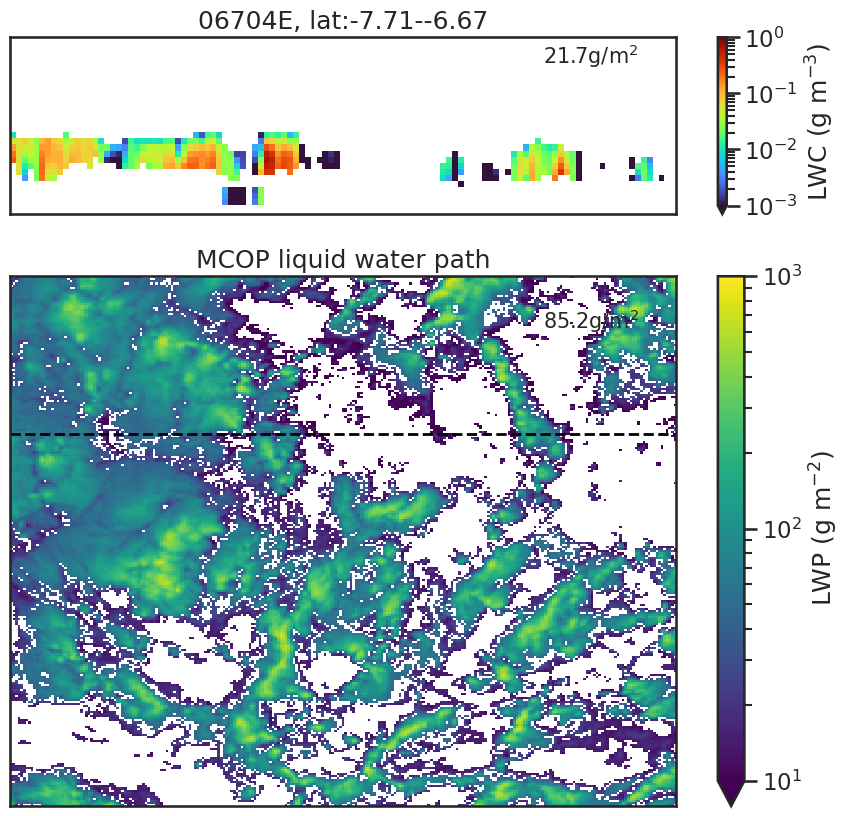

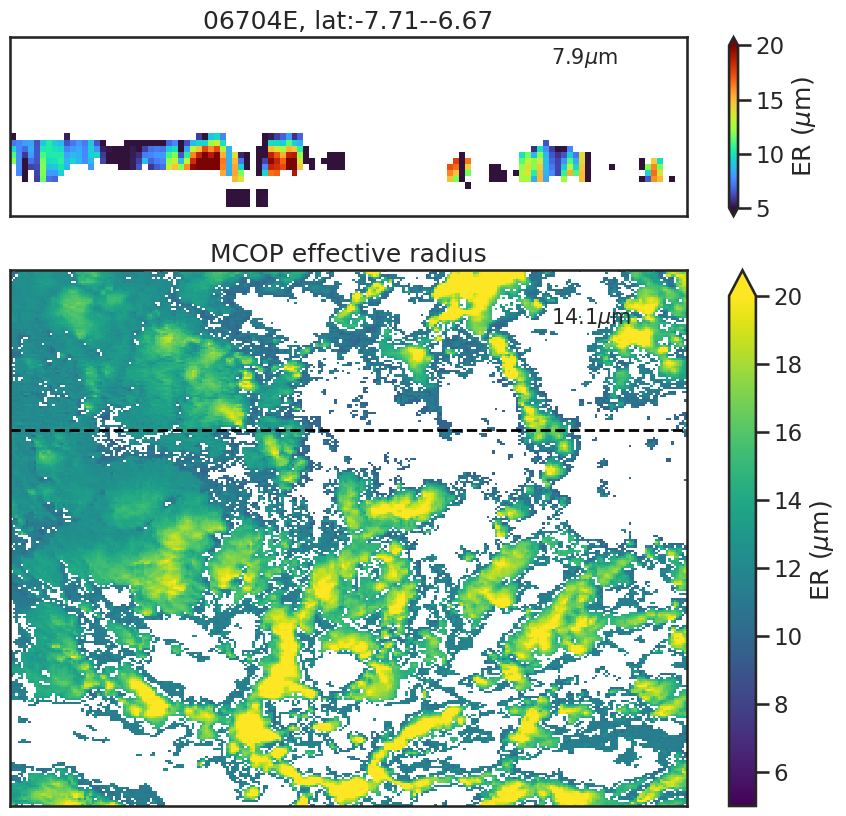

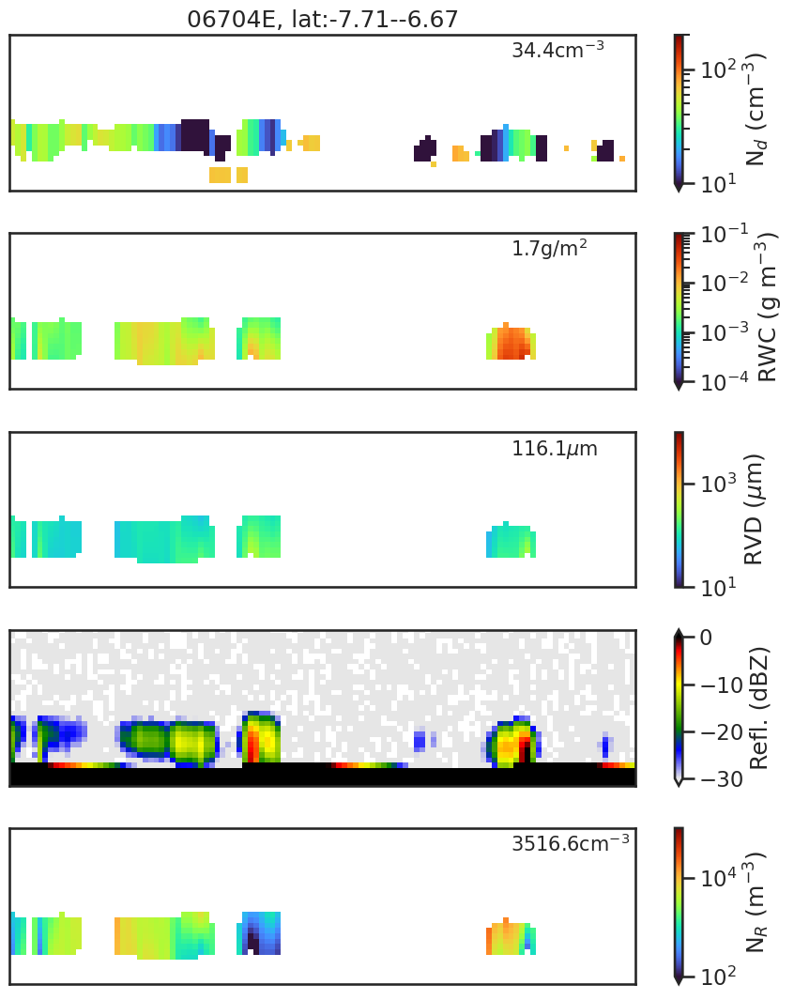

01367E
Loading ACM-CAP data via MAAP...
Accessing 1 items (limited by max_items).
1 items found that matched the query.
Found .h5 file in enclosure_h5: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/ACM_CAP_2B/BA/2024/08/24/ECA_EXBA_ACM_CAP_2B_20240824T200602Z_20250905T143812Z_01367E/ECA_EXBA_ACM_CAP_2B_20240824T200602Z_20250905T143812Z_01367E/ECA_EXBA_ACM_CAP_2B_20240824T200602Z_20250905T143812Z_01367E.h5
HDF5 URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/ACM_CAP_2B/BA/2024/08/24/ECA_EXBA_ACM_CAP_2B_20240824T200602Z_20250905T143812Z_01367E/ECA_EXBA_ACM_CAP_2B_20240824T200602Z_20250905T143812Z_01367E/ECA_EXBA_ACM_CAP_2B_20240824T200602Z_20250905T143812Z_01367E.h5
Orbit: 01367E
Fetching ESA MAAP token...
p1eL7uonXs6MDxtGbgKdPVRAmnGxHpVE
Dataset URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/ACM_CAP_2B/BA/2024/08/24/ECA_EXBA_ACM_CAP_2B_20240824T200602Z_20250905T143812Z_01367E/ECA_EXBA_ACM_CAP_2B_20240824T200602Z_20250905T14

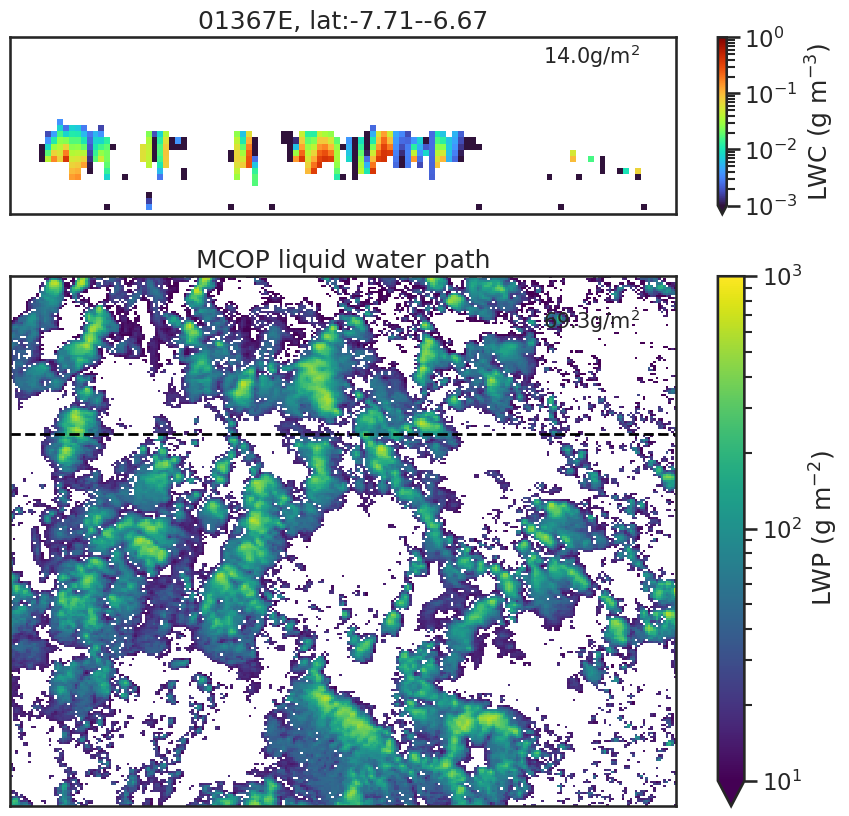

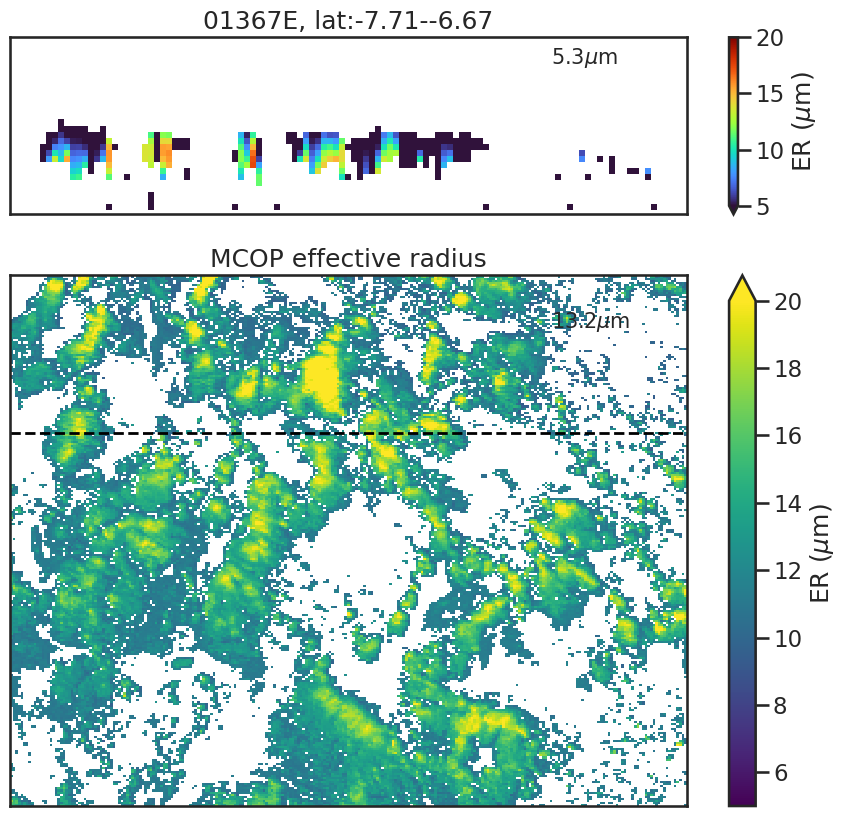

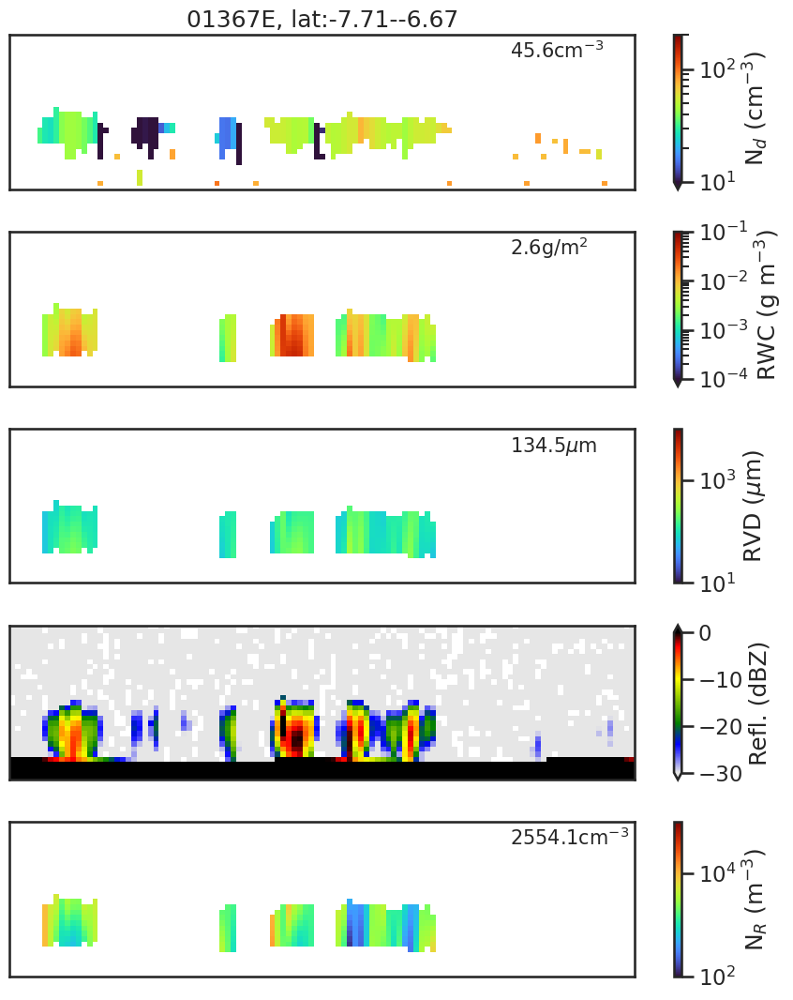

07727E
Loading ACM-CAP data via MAAP...
Accessing 1 items (limited by max_items).
1 items found that matched the query.
Found .h5 file in enclosure_h5: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/ACM_CAP_2B/BA/2025/10/07/ECA_EXBA_ACM_CAP_2B_20251007T134713Z_20251008T161900Z_07727E/ECA_EXBA_ACM_CAP_2B_20251007T134713Z_20251008T161900Z_07727E/ECA_EXBA_ACM_CAP_2B_20251007T134713Z_20251008T161900Z_07727E.h5
HDF5 URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/ACM_CAP_2B/BA/2025/10/07/ECA_EXBA_ACM_CAP_2B_20251007T134713Z_20251008T161900Z_07727E/ECA_EXBA_ACM_CAP_2B_20251007T134713Z_20251008T161900Z_07727E/ECA_EXBA_ACM_CAP_2B_20251007T134713Z_20251008T161900Z_07727E.h5
Orbit: 07727E
Fetching ESA MAAP token...
p1eL7uonXs6MDxtGbgKdPVRAmnGxHpVE
Dataset URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/ACM_CAP_2B/BA/2025/10/07/ECA_EXBA_ACM_CAP_2B_20251007T134713Z_20251008T161900Z_07727E/ECA_EXBA_ACM_CAP_2B_20251007T134713Z_20251008T16

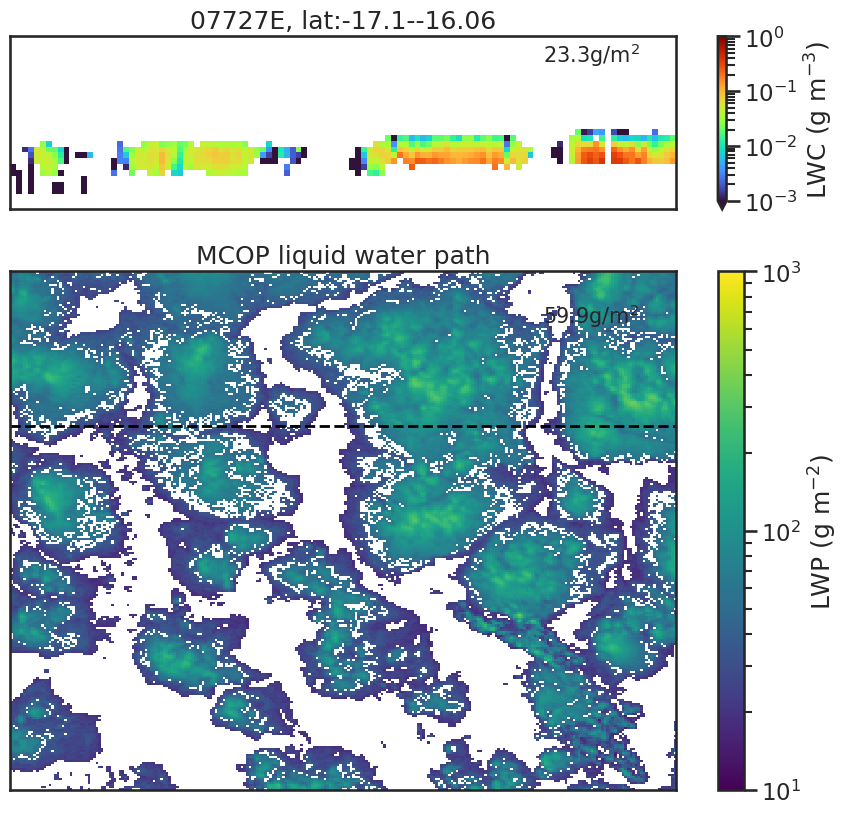

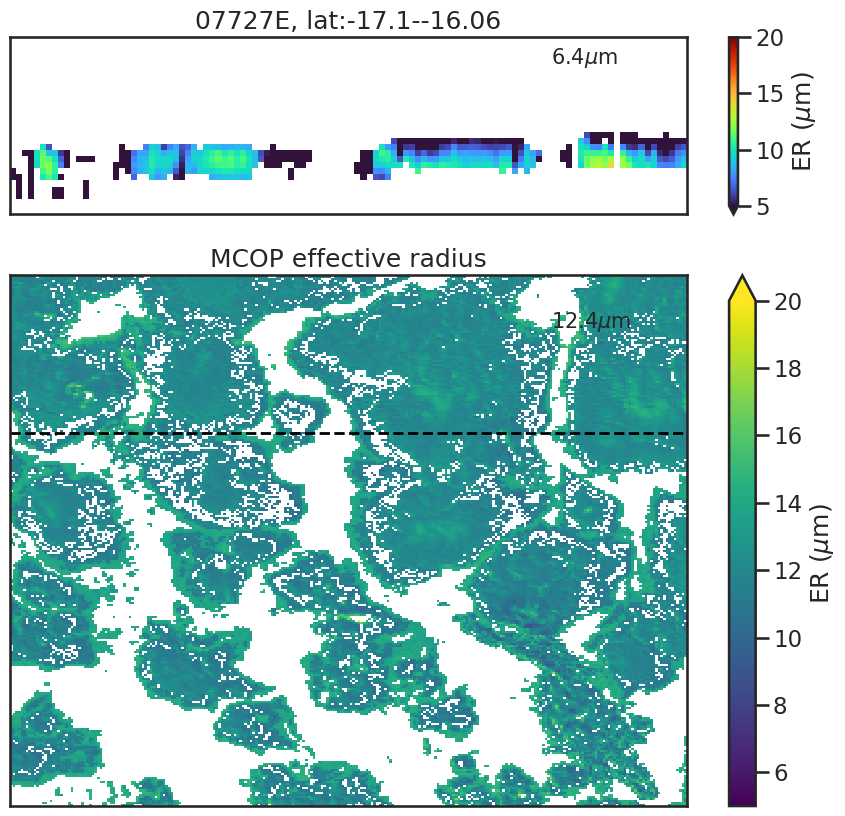

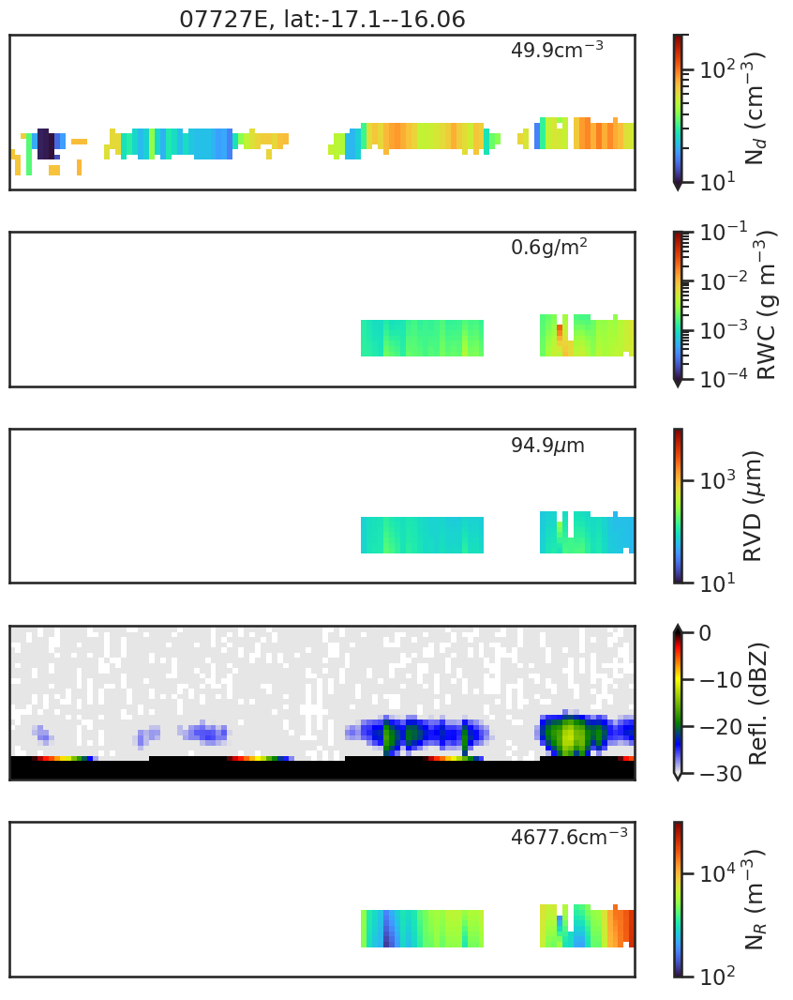

06455E
Loading ACM-CAP data via MAAP...
Accessing 1 items (limited by max_items).
1 items found that matched the query.
Found .h5 file in enclosure_h5: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/ACM_CAP_2B/BA/2025/07/17/ECA_EXBA_ACM_CAP_2B_20250717T195043Z_20250717T230247Z_06455E/ECA_EXBA_ACM_CAP_2B_20250717T195043Z_20250717T230247Z_06455E/ECA_EXBA_ACM_CAP_2B_20250717T195043Z_20250717T230247Z_06455E.h5
HDF5 URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/ACM_CAP_2B/BA/2025/07/17/ECA_EXBA_ACM_CAP_2B_20250717T195043Z_20250717T230247Z_06455E/ECA_EXBA_ACM_CAP_2B_20250717T195043Z_20250717T230247Z_06455E/ECA_EXBA_ACM_CAP_2B_20250717T195043Z_20250717T230247Z_06455E.h5
Orbit: 06455E
Fetching ESA MAAP token...
p1eL7uonXs6MDxtGbgKdPVRAmnGxHpVE
Dataset URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/ACM_CAP_2B/BA/2025/07/17/ECA_EXBA_ACM_CAP_2B_20250717T195043Z_20250717T230247Z_06455E/ECA_EXBA_ACM_CAP_2B_20250717T195043Z_20250717T23

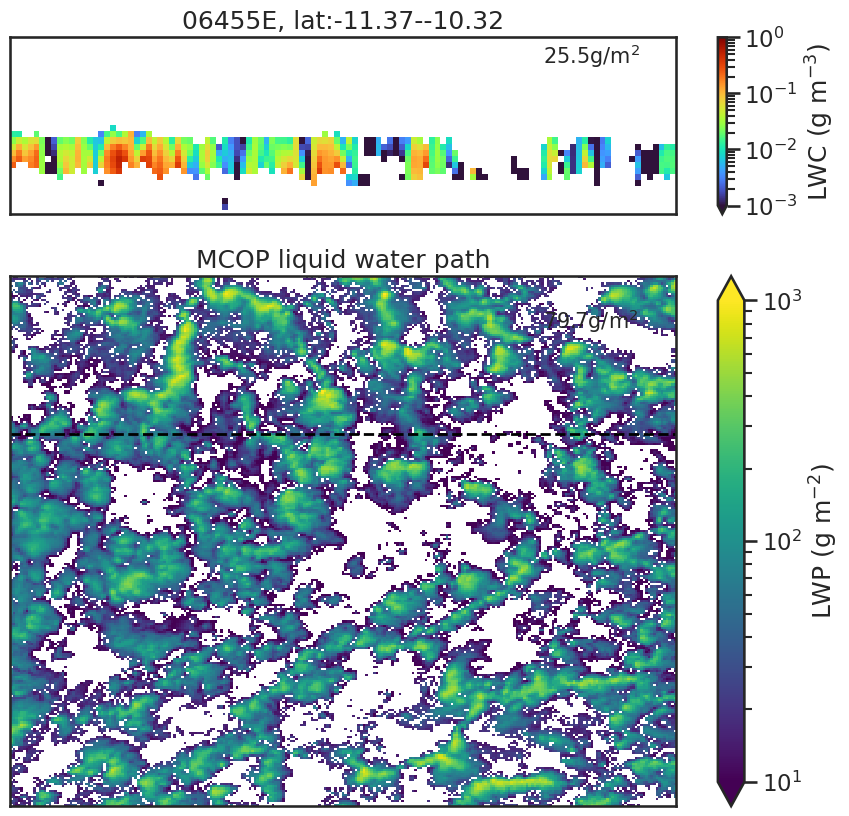

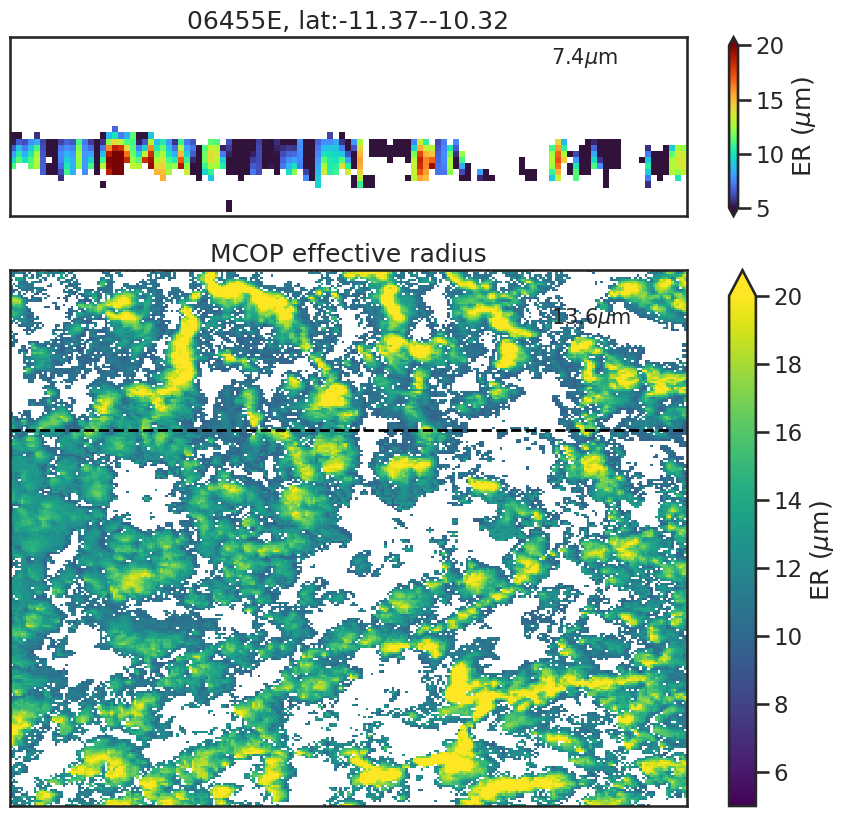

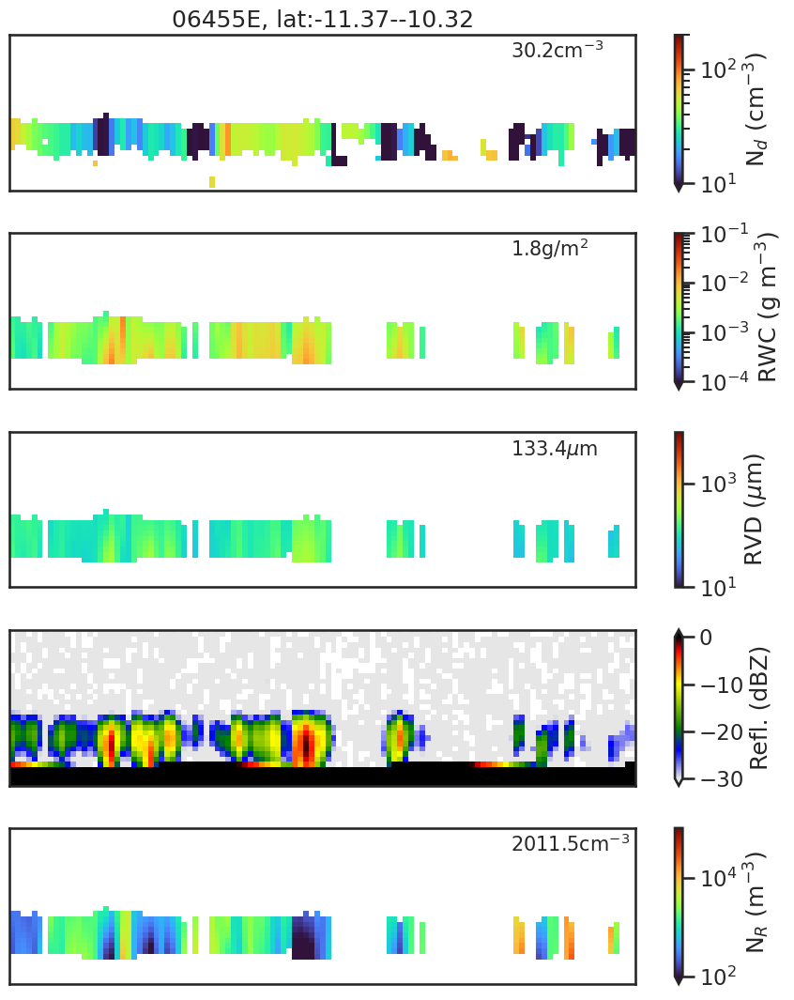

In [36]:
for si in dfcat_sel.scene_id.unique()[0:10]:
    print(dffil[dffil.scene_id == si].orbit.values[0])
    
    profile_cat = xr.DataArray(np.zeros((113, 30)), dims=['along_track', 'height'], coords={'along_track': np.arange(113), 'height': np.arange(30)*100})
    #print(si)
    dfex = dffil[dffil.scene_id == si]
    if len(dfex) != 1:
        print(f'skipping scene {si} with {len(dfex)} points')
        continue
    if dfex.cert.iloc[0] < 0.75:
        print(f'skipping scene {si} with low cert {dfex.cert.iloc[0]}')
        continue
    try:
        plot_ACMCAP_MCOP_for_scene_id(si)
    except Exception as e:
        print(f'Error plotting scene {si}: {e}')
        print('-'*40)

### Examples for publication

In [ ]:
def plot_ACMCAP_MCOP_for_scene_id(scene_id):
    sys.path.append('/home/jmayer/ACI_research/Code/mesoscale_structure/')
    import access_ec_on_maap as maap
    sys.path.append('./../../../ectools/')
    from ectools import colormaps

    dfscene = dffil[dffil.scene_id == scene_id]
    orbit = dfscene.orbit.values[0]
    time_mid = dfscene.time_mid.values[0]
    year = pd.to_datetime(time_mid).year
    month = pd.to_datetime(time_mid).month
    day = pd.to_datetime(time_mid).day
    lat_max = dfscene.lat_max.values[0]
    lat_min = dfscene.lat_min.values[0]
    lon_mid = dfscene.lon_mid.values[0]
    lat_mid = dfscene.lat_mid.values[0]
    region_idx = dfscene.stratus_region_index.values[0]
    region = stratus_region_names[region_idx]

    #filename = glob.glob(f'/home/jmayer/Object_Data/ACM_CAP_2B/{year}/{month:02d}/{day:02d}/*_{orbit}.h5')[0]
    #ACMCAP = ecio.load_ACMCAP(filename)
    #encoding = ACMCAP.encoding
    print('Loading ACM-CAP data via MAAP...')
    ACMCAP_list = maap.get_acmcap_via_maap(
                        region=region, 
                        frame=orbit[-1],
                        orbitNumber=orbit[:-1],
                        max_items=1,
                        )
    ACMCAP = ACMCAP_list[0][0]
    encoding = ACMCAP.encoding
    ACMCAP = ACMCAP.where((ACMCAP.latitude > lat_min) & (ACMCAP.latitude < lat_max), drop=True)
    ACMCAP.encoding = encoding.copy()
    ACMCAP = ACMCAP.assign_coords(height_coord=("JSG_height", ACMCAP.height.isel(along_track=0).data))
    ACMCAP = ACMCAP.swap_dims({'JSG_height': 'height_coord'})

    # load MCOP
    MCOP_list = maap.get_mcop_via_maap(
            region=region, 
            frame=orbit[-1],
            orbitNumber=orbit[:-1],
            mcop_variables=['time', 'latitude', 'longitude', 'cloud_optical_thickness', 'cloud_water_path','cloud_effective_radius'], 
            max_items=1)
        
    MCOP, _ = MCOP_list[0]

    MCOP = MCOP.assign_coords(
        {
        'along_track': (
            ["along_track"],
            MCOP['along_track'].data,
            MCOP['along_track'].attrs
            ),
        'across_track': (
            ['across_track'],
            MCOP['across_track'].data,
            MCOP['across_track'].attrs
            )
        })
    along_track_min = np.abs(MCOP.sel(across_track=284).latitude - lat_min).argmin()
    along_track_max = np.abs(MCOP.sel(across_track=284).latitude - lat_max).argmin()
    MCOP2 = MCOP.sel(along_track=slice(MCOP.along_track[along_track_max], MCOP.along_track[along_track_min]))
    MCOP2 = MCOP2.sel(across_track=slice(360 - 256, 360))

    # load C-FMR
    CFMR_list = maap.get_cfmr_via_maap(
                        frame=orbit[-1],
                        orbitNumber=orbit[:-1],
                        max_items=1,
                        )
    CFMR = CFMR_list[0][0]
    CFMR = CFMR.where((CFMR.latitude > lat_min) & (CFMR.latitude < lat_max), drop=True)
    CFMR = CFMR.assign_coords(height_coord=("CPR_height", CFMR.height.isel(along_track=0).data))
    CFMR = CFMR.swap_dims({'CPR_height': 'height_coord'})
    CFMR = CFMR.where(CFMR.height_coord > -500, drop=True)

    # load CCD
    #CCD_list = maap.get_ccd_via_maap(
    #                frame=orbit[-1],
    #                orbitNumber=orbit[:-1],
    #                max_items=1,
    #                )
    #CCD = CCD_list[0][0]
    #CCD = CCD.where((CCD.latitude > lat_min) & (CCD.latitude < lat_max), drop=True)
    #CCD = CCD.assign_coords(height_coord=("CPR_height", CCD.height.isel(along_track=0).data))
    #CCD = CCD.swap_dims({'CPR_height': 'height_coord'})
    #CCD = CCD.where(CCD.height_coord > -500, drop=True)

    # plot
    sns.set_context('talk')
    import matplotlib.gridspec as gridspec

    fig = plt.figure(figsize=(25, 8.5))

    # Outer grid: 1 row, 3 columns
    outer_gs = gridspec.GridSpec(1, 3, figure=fig)

    # Columns 0 and 1: 2 rows with height_ratios [1, 3]
    inner_gs_col0 = gridspec.GridSpecFromSubplotSpec(2, 1, subplot_spec=outer_gs[0], height_ratios=[1, 3])
    inner_gs_col1 = gridspec.GridSpecFromSubplotSpec(2, 1, subplot_spec=outer_gs[1], height_ratios=[1, 3])

    # Column 2: 4 rows with equal height ratios
    inner_gs_col2 = gridspec.GridSpecFromSubplotSpec(4, 1, subplot_spec=outer_gs[2])

    ax00 = fig.add_subplot(inner_gs_col0[0])  # col 0, row 0 (small)
    ax01 = fig.add_subplot(inner_gs_col0[1])  # col 0, row 1 (large)
    ax10 = fig.add_subplot(inner_gs_col1[0])  # col 1, row 0 (small)
    ax11 = fig.add_subplot(inner_gs_col1[1])  # col 1, row 1 (large)
    ax20 = fig.add_subplot(inner_gs_col2[0])  # col 2, row 0
    ax21 = fig.add_subplot(inner_gs_col2[1])  # col 2, row 1
    ax22 = fig.add_subplot(inner_gs_col2[2])  # col 2, row 2
    ax23 = fig.add_subplot(inner_gs_col2[3])  # col 2, row 3

    annotation_fontsize = 18
    annotation_xy = (0.05, 0.8)

    #ACMCAP.rain_water_content.T.plot(ax=axs[0], ylim=(0,3000), vmin=1e-7, vmax=1e-4, norm=LogNorm(), cmap='Blues', add_colorbar=False)
    (ACMCAP.liquid_water_content*1e3).T.plot(ax=ax00, ylim=(0,3000), vmin=1e-3, vmax=1e0, norm=LogNorm(), cmap='turbo', cbar_kwargs={'label': 'LWC / g m$^{-3}$'})
    #dffil[dffil.scene_id == dfcat_sel.scene_id.values[0]].lcl.plot(ax=axs[0])
    mean_LWP = (ACMCAP.liquid_water_content.where(ACMCAP.liquid_water_content > 0).sum(dim='height_coord')*100).mean().values * 1e3
    std_LWP = (ACMCAP.liquid_water_content.where(ACMCAP.liquid_water_content > 0).sum(dim='height_coord')*100).std().values * 1e3
    ax00.annotate(fr'mean: {mean_LWP:.1f} g/m$^{2}$', xy=annotation_xy, xycoords='axes fraction', fontsize=annotation_fontsize)
    ax00.annotate(fr'CV: {std_LWP/mean_LWP:.1f}', xy=(annotation_xy[0], annotation_xy[1]-0.17), xycoords='axes fraction', fontsize=annotation_fontsize)
    ax00.set_title(f'{orbit}, lat: {lat_mid.round(2)}, lon: {lon_mid.round(2)}')
    ax = ax01
    (MCOP2.cloud_water_path * 1e3).T.plot(ax=ax, cmap='viridis', vmin=1e1, vmax=1e3, norm=LogNorm(), add_colorbar=True, cbar_kwargs={'label': 'M-COP LWP / g m$^{-2}$'})
    ax.axhline(284, color='k', linestyle='--', lw=5)
    mean_LWP = (MCOP2.cloud_water_path.where((MCOP2.cloud_water_path > 0) & (~np.isinf(MCOP2.cloud_water_path))).mean().values * 1e3)
    #ax.annotate(fr'{mean_LWP:.1f}g/m$^{2}$', xy=(0.8,0.9), xycoords='axes fraction', fontsize=15)
    #ax.set_title('M-COP liquid water path')

    (ACMCAP.liquid_effective_radius * 1e6).T.plot(ax=ax10, ylim=(0,3000), vmin=5, vmax=20, cmap='turbo', cbar_kwargs={'label': '$r_e$ / $\mu$m'})
    #dffil[dffil.scene_id == dfcat_sel.scene_id.values[0]].lcl.plot(ax=axs[0])
    mean_ER = (ACMCAP.liquid_effective_radius.where(ACMCAP.liquid_water_content > 0).mean(dim='height_coord')).mean().values * 1e6
    std_ER = (ACMCAP.liquid_effective_radius.where(ACMCAP.liquid_water_content > 0).mean(dim='height_coord')).std().values * 1e6
    ax10.annotate(f'mean: {mean_ER:.1f} $\mu$m', xy=annotation_xy, xycoords='axes fraction', fontsize=annotation_fontsize)
    ax10.annotate(f'CV: {std_ER/mean_ER:.1f}', xy=(annotation_xy[0], annotation_xy[1]-0.17), xycoords='axes fraction', fontsize=annotation_fontsize)
    ax = ax11
    (MCOP2.cloud_effective_radius * 1e6).T.plot(ax=ax, cmap='viridis', vmin=5, vmax=20, add_colorbar=True, cbar_kwargs={'label': 'M-COP $r_e$ / $\mu$m'})
    ax.axhline(284, color='k', linestyle='--', lw=5)
    mean_ER = MCOP2.cloud_effective_radius.where(MCOP2.cloud_water_path > 0).mean().values * 1e6
    #ax.annotate(f'{mean_ER:.1f}$\mu$m', xy=(0.8,0.9), xycoords='axes fraction', fontsize=15)
    #ax.set_title('M-COP effective radius')

    (ACMCAP.liquid_number_concentration.where(ACMCAP.liquid_number_concentration > 0) * 1e-6).T.plot(ax=ax20, ylim=(0,3000), vmin=1e1, vmax=2e2, norm=LogNorm(), cmap='turbo', cbar_kwargs={'label': '$N_d$ / cm$^{-3}$'})
    mean_Nd = (ACMCAP.liquid_number_concentration.where(ACMCAP.liquid_number_concentration > 0).mean(dim='height_coord')).mean().values * 1e-6
    std_Nd = (ACMCAP.liquid_number_concentration.where(ACMCAP.liquid_number_concentration > 0).mean(dim='height_coord')).std().values * 1e-6
    ax20.annotate(f'mean: {mean_Nd:.1f} cm$^{{-3}}$', xy=annotation_xy, xycoords='axes fraction', fontsize=annotation_fontsize)
    ax20.annotate(f'CV: {std_Nd/mean_Nd:.1f}', xy=(annotation_xy[0], annotation_xy[1]-0.17), xycoords='axes fraction', fontsize=annotation_fontsize)
    (ACMCAP.rain_water_content*1e3).T.plot(ax=ax21, ylim=(0,3000), vmin=1e-4, vmax=1e-1, norm=LogNorm(), cmap='turbo', cbar_kwargs={'label': 'RWC / g m$^{-3}$'})
    mean_RWP = (ACMCAP.rain_water_content.where(ACMCAP.rain_water_content > 0).sum(dim='height_coord')*100).mean().values * 1e3
    std_RWP = (ACMCAP.rain_water_content.where(ACMCAP.rain_water_content > 0).sum(dim='height_coord')*100).std().values * 1e3
    ax21.annotate(fr'mean: {mean_RWP:.1f} g/m$^{2}$', xy=annotation_xy, xycoords='axes fraction', fontsize=annotation_fontsize)
    ax21.annotate(fr'CV: {std_RWP/mean_RWP:.1f}', xy=(annotation_xy[0], annotation_xy[1]-0.17), xycoords='axes fraction', fontsize=annotation_fontsize)
    (ACMCAP.rain_median_volume_diameter*1e6).T.plot(ax=ax22, ylim=(0,3000), vmin=1e1, vmax=1e3, norm=LogNorm(), cmap='turbo', cbar_kwargs={'label': '$D_0$ / $\mu$m'})
    mean_RVD = (ACMCAP.rain_median_volume_diameter.where(ACMCAP.rain_water_content > 0).mean(dim='height_coord')).mean().values * 1e6
    std_RVD = (ACMCAP.rain_median_volume_diameter.where(ACMCAP.rain_water_content > 0).mean(dim='height_coord')).std().values * 1e6
    ax22.annotate(fr'mean: {mean_RVD:.1f} $\mu$m', xy=annotation_xy, xycoords='axes fraction', fontsize=annotation_fontsize)
    ax22.annotate(fr'CV: {std_RVD/mean_RVD:.1f}', xy=(annotation_xy[0], annotation_xy[1]-0.17), xycoords='axes fraction', fontsize=annotation_fontsize)
    #ACMCAP.CPR_reflectivity_factor.T.plot(ax=axs[4], ylim=(0,3000), vmin=-40, vmax=0, cmap='turbo', cbar_kwargs={'label': 'Refl. (dBZ)'})
    CFMR.reflectivity_no_attenuation_correction.T.plot(ax=ax23, cmap=colormaps.chiljet2, vmin=-30, vmax=0, ylim=(0,3000), cbar_kwargs={'label': 'Refl. / dBZ'})
    #(CCD['doppler_velocity_best_estimate'] - CCD['sedimentation_velocity_best_estimate']).T.plot(ax=axs[4], cmap='RdBu', vmin=-2, vmax=2, ylim=(0,3000), cbar_kwargs={'label': 'w (m/s)'})
    for ax in [ ax01, ax10, ax11,ax20, ax21, ax22, ax23]:
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_xlabel('')
        ax.set_ylabel('')
    ax00.set_xticks([])
    ax00.set_xlabel('')
    ax00.set_ylabel('height / m')
    fig.tight_layout()

    plt.savefig(f'./figures/example_scene_{scene_id}.png', dpi=300)
    plt.show()
    plt.close()


In [43]:
examples = [
    # closed cells
    {'orbit': '07326E', 'lat_min': -13.44, 'lat_max': -12.42},
    {'orbit': '01036E', 'lat_min': -13.95, 'lat_max': -12.93},
    # open cells
    {'orbit': '01538E', 'lat_min': -13.45, 'lat_max': -12.43},
    {'orbit': '06455E', 'lat_min': -11.36, 'lat_max': -10.33},
]

Loading ACM-CAP data via MAAP...
Accessing 1 items (limited by max_items).
1 items found that matched the query.
Found .h5 file in enclosure_h5: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/ACM_CAP_2B/BA/2025/09/11/ECA_EXBA_ACM_CAP_2B_20250911T191711Z_20250911T210913Z_07326E/ECA_EXBA_ACM_CAP_2B_20250911T191711Z_20250911T210913Z_07326E/ECA_EXBA_ACM_CAP_2B_20250911T191711Z_20250911T210913Z_07326E.h5
HDF5 URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/ACM_CAP_2B/BA/2025/09/11/ECA_EXBA_ACM_CAP_2B_20250911T191711Z_20250911T210913Z_07326E/ECA_EXBA_ACM_CAP_2B_20250911T191711Z_20250911T210913Z_07326E/ECA_EXBA_ACM_CAP_2B_20250911T191711Z_20250911T210913Z_07326E.h5
Orbit: 07326E
Fetching ESA MAAP token...
p1eL7uonXs6MDxtGbgKdPVRAmnGxHpVE
Dataset URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/ACM_CAP_2B/BA/2025/09/11/ECA_EXBA_ACM_CAP_2B_20250911T191711Z_20250911T210913Z_07326E/ECA_EXBA_ACM_CAP_2B_20250911T191711Z_20250911T210913Z_0

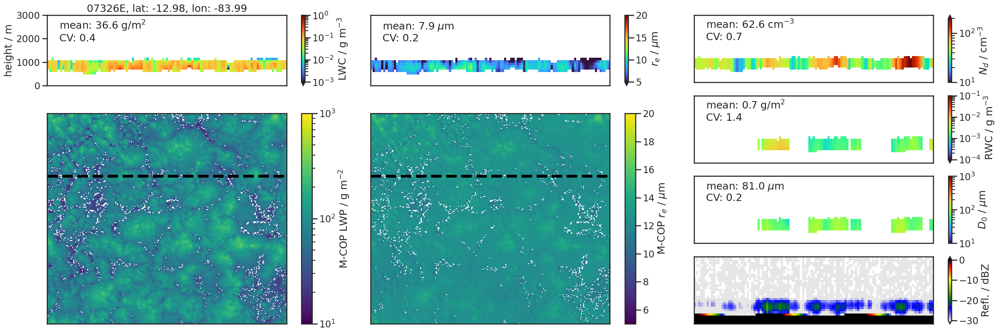

Loading ACM-CAP data via MAAP...
Accessing 1 items (limited by max_items).
1 items found that matched the query.
Found .h5 file in enclosure_h5: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/ACM_CAP_2B/BA/2024/08/03/ECA_EXBA_ACM_CAP_2B_20240803T131837Z_20250905T144107Z_01036E/ECA_EXBA_ACM_CAP_2B_20240803T131837Z_20250905T144107Z_01036E/ECA_EXBA_ACM_CAP_2B_20240803T131837Z_20250905T144107Z_01036E.h5
HDF5 URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/ACM_CAP_2B/BA/2024/08/03/ECA_EXBA_ACM_CAP_2B_20240803T131837Z_20250905T144107Z_01036E/ECA_EXBA_ACM_CAP_2B_20240803T131837Z_20250905T144107Z_01036E/ECA_EXBA_ACM_CAP_2B_20240803T131837Z_20250905T144107Z_01036E.h5
Orbit: 01036E
Fetching ESA MAAP token...
p1eL7uonXs6MDxtGbgKdPVRAmnGxHpVE
Dataset URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/ACM_CAP_2B/BA/2024/08/03/ECA_EXBA_ACM_CAP_2B_20240803T131837Z_20250905T144107Z_01036E/ECA_EXBA_ACM_CAP_2B_20240803T131837Z_20250905T144107Z_0

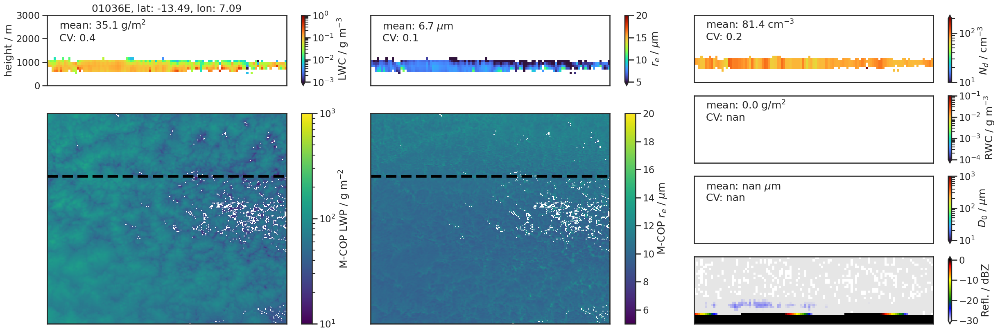

Loading ACM-CAP data via MAAP...
Accessing 1 items (limited by max_items).
1 items found that matched the query.
Found .h5 file in enclosure_h5: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/ACM_CAP_2B/BA/2024/09/04/ECA_EXBA_ACM_CAP_2B_20240904T195102Z_20250907T184325Z_01538E/ECA_EXBA_ACM_CAP_2B_20240904T195102Z_20250907T184325Z_01538E/ECA_EXBA_ACM_CAP_2B_20240904T195102Z_20250907T184325Z_01538E.h5
HDF5 URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/ACM_CAP_2B/BA/2024/09/04/ECA_EXBA_ACM_CAP_2B_20240904T195102Z_20250907T184325Z_01538E/ECA_EXBA_ACM_CAP_2B_20240904T195102Z_20250907T184325Z_01538E/ECA_EXBA_ACM_CAP_2B_20240904T195102Z_20250907T184325Z_01538E.h5
Orbit: 01538E
Fetching ESA MAAP token...
p1eL7uonXs6MDxtGbgKdPVRAmnGxHpVE
Dataset URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/ACM_CAP_2B/BA/2024/09/04/ECA_EXBA_ACM_CAP_2B_20240904T195102Z_20250907T184325Z_01538E/ECA_EXBA_ACM_CAP_2B_20240904T195102Z_20250907T184325Z_0

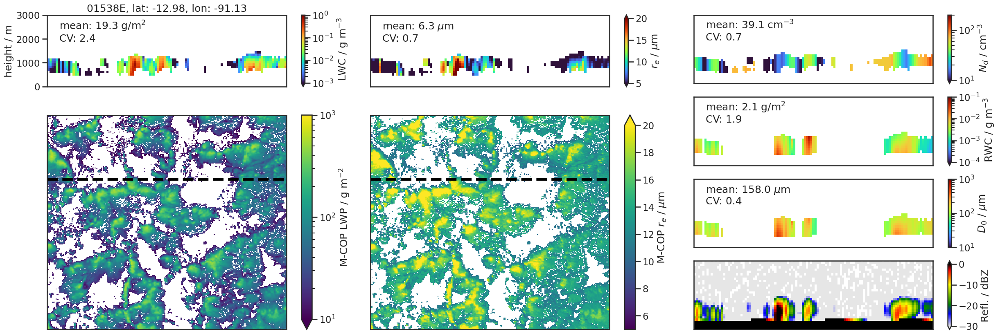

Loading ACM-CAP data via MAAP...
Accessing 1 items (limited by max_items).
1 items found that matched the query.
Found .h5 file in enclosure_h5: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/ACM_CAP_2B/BA/2025/07/17/ECA_EXBA_ACM_CAP_2B_20250717T195043Z_20250717T230247Z_06455E/ECA_EXBA_ACM_CAP_2B_20250717T195043Z_20250717T230247Z_06455E/ECA_EXBA_ACM_CAP_2B_20250717T195043Z_20250717T230247Z_06455E.h5
HDF5 URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/ACM_CAP_2B/BA/2025/07/17/ECA_EXBA_ACM_CAP_2B_20250717T195043Z_20250717T230247Z_06455E/ECA_EXBA_ACM_CAP_2B_20250717T195043Z_20250717T230247Z_06455E/ECA_EXBA_ACM_CAP_2B_20250717T195043Z_20250717T230247Z_06455E.h5
Orbit: 06455E
Fetching ESA MAAP token...
p1eL7uonXs6MDxtGbgKdPVRAmnGxHpVE
Dataset URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/ACM_CAP_2B/BA/2025/07/17/ECA_EXBA_ACM_CAP_2B_20250717T195043Z_20250717T230247Z_06455E/ECA_EXBA_ACM_CAP_2B_20250717T195043Z_20250717T230247Z_0

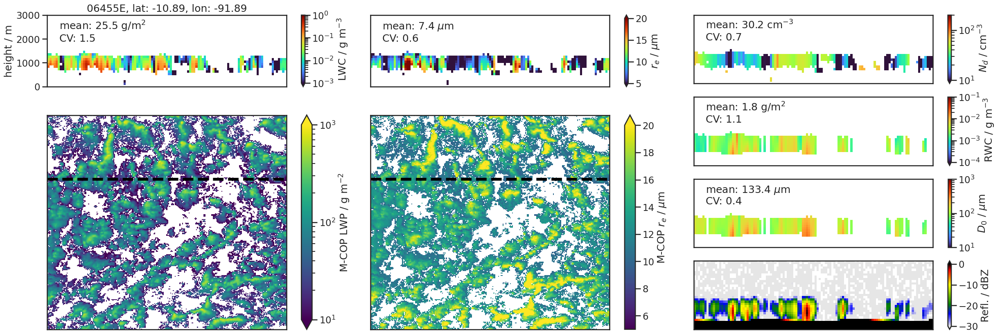

In [44]:
for i in range(len(examples)):
    orbit = examples[i]['orbit']
    lat_min = examples[i]['lat_min']
    lat_max = examples[i]['lat_max']
    scene_id = dffil[(dffil.orbit == orbit) & (dffil.lat_min <= lat_min) & (dffil.lat_max >= lat_max)].scene_id.values[0]

    plot_ACMCAP_MCOP_for_scene_id(scene_id)